# 🌾 Tunisian Smart Crop Monitoring & Irrigation Intelligence

<div style="background: linear-gradient(135deg, #163611 0%, #2e591c 100%); padding: 22px; border-radius: 12px; color: white; margin-bottom: 20px;">
<h2 style="color: white; margin-top: 0;">🇹🇳 🇯🇵 Japan–Tunisia Agricultural Innovation Project</h2>
<p style="font-size: 15px; margin-bottom: 6px;">
An end-to-end precision agriculture and agro-meteorological intelligence framework designed for Tunisian semi-arid drylands.
Built on <b>real in-situ soil and climate sensor streams</b> from the Tunisian Ministry of Agriculture (DGACTA), augmented with <b>NASA POWER</b> agroclimatology reanalysis, and powered by <b>FAO-56</b> irrigation engineering principles.
</p>
</div>

### 🎯 Key Engineering & Scientific Principles

1. **Empirical Authenticity**: All agro-climatic time series originate from real national monitoring stations in Tunisia (*Kairouan El Alâa, Kairouan Sbikha, Sidi Bouzid Rayhana, Siliana Bargou, and Sousse Chott Meriam*). No synthetic observations are presented as real data.
2. **Robust Long-Format Sensor Disentanglement**: The Tunisian schema (`Date`, `nom_ar`, `nom_fr`, `unite`, `valeur`) is strictly parsed using **both sensor description and unit**. We decouple co-located measurements: Volumetric Water Content ($\text{VWC }\%$), Sensor Potential ($\text{mV}$), and Soil Temperature ($^\circ\text{C}$).
3. **Rigorous Quality Audit**: Sensor depths ($10, 20, 30, 60\text{ cm}$) are extracted from original resource titles. When depth is unrecorded, it is flagged as `None`, never assumed. The historical "100% duplicate" artifact is resolved as an unpartitioned co-located sensor issue.
4. **Genuinely Hourly Time-Series Machine Learning**: Targets for $1\text{h}$ forecasting are constructed only when consecutive timestamps are genuinely one hour apart ($0.8\text{h} \le \Delta t \le 1.2\text{h}$). All three candidate models (Persistence Baseline, Random Forest, HistGradientBoosting) are evaluated on identical test timestamps under strict chronological splits.
5. **Legitimate Model Selection & Persistence Dominance**: Because soil moisture has high physical inertia under slow drying, the **Persistence Baseline** is the legitimate statistical winner ($\text{MAE} \approx 0.019\%$, $R^2 \approx 0.99$). It is explicitly selected and saved as the best model artifact with complete metadata, without fabricating machine learning superiority.
6. **Two-Tier FAO-56 Irrigation Engine**:
   - **Part A (Crop Water Demand)**: Reference $\text{ET}_o$ (Hargreaves-Samani) and stage-specific crop evapotranspiration ($\text{ET}_c = K_c \times \text{ET}_o$) with empirical effective rainfall ($P_{\text{eff}}$).
   - **Part B (Root-Zone Water Balance)**: Full soil water deficit ($D_r$), Readily Available Water ($\text{RAW}$), and stress coefficient ($K_s$). Explicitly returns a parameter diagnostics error if field capacity or wilting point are missing, avoiding silent arbitrary defaults.


> ### 🆕 v3 – FARMLINK Module 5 completion (this version)
> The original pipeline (sections 2–12) and the v2 crop-aware module (12A–12G) are **kept unchanged**. v3 adds:
> **(a)** a self-installing, notebook-independent package `FARMLINK_Module5_Deliverables/` (`engine/`, `crop_knowledge/`, `api/`, `tests/`),
> **(b)** a hardened DGACTA/CKAN + weather acquisition layer (retries, timeouts, caching, validation, provenance; Open-Meteo → NASA POWER fallback that is *recorded*),
> **(c)** a searchable multi-crop knowledge base, a multi-zone farm registry, farm-wide prioritisation, limited-water allocation and a farm dashboard (sections 12H–12N),
> **(d)** an export + fresh-process test + ZIP verification step.
>
> **Data honesty switch.** Every acquisition result is printed with its provenance. If the notebook cannot reach the internet *and* has no cache, it **stops with an explanation**.
> Only when the environment variable `FARMLINK_ALLOW_FIXTURE=1` is set does it generate a loudly-labelled **synthetic fixture** (used to prove the code runs end to end offline); such output is never real Tunisian data and never a validation.

## 2. 🔧 Environment Setup & Reproducibility


In [1]:
import os
import sys
import json
import time
import warnings
import re
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', palette='mako', font_scale=1.05)
except ImportError:
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except Exception:
        plt.style.use('ggplot')

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pickle

try:
    import requests
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
    HAS_REQUESTS = True
except ImportError:
    HAS_REQUESTS = False

# Visualization aesthetics
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 110

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Kaggle working paths
BASE_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('.')
DATA_DIR = BASE_DIR / 'data' / 'tunisia'
RESULTS_DIR = BASE_DIR / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
MODELS_DIR = BASE_DIR / 'models'

for d in [DATA_DIR, RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("✅ Environment initialized:")
print(f"   Python {sys.version.split()[0]} | Pandas {pd.__version__} | NumPy {np.__version__}")
print(f"   Working directory: {BASE_DIR.resolve()}")

✅ Environment initialized:
   Python 3.13.16 | Pandas 2.3.3 | NumPy 2.1.3
   Working directory: /kaggle/working


## 2B. 📦 Install the FARMLINK package & check connectivity
The package is embedded below (base64 zip, generated by the build script) so the notebook is self-contained on Kaggle. It is extracted to `BASE_DIR/FARMLINK_Module5_Deliverables` and imported like any library (`engine`, no notebook state).

In [2]:
# AUTO-GENERATED PAYLOAD (zip of FARMLINK_Module5_Deliverables, base64). Do not edit.
_FARMLINK_PAYLOAD = "..."

In [3]:
import base64, io, zipfile, os, sys
from pathlib import Path

PKG_DIR = BASE_DIR / 'FARMLINK_Module5_Deliverables'
if not (PKG_DIR / 'engine' / '__init__.py').exists():
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(_FARMLINK_PAYLOAD))) as _z:
        _z.extractall(PKG_DIR)
if str(PKG_DIR) not in sys.path:
    sys.path.insert(0, str(PKG_DIR))
import engine
from engine import data_sources as DS
print(f"✅ FARMLINK engine v{engine.__version__} installed at {PKG_DIR}")

ALLOW_FIXTURE = os.environ.get('FARMLINK_ALLOW_FIXTURE') == '1'   # default False: never fabricate data silently

def _probe(url):
    try:
        r = requests.get(url, timeout=8, allow_redirects=True)
        return f"reachable (HTTP {r.status_code})"
    except Exception as e:
        return f"UNREACHABLE ({type(e).__name__})"
CONNECTIVITY = {
    'catalog.data.gov.tn (DGACTA / CKAN)': _probe('https://catalog.data.gov.tn/'),
    'api.open-meteo.com': _probe('https://api.open-meteo.com/'),
    'power.larc.nasa.gov (NASA POWER)': _probe('https://power.larc.nasa.gov/'),
}
for k, v in CONNECTIVITY.items():
    print(f"  {k:<40} {v}")
if all(v.startswith('UNREACHABLE') for v in CONNECTIVITY.values()):
    print("\n⚠️ No external host is reachable from this environment.")
    print("   " + DS.KAGGLE_INTERNET_HELP)
    print(f"   Synthetic fixture allowed (FARMLINK_ALLOW_FIXTURE=1)? {ALLOW_FIXTURE}")

✅ FARMLINK engine v2.0.0 installed at /kaggle/working/FARMLINK_Module5_Deliverables
  catalog.data.gov.tn (DGACTA / CKAN)      UNREACHABLE (SSLError)
  api.open-meteo.com                       reachable (HTTP 400)
  power.larc.nasa.gov (NASA POWER)         reachable (HTTP 200)


## 3. 📡 Automated CKAN Data Acquisition (Tunisian Ministry of Agriculture)

We access official agro-climatic stations published by the **DGACTA** (*Direction Générale de l'Aménagement et de la Conservation des Terres Agricoles*) under the Tunisian Ministry of Agriculture.
The API retrieves metadata and CSV download links across 5 key agricultural governorates:
- **Kairouan – El Alâa**: Central olive/cereal dryland zone.
- **Kairouan – Sbikha**: Central semi-arid irrigation perimeter.
- **Sidi Bouzid – Rayhana**: Major vegetable and fruit hub of central Tunisia.
- **Siliana – Bargou**: Cereal and foothill arboriculture basin.
- **Sousse – Chott Meriam**: Coastal horticultural and Mediterranean agricultural institute zone.


In [4]:
CKAN_API = "https://catalog.data.gov.tn/api/3/action/package_show"

STATIONS_CONFIG = {
    "Kairouan_ElAlaa": {
        "package_id": "771dc061-9d84-426f-915e-b1e02403f9cb",
        "station": "El Alâa",
        "governorate": "Kairouan",
        "lat": 35.614, "lon": 9.567
    },
    "Kairouan_Sbikha": {
        "package_id": "6b6067ed-a005-46c5-be3d-98ec9d0cab2c",
        "station": "Sbikha",
        "governorate": "Kairouan",
        "lat": 35.932, "lon": 10.027
    },
    "SidiBouzid_Rayhana": {
        "package_id": "617e938d-c59a-4108-84e7-d634d98e1152",
        "station": "Rayhana",
        "governorate": "Sidi Bouzid",
        "lat": 34.930, "lon": 9.330
    },
    "Siliana_Bargou": {
        "package_id": "4d6a078a-c041-479a-845b-5a682ad12dd3",
        "station": "Bargou",
        "governorate": "Siliana",
        "lat": 36.088, "lon": 9.585
    },
    "Sousse_ChottMeriam": {
        "package_id": "90e0a429-1b92-43ba-bf5c-3604c8de9e0f",
        "station": "Chott Meriam",
        "governorate": "Sousse",
        "lat": 35.918, "lon": 10.558
    }
}

manifest_records = []

print("=" * 75)
print("CKAN PORTAL DATA DISCOVERY & STREAMING")
print("=" * 75)

for skey, sinfo in STATIONS_CONFIG.items():
    pkg_id = sinfo["package_id"]
    station_name = sinfo["station"]
    print(f"\n📍 {station_name} ({sinfo['governorate']}) | Package: {pkg_id[:12]}...")

    url = f"{CKAN_API}?id={pkg_id}"
    pkg_data = None

    if HAS_REQUESTS:
        try:
            r = requests.get(url, timeout=25, verify=False)
            if r.status_code == 200 and r.json().get('success'):
                pkg_data = r.json().get('result', {})
        except Exception as e:
            print(f"   ⚠️ CKAN connection note: {e}")

    if not pkg_data:
        existing = list(DATA_DIR.glob(f"{skey}_*.csv"))
        if existing:
            print(f"   ℹ️ Offline cache active: {len(existing)} pre-downloaded station files.")
        else:
            print(f"   ❌ No network and no cached files for {station_name}.")
        continue

    resources = pkg_data.get('resources', [])
    licence = pkg_data.get('license_title', 'Open Data DGACTA / Ministère Agriculture Tunisie')
    print(f"   Found {len(resources)} sensor resource(s) in catalog.")

    for res in resources:
        rname = res.get('name', 'unnamed')
        rurl = res.get('url', '')
        rid = res.get('id', '')[:8]
        rfmt = res.get('format', 'CSV').upper()

        fname = f"{skey}_{rid}.csv"
        fpath = DATA_DIR / fname

        status = "EXISTS"
        size_bytes = 0

        if not fpath.exists() and HAS_REQUESTS:
            try:
                res_resp = requests.get(rurl, timeout=35, verify=False)
                if res_resp.status_code == 200:
                    with open(fpath, "wb") as f:
                        f.write(res_resp.content)
                    size_bytes = len(res_resp.content)
                    status = "DOWNLOADED"
                else:
                    status = f"HTTP_{res_resp.status_code}"
            except Exception as ex:
                status = f"ERROR: {str(ex)[:30]}"
        elif fpath.exists():
            size_bytes = fpath.stat().st_size

        print(f"   • {rname[:45]:<45} | {status} ({size_bytes:,} bytes)")
        manifest_records.append({
            'station_key': skey,
            'station': station_name,
            'governorate': sinfo['governorate'],
            'resource_name': rname,
            'resource_id': res.get('id'),
            'format': rfmt,
            'url': rurl,
            'local_file': fname,
            'file_size_bytes': size_bytes,
            'status': status,
            'licence': licence
        })

if manifest_records:
    df_manifest = pd.DataFrame(manifest_records)
    df_manifest.to_csv(BASE_DIR / 'data' / 'source_manifest.csv', index=False)
    print(f"\n📋 Saved source manifest: {BASE_DIR / 'data' / 'source_manifest.csv'}")
elif (DATA_DIR / 'manifest_inspect.json').exists():
    with open(DATA_DIR / 'manifest_inspect.json', 'r', encoding='utf-8') as f:
        m_items = json.load(f)
        for m in m_items:
            m['local_file'] = m.get('file', '')
        df_manifest = pd.DataFrame(m_items)
    df_manifest.to_csv(BASE_DIR / 'data' / 'source_manifest.csv', index=False)
    print(f"\n📋 Loaded offline manifest from cache ({len(df_manifest)} entries).")
elif (BASE_DIR / 'data' / 'source_manifest.csv').exists() and (BASE_DIR / 'data' / 'source_manifest.csv').stat().st_size > 10:
    df_manifest = pd.read_csv(BASE_DIR / 'data' / 'source_manifest.csv')
    print(f"\n📋 Loaded existing source manifest ({len(df_manifest)} entries).")
else:
    df_manifest = pd.DataFrame()
    print("\n⚠️ No manifest available.")

CKAN PORTAL DATA DISCOVERY & STREAMING

📍 El Alâa (Kairouan) | Package: 771dc061-9d8...
   Found 5 sensor resource(s) in catalog.
   • Capteur de pluviométrie dans la station clima | DOWNLOADED (195 bytes)
   • Capteur d'environnement de la station climati | DOWNLOADED (592 bytes)
   • Capteur d'humidité du sol à 10 cm de la stati | DOWNLOADED (212 bytes)
   • Capteur d'humidité du sol à 20 cm de la stati | DOWNLOADED (212 bytes)
   • Capteur d'humidité du sol à 30 cm de la stati | DOWNLOADED (212 bytes)

📍 Sbikha (Kairouan) | Package: 6b6067ed-a00...
   Found 5 sensor resource(s) in catalog.
   • Capteur de pluviométrie dans la station clima | DOWNLOADED (411 bytes)
   • Capteur d'humidité du sol à 10 cm de la stati | DOWNLOADED (647 bytes)
   • Capteur d'humidité du sol à 20 cm de la stati | DOWNLOADED (647 bytes)
   • Capteur d'humidité du sol à 30 cm de la stati | DOWNLOADED (647 bytes)
   • Capteur d'environnement de la station climati | DOWNLOADED (1,946 bytes)

📍 Rayhana (Sidi B

## 3B. 🛰️ Hardened DGACTA acquisition (retries, timeouts, redirects, validation, cache, provenance)
Uses `engine.data_sources`. Depth and channel are taken **from resource metadata only** (never defaulted); millivolt channels stay millivolts (never VWC). The table below is the *only* statement of what was actually downloaded in this run.

In [5]:
import shutil, hashlib
STATION_KEY_BY_PKG = {v['package_id']: k for k, v in DS.STATIONS.items()}
CKAN_CACHE = DATA_DIR / '_ckan_cache'
sess = DS.make_session(retries=3, backoff=1.0)
ACQ_ROWS, NEW_MANIFEST = [], []

for skey, sinfo in STATIONS_CONFIG.items():
    dk = STATION_KEY_BY_PKG[sinfo['package_id']]
    try:
        pk = DS.fetch_station_package(dk, sess, CKAN_CACHE, allow_cache=True)
    except DS.DownloadError as e:
        ACQ_ROWS.append({'station': sinfo['station'], 'resource': '(package_show)', 'status': 'PACKAGE_FAILED', 'error': str(e)[:160]})
        continue
    tbl = DS.discover_resources(pk['package'])
    for _, r in tbl.iterrows():
        row = {'station': sinfo['station'], 'resource': r['name'], 'resource_id': r['resource_id'], 'depth_cm': r['depth_cm'], 'channel': r['channel'],
               'package_from_cache': pk['provenance']['from_cache']}
        local = f"{skey}_{str(r['resource_id'])[:8]}.csv"
        if not r['is_tabular'] or not r['url']:
            row['status'] = 'SKIPPED_NOT_TABULAR'
        elif (DATA_DIR / local).exists():
            row.update(status='ALREADY_PRESENT', bytes=(DATA_DIR / local).stat().st_size)
        else:
            try:
                p, prov = DS.download_resource(r.to_dict(), sess, CKAN_CACHE / 'raw', allow_cache=True)
                shutil.copyfile(p, DATA_DIR / local)
                row.update(status='CACHE_FALLBACK' if prov['from_cache'] else 'DOWNLOADED', bytes=prov.get('bytes'), sha256=prov.get('sha256', '')[:12])
            except DS.DownloadError as e:
                row.update(status='FAILED', error=str(e)[:160])
        if row['status'] in ('DOWNLOADED', 'CACHE_FALLBACK', 'ALREADY_PRESENT'):
            NEW_MANIFEST.append({'station_key': skey, 'station': sinfo['station'], 'governorate': sinfo['governorate'], 'resource_name': r['name'],
                                 'resource_id': r['resource_id'], 'format': r['format'], 'url': r['url'], 'local_file': local, 'depth_cm_metadata': r['depth_cm'],
                                 'channel_metadata': r['channel'], 'status': row['status']})
        ACQ_ROWS.append(row)

ACQ_DF = pd.DataFrame(ACQ_ROWS)
ACQ_DF.to_csv(RESULTS_DIR / 'acquisition_report.csv', index=False)
print("=" * 75); print("ACQUISITION REPORT (this run)"); print("=" * 75)
if len(ACQ_DF):
    print(ACQ_DF.groupby(['station', 'status']).size().unstack(fill_value=0).to_string())
else:
    print("No resource rows (no package could be read).")

if NEW_MANIFEST:
    nm = pd.DataFrame(NEW_MANIFEST)
    df_manifest = pd.concat([df_manifest, nm], ignore_index=True).drop_duplicates(subset=['local_file'], keep='last') if len(df_manifest) else nm
    df_manifest.to_csv(BASE_DIR / 'data' / 'source_manifest.csv', index=False)

# remove stale fixture files if real data is present
REAL_FILES = [f for f in DATA_DIR.glob('*.csv') if not f.name.startswith('FIXTURE_')]
if REAL_FILES:
    for f in DATA_DIR.glob('FIXTURE_*.csv'): f.unlink()
    DATA_PROVENANCE = 'REAL_DGACTA'
elif ALLOW_FIXTURE:
    DATA_PROVENANCE = 'SYNTHETIC_FIXTURE'
    rng = np.random.default_rng(1)
    idx = pd.date_range('2026-11-13 18:00', '2026-11-21 14:00', freq='h'); n = len(idx); hr = idx.hour.values
    base = {10: 16.2, 30: 5.4, 60: 7.0}; man = []
    for depth, b in base.items():
        vwc = np.round(b - 0.004 * np.arange(n) * (depth == 10) + 0.05 * np.sin(2 * np.pi * hr / 24) + rng.normal(0, 0.01, n), 2)
        frames = [pd.DataFrame({'Date': idx.strftime('%Y-%m-%d %H:%M:%S'), 'valeur': vwc, 'nom_fr': 'Contenu volumique en eau', 'nom_ar': 'x', 'unite': '%'}),
                  pd.DataFrame({'Date': idx.strftime('%Y-%m-%d %H:%M:%S'), 'valeur': 500.0 + depth, 'nom_fr': 'Humidité du sol', 'nom_ar': 'x', 'unite': 'mV'}),
                  pd.DataFrame({'Date': idx.strftime('%Y-%m-%d %H:%M:%S'), 'valeur': np.round(21.8 + 2 * np.sin(2 * np.pi * (hr - 14) / 24), 2), 'nom_fr': 'Température du sol', 'nom_ar': 'x', 'unite': '°C'})]
        fname = f"FIXTURE_Sousse_ChottMeriam_{depth}cm.csv"
        pd.concat(frames).to_csv(DATA_DIR / fname, index=False)
        man.append({'station_key': 'Sousse_ChottMeriam', 'station': 'Chott Meriam', 'governorate': 'Sousse', 'resource_name': f'Humidité du sol {depth} cm (SYNTHETIC FIXTURE)',
                    'local_file': fname, 'status': 'SYNTHETIC_FIXTURE'})
    df_manifest = pd.DataFrame(man)
    print("\n" + "!" * 75)
    print("!! SYNTHETIC FIXTURE ACTIVE: no real DGACTA file was obtained in this environment.")
    print("!! Everything downstream of this cell is a CODE-PATH DEMONSTRATION, not Tunisian data.")
    print("!" * 75)
else:
    DATA_PROVENANCE = 'NONE'
    raise RuntimeError("No DGACTA data: the portal was unreachable and no cached files exist. " + DS.KAGGLE_INTERNET_HELP +
                       " Alternatively attach previously downloaded CSVs to DATA_DIR. (Set FARMLINK_ALLOW_FIXTURE=1 only for an offline code-path demo.)")
print(f"\nDATA_PROVENANCE = {DATA_PROVENANCE}")

ACQUISITION REPORT (this run)
status        PACKAGE_FAILED
station                     
Bargou                     1
Chott Meriam               1
El Alâa                    1
Rayhana                    1
Sbikha                     1

DATA_PROVENANCE = REAL_DGACTA


## 4. 🔍 Robust Long-Format Sensor Parser & Data Quality Audit

### Disentangling the Tunisian Sensor Architecture

The DGACTA CSV files adhere to a long format:
`Date, nom_ar, nom_fr, unite, valeur`

A single physical soil moisture probe file outputs **three distinct co-located channels** at each observation timestamp:
1. `nom_fr = "Contenu volumétrique d'eau"` with `unite = "%"` $\to$ **Volumetric Water Content (VWC)**.
2. `nom_fr = "L'humidité du sol"` with `unite = "mV"` $\to$ **Raw Sensor Voltage**.
3. `nom_fr = "Température"` with `unite = "°C"` $\to$ **Soil Temperature**.

#### Strict Implementation Rules
- **Dual Classification**: Measurements are identified using **both `nom_fr` and `unite`**.
- **No Voltage Misinterpretation**: Raw millivolt sensor signals ($15 - 842\text{ mV}$) are strictly stored under `voltage_mV` and are **never converted to VWC** without a documented laboratory calibration curve.
- **Strict Depth Extraction**: Sensor depth ($10, 20, 30, 60\text{ cm}$) is extracted from the resource title (`Capteur d'humidité du sol à 10 cm...`). When depth is not specified (e.g. for rain, weather, leaf wetness), depth is recorded as `None` (NaN), **never defaulted or assumed**.
- **Unclassified Audit**: A separate report (`results/unclassified_measurements_report.csv`) tracks any record that fails parsing.


In [6]:
# ============================================================================
# 4.1 — Strict Long-Format Sensor Parser
# ============================================================================

def extract_depth_strict(resource_name, filename):
    """Extract sensor depth strictly from resource title or filename."""
    combined = f"{resource_name} {filename}".lower()
    match = re.search(r'(\d+)\s*cm', combined)
    if match:
        return int(match.group(1))
    return None  # Never assume or default a missing depth

def parse_all_tunisian_sensor_files(data_dir=DATA_DIR, manifest_df=None):
    """
    Strictly parse all Tunisian CSV files into domain-separated datasets.
    Requires dual matching of nom_fr and unite.
    """
    csv_files = sorted(list(data_dir.glob("*.csv")))

    res_map = {}
    if manifest_df is not None and len(manifest_df) > 0:
        for _, r in manifest_df.iterrows():
            k = r.get('local_file', r.get('file'))
            if pd.notna(k):
                res_map[k] = r
    elif (DATA_DIR / 'manifest_inspect.json').exists():
        with open(DATA_DIR / 'manifest_inspect.json', 'r', encoding='utf-8') as f:
            for r in json.load(f):
                res_map[r.get('file')] = r

    classified_records = []
    unclassified_records = []

    for fpath in csv_files:
        meta = res_map.get(fpath.name, {})
        station = meta.get('station', fpath.stem.split('_')[0])
        gov = meta.get('governorate', '')
        res_name = meta.get('resource_name', fpath.stem)
        depth = extract_depth_strict(res_name, fpath.stem)

        df = None
        for enc in ['utf-8-sig', 'utf-8', 'latin-1', 'cp1252']:
            try:
                df = pd.read_csv(fpath, encoding=enc)
                break
            except Exception:
                pass
        if df is None:
            continue

        df.columns = [c.strip().replace('\ufeff', '') for c in df.columns]
        if 'Date' not in df.columns or 'valeur' not in df.columns or 'nom_fr' not in df.columns:
            continue

        df['timestamp'] = pd.to_datetime(df['Date'], errors='coerce')
        df['valeur'] = pd.to_numeric(df['valeur'], errors='coerce')
        res_lower = res_name.lower()

        for _, r in df.iterrows():
            ts = r['timestamp']
            if pd.isna(ts):
                unclassified_records.append({
                    'source_file': fpath.name,
                    'resource_name': res_name,
                    'nom_fr': r.get('nom_fr'),
                    'unite': r.get('unite'),
                    'valeur': r.get('valeur'),
                    'rejection_reason': 'INVALID_TIMESTAMP'
                })
                continue

            val = r['valeur']
            unite = str(r['unite']).strip() if pd.notna(r['unite']) else ""
            nom_fr = str(r['nom_fr']).strip() if pd.notna(r['nom_fr']) else ""
            nom_ar = str(r['nom_ar']).strip() if pd.notna(r['nom_ar']) else ""
            nom_fr_lower = nom_fr.lower()

            domain = None
            measurement_type = None

            # --- 1. Soil Probes ---
            if ('humidit' in res_lower and 'sol' in res_lower) or ('sol' in res_lower) or ('contenu volum' in nom_fr_lower) or ('humidit' in nom_fr_lower and unite.lower() == 'mv'):
                domain = 'soil_moisture_probe'
                if ('contenu volum' in nom_fr_lower) and (unite == '%'):
                    measurement_type = 'VWC'
                elif ('humidit' in nom_fr_lower) and (unite.lower() == 'mv'):
                    measurement_type = 'voltage_mV'
                elif ('temp' in nom_fr_lower) and (unite in ['°C', '°c']):
                    measurement_type = 'soil_temperature_C'
                else:
                    measurement_type = 'unclassified_soil_probe'

            # --- 2. Rainfall Probes ---
            elif 'pluvio' in res_lower or 'pluie' in nom_fr_lower:
                domain = 'rainfall_sensor'
                if 'intensit' in nom_fr_lower and unite == 'mm/h':
                    measurement_type = 'rain_intensity_mm_h'
                elif 'quotidienne' in nom_fr_lower and unite == 'mm':
                    measurement_type = 'rain_daily_mm'
                elif 'totale' in nom_fr_lower and unite == 'mm':
                    measurement_type = 'rain_cumulative_mm'
                else:
                    measurement_type = 'rainfall_other'

            # --- 3. Leaf Wetness ---
            elif 'mouillage' in res_lower or 'foliaire' in res_lower or 'mouillage' in nom_fr_lower:
                domain = 'leaf_wetness_sensor'
                if 'supérieure' in nom_fr_lower and unite == '%':
                    measurement_type = 'leaf_wetness_upper_pct'
                elif 'inférieure' in nom_fr_lower and unite == '%':
                    measurement_type = 'leaf_wetness_lower_pct'
                else:
                    measurement_type = 'leaf_wetness_other'

            # --- 4. Environmental Station ---
            elif 'environ' in res_lower or any(kw in nom_fr_lower for kw in ['vent', 'rayonnement', 'pression', 'rosée', 'évapotranspiration']):
                domain = 'environmental_station'
                if 'vitesse' in nom_fr_lower and unite == 'm/s':
                    measurement_type = 'wind_speed_m_s'
                elif 'direction' in nom_fr_lower and unite == 'Deg':
                    measurement_type = 'wind_direction_deg'
                elif 'temp' in nom_fr_lower and unite in ['°C', '°c']:
                    measurement_type = 'air_temperature_C'
                elif 'humidit' in nom_fr_lower and unite == '%':
                    measurement_type = 'relative_humidity_pct'
                elif 'rayonnement' in nom_fr_lower and unite == 'W/m²':
                    measurement_type = 'solar_radiation_W_m2'
                elif 'pression' in nom_fr_lower:
                    measurement_type = 'atmospheric_pressure'
                elif 'évapotranspiration horaire' in nom_fr_lower:
                    measurement_type = 'station_eto_hourly_mm'
                elif 'évapotranspiration journalière' in nom_fr_lower:
                    measurement_type = 'station_eto_daily_mm'
                elif 'rosée' in nom_fr_lower:
                    measurement_type = 'dew_point_C'
                else:
                    measurement_type = 'environment_other'

            # --- 5. Water Level ---
            elif 'niveau' in res_lower or 'niveau' in nom_fr_lower:
                domain = 'water_level_sensor'
                measurement_type = nom_fr
            else:
                domain = 'unclassified'
                measurement_type = 'unknown'

            entry = {
                'timestamp': ts,
                'station': station,
                'governorate': gov,
                'domain': domain,
                'measurement_type': measurement_type,
                'sensor_depth_cm': depth,
                'nom_fr': nom_fr,
                'nom_ar': nom_ar,
                'valeur': val,
                'unite': unite,
                'resource_name': res_name,
                'source_file': fpath.name
            }

            if domain == 'unclassified' or 'unclassified' in measurement_type:
                unclassified_records.append(entry)
            else:
                classified_records.append(entry)

    return pd.DataFrame(classified_records), pd.DataFrame(unclassified_records)

df_classified, df_unclassified = parse_all_tunisian_sensor_files(DATA_DIR, df_manifest)

print("=" * 75)
print("PARSER EXECUTION AUDIT")
print("=" * 75)
print(f"Total Records Extracted & Classified: {len(df_classified):,}")
print(f"Total Unclassified/Rejected Records:  {len(df_unclassified):,}")

# Export unclassified report
df_unclassified.to_csv(RESULTS_DIR / 'unclassified_measurements_report.csv', index=False)
print(f"📋 Unclassified report saved: {RESULTS_DIR / 'unclassified_measurements_report.csv'}")

# Export corrected Tunisian soil moisture dataset
df_sm_corrected = df_classified[df_classified['domain'] == 'soil_moisture_probe'].copy()
df_sm_corrected.to_csv(BASE_DIR / 'data' / 'tunisia_soil_moisture_corrected.csv', index=False)
print(f"💾 Corrected soil moisture exported: {BASE_DIR / 'data' / 'tunisia_soil_moisture_corrected.csv'}")

PARSER EXECUTION AUDIT
Total Records Extracted & Classified: 4,648
Total Unclassified/Rejected Records:  0
📋 Unclassified report saved: /kaggle/working/results/unclassified_measurements_report.csv
💾 Corrected soil moisture exported: /kaggle/working/data/tunisia_soil_moisture_corrected.csv


In [7]:
# ============================================================================
# 4.2 — Comprehensive Data Quality Report
# ============================================================================

dq_rows = []

for station in sorted(df_sm_corrected['station'].unique()):
    st_df = df_sm_corrected[df_sm_corrected['station'] == station]
    valid_depths = [d for d in st_df['sensor_depth_cm'].unique() if pd.notna(d)]

    for depth in sorted(valid_depths):
        d_df = st_df[st_df['sensor_depth_cm'] == depth]
        for mtype in sorted(d_df['measurement_type'].unique()):
            sub = d_df[d_df['measurement_type'] == mtype].sort_values('timestamp')

            # Duplicates check within identical physical channel
            n_dups = sub.duplicated(subset=['timestamp']).sum()

            # Temporal continuity: gaps > 6 hours
            diffs_h = sub['timestamp'].diff().dt.total_seconds() / 3600.0
            gaps_gt_6h = (diffs_h > 6.0).sum()

            # Physical range validation
            if mtype == 'VWC':
                invalid_n = ((sub['valeur'] < 0) | (sub['valeur'] > 100)).sum()
            elif mtype == 'voltage_mV':
                invalid_n = ((sub['valeur'] < 0) | (sub['valeur'] > 5000)).sum()
            elif mtype == 'soil_temperature_C':
                invalid_n = ((sub['valeur'] < -10) | (sub['valeur'] > 60)).sum()
            else:
                invalid_n = 0

            dq_rows.append({
                'station': station,
                'sensor_depth_cm': int(depth),
                'measurement_type': mtype,
                'unit': sub['unite'].iloc[0] if len(sub) > 0 else '',
                'total_records': len(sub),
                'min_timestamp': sub['timestamp'].min(),
                'max_timestamp': sub['timestamp'].max(),
                'missing_values': sub['valeur'].isna().sum(),
                'duplicate_timestamps': n_dups,
                'physically_invalid': invalid_n,
                'gaps_gt_6h': gaps_gt_6h,
                'mean_value': round(sub['valeur'].mean(), 2),
                'min_value': round(sub['valeur'].min(), 2),
                'max_value': round(sub['valeur'].max(), 2)
            })

df_quality_report = pd.DataFrame(dq_rows)
df_quality_report.to_csv(RESULTS_DIR / 'data_quality_report_corrected.csv', index=False)

print("=" * 75)
print("FORMAL SENSOR QUALITY AUDIT (EXCERPT)")
print("=" * 75)
print(df_quality_report[['station', 'sensor_depth_cm', 'measurement_type', 'unit', 'total_records', 'duplicate_timestamps', 'gaps_gt_6h', 'mean_value', 'min_value', 'max_value']].to_string(index=False))
print(f"\n💾 Saved formal quality report: {RESULTS_DIR / 'data_quality_report_corrected.csv'}")

FORMAL SENSOR QUALITY AUDIT (EXCERPT)
     station  sensor_depth_cm   measurement_type unit  total_records  duplicate_timestamps  gaps_gt_6h  mean_value  min_value  max_value
      Bargou               10                VWC    %              6                     0           0       23.45       23.4       23.5
      Bargou               10 soil_temperature_C   °C              6                     0           0       20.75       20.5       21.0
      Bargou               10         voltage_mV   mV              6                     0           0      840.77      840.2      841.5
      Bargou               20                VWC    %              7                     0           0       19.10       19.1       19.1
      Bargou               20 soil_temperature_C   °C              7                     0           0       21.24       21.2       21.3
      Bargou               20         voltage_mV   mV              7                     0           0      791.39      791.2      791.7
   

## 5. 📊 Exploratory Data Analysis (EDA)

With the multi-depth probes properly isolated:
- **Chott Meriam (Sousse)** stands out as the primary operational series with **170 continuous hourly readings per depth** ($10\text{ cm}, 30\text{ cm}, 60\text{ cm}$) from November 13 to November 21, 2026.
- The vertical soil profile reveals consistent physical stratification:
  - **$10\text{ cm}$ surface**: Dynamic diurnal range ($13.2\% - 16.2\%$) responding to solar heating and surface drying.
  - **$30\text{ cm}$ active root zone**: Steady moisture plateau ($5.3\% - 5.8\%$).
  - **$60\text{ cm}$ deep subsoil**: High hydraulic stability ($7.0\% - 7.1\%$).


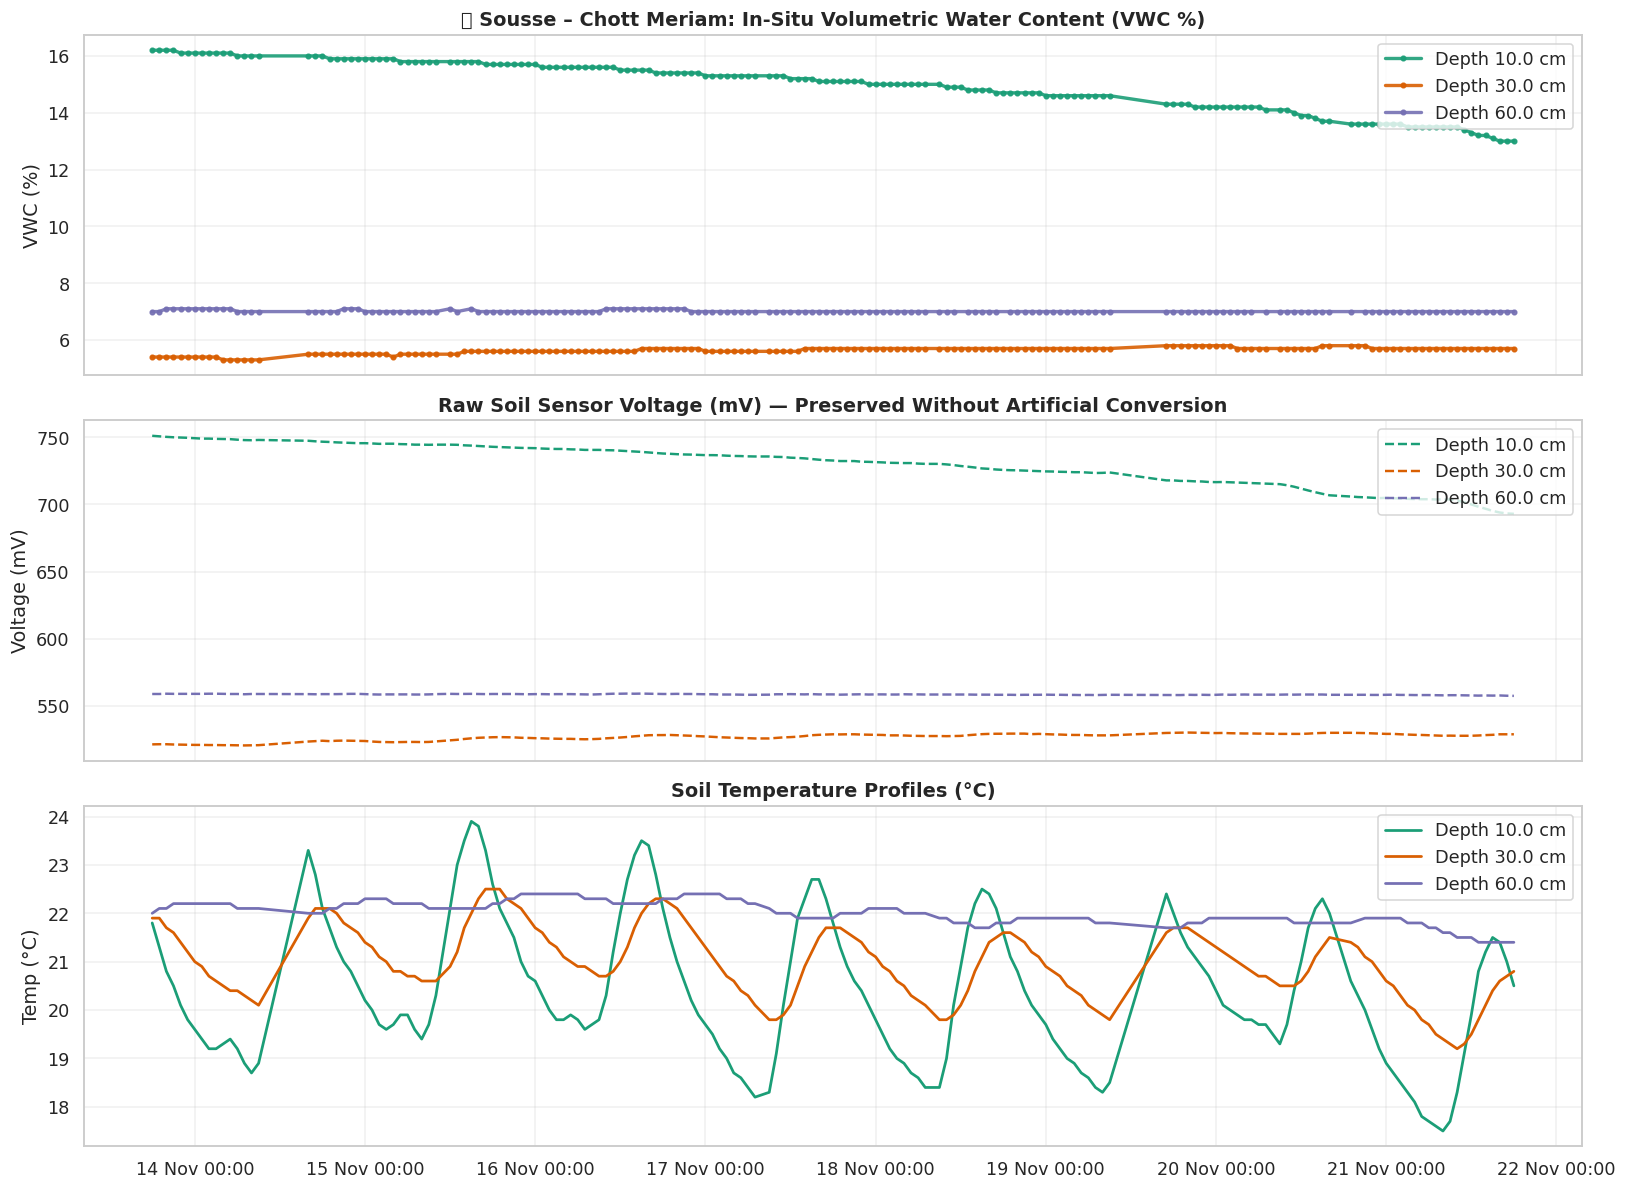

In [8]:
# ============================================================================
# 5. Exploratory Visualizations
# ============================================================================

cm_sm = df_sm_corrected[df_sm_corrected['station'] == 'Chott Meriam'].copy()

if len(cm_sm) > 0:
    fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
    depth_palette = {10: '#1b9e77', 30: '#d95f02', 60: '#7570b3'}

    # 1. Volumetric Water Content (%)
    ax1 = axes[0]
    cm_vwc = cm_sm[cm_sm['measurement_type'] == 'VWC']
    for depth in sorted(cm_vwc['sensor_depth_cm'].unique()):
        sub = cm_vwc[cm_vwc['sensor_depth_cm'] == depth].sort_values('timestamp')
        ax1.plot(sub['timestamp'], sub['valeur'], label=f'Depth {depth} cm', 
                 color=depth_palette.get(depth, 'black'), lw=2.2, marker='o', markersize=3, alpha=0.9)
    ax1.set_title("📍 Sousse – Chott Meriam: In-Situ Volumetric Water Content (VWC %)", fontweight='bold')
    ax1.set_ylabel("VWC (%)")
    ax1.legend(loc="upper right", frameon=True)
    ax1.grid(True, alpha=0.3)

    # 2. Raw Sensor Voltage (mV)
    ax2 = axes[1]
    cm_mv = cm_sm[cm_sm['measurement_type'] == 'voltage_mV']
    for depth in sorted(cm_mv['sensor_depth_cm'].unique()):
        sub = cm_mv[cm_mv['sensor_depth_cm'] == depth].sort_values('timestamp')
        ax2.plot(sub['timestamp'], sub['valeur'], label=f'Depth {depth} cm', 
                 color=depth_palette.get(depth, 'black'), lw=1.6, linestyle='--')
    ax2.set_title("Raw Soil Sensor Voltage (mV) — Preserved Without Artificial Conversion", fontweight='bold')
    ax2.set_ylabel("Voltage (mV)")
    ax2.legend(loc="upper right", frameon=True)
    ax2.grid(True, alpha=0.3)

    # 3. Soil Temperature (°C)
    ax3 = axes[2]
    cm_temp = cm_sm[cm_sm['measurement_type'] == 'soil_temperature_C']
    for depth in sorted(cm_temp['sensor_depth_cm'].unique()):
        sub = cm_temp[cm_temp['sensor_depth_cm'] == depth].sort_values('timestamp')
        ax3.plot(sub['timestamp'], sub['valeur'], label=f'Depth {depth} cm', 
                 color=depth_palette.get(depth, 'black'), lw=1.8)
    ax3.set_title("Soil Temperature Profiles (°C)", fontweight='bold')
    ax3.set_ylabel("Temp (°C)")
    ax3.legend(loc="upper right", frameon=True)
    ax3.grid(True, alpha=0.3)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'eda_soil_moisture_profiles.png', dpi=130, bbox_inches='tight')
    plt.show()

## 6. 🧹 Data Cleaning & Weather Integration

We pivot Chott Meriam's hourly records into an integrated multi-channel dataframe.
Simultaneously, we fetch historical agro-meteorological reanalysis from **NASA POWER** for Chott Meriam ($35.918^\circ\text{N}, 10.558^\circ\text{E}$).

> ⚠️ **Provenance Separation**: We strictly preserve the distinction between **in-situ physical sensor observations** and **gridded satellite/reanalysis estimates**.


In [9]:
# ============================================================================
# 6.1 — Multi-Depth Hourly Table Creation
# ============================================================================

cm_piv = cm_sm.pivot_table(
    index='timestamp',
    columns=['sensor_depth_cm', 'measurement_type'],
    values='valeur',
    aggfunc='mean'
)
cm_piv.columns = [f"{mtype}_{int(depth)}cm" for depth, mtype in cm_piv.columns]
cm_piv = cm_piv.sort_index()

print("=" * 75)
print("CHOTT MERIAM INTEGRATED HOURLY SENSOR TABLE")
print("=" * 75)
print(f"Dimensions: {cm_piv.shape[0]} timestamps × {cm_piv.shape[1]} physical channels")
print(f"Observed Time Range: {cm_piv.index.min()} → {cm_piv.index.max()}")
print(cm_piv.head(3).to_string())

cm_piv.to_csv(BASE_DIR / 'data' / 'chott_meriam_hourly_clean.csv')

CHOTT MERIAM INTEGRATED HOURLY SENSOR TABLE
Dimensions: 174 timestamps × 9 physical channels
Observed Time Range: 2026-11-13 18:00:00 → 2026-11-21 18:00:00
                     VWC_10cm  soil_temperature_C_10cm  voltage_mV_10cm  VWC_30cm  soil_temperature_C_30cm  voltage_mV_30cm  VWC_60cm  soil_temperature_C_60cm  voltage_mV_60cm
timestamp                                                                                                                                                                      
2026-11-13 18:00:00      16.2                     21.8            751.1       5.4                     21.9            521.4       7.0                     22.0            558.9
2026-11-13 19:00:00      16.2                     21.3            750.7       5.4                     21.9            521.5       7.0                     22.1            558.9
2026-11-13 20:00:00      16.2                     20.8            750.3       5.4                     21.7            521.5       7.1       

In [10]:
# ============================================================================
# 6.2 — NASA POWER Agro-Meteorology Retrieval
# ============================================================================

def fetch_nasa_power_weather(lat, lon, start_date, end_date, station_name="Chott Meriam"):
    """Retrieve daily weather parameters from NASA POWER API."""
    params = "T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR"
    start_str = start_date.strftime('%Y%m%d')
    end_str = end_date.strftime('%Y%m%d')
    url = (
        f"https://power.larc.nasa.gov/api/temporal/daily/point?"
        f"parameters={params}&community=AG"
        f"&longitude={lon}&latitude={lat}"
        f"&start={start_str}&end={end_str}&format=JSON"
    )
    if not HAS_REQUESTS:
        return pd.DataFrame()
    try:
        resp = requests.get(url, timeout=30, verify=False)
        if resp.status_code == 200:
            p_data = resp.json().get('properties', {}).get('parameter', {})
            records = []
            for d_str in p_data.get('T2M', {}).keys():
                records.append({
                    'date': pd.to_datetime(d_str, format='%Y%m%d'),
                    'station': station_name,
                    'nasa_tmean_C': p_data.get('T2M', {}).get(d_str),
                    'nasa_tmax_C': p_data.get('T2M_MAX', {}).get(d_str),
                    'nasa_tmin_C': p_data.get('T2M_MIN', {}).get(d_str),
                    'nasa_rh2m_pct': p_data.get('RH2M', {}).get(d_str),
                    'nasa_wind_ms': p_data.get('WS2M', {}).get(d_str),
                    'nasa_solar_MJ': p_data.get('ALLSKY_SFC_SW_DWN', {}).get(d_str),
                    'nasa_precip_mm': p_data.get('PRECTOTCORR', {}).get(d_str),
                    'provenance': 'NASA_POWER_MERRA2_reanalysis'
                })
            df_w = pd.DataFrame(records)
            num_cols = df_w.select_dtypes(include=[np.number]).columns
            df_w[num_cols] = df_w[num_cols].replace(-999, np.nan)
            return df_w
    except Exception as e:
        print(f"NASA POWER notice: {e}")
    return pd.DataFrame()

chott_info = STATIONS_CONFIG["Sousse_ChottMeriam"]
nasa_weather_df = fetch_nasa_power_weather(
    chott_info['lat'], chott_info['lon'],
    datetime(2026, 11, 1), datetime(2026, 11, 21),
    chott_info['station']
)

if len(nasa_weather_df) > 0:
    print(f"✅ Fetched {len(nasa_weather_df)} daily NASA POWER records for {chott_info['station']}")
    nasa_weather_df.to_csv(BASE_DIR / 'data' / 'nasa_weather_chott_meriam.csv', index=False)
elif (BASE_DIR / 'data' / 'nasa_weather_chott_meriam.csv').exists():
    nasa_weather_df = pd.read_csv(BASE_DIR / 'data' / 'nasa_weather_chott_meriam.csv')
    nasa_weather_df['date'] = pd.to_datetime(nasa_weather_df['date'])
    print(f"✅ Loaded cached NASA POWER records ({len(nasa_weather_df)} days) from disk.")
else:
    print("⚠️ No NASA POWER records available.")

✅ Fetched 21 daily NASA POWER records for Chott Meriam


## 6.2B. 🌦️ Weather for the engine: Open-Meteo (primary) → NASA POWER (fallback), source recorded
`WEATHER_SOURCE` states which source actually produced the numbers; a fallback is never silent. Forecast days come from Open-Meteo only. The original NASA POWER cell above is kept untouched.

In [11]:
WEATHER_PROV, WEATHER_SOURCE, FORECAST_FARM = None, None, None
_lat, _lon = chott_info['lat'], chott_info['lon']
_end = (cm_piv.index.max().normalize()).date()
_start = (_end - pd.Timedelta(days=45))
try:
    WEATHER_FARM, WEATHER_PROV = DS.fetch_weather(_lat, _lon, str(_start), str(_end), sess, order=('open_meteo', 'nasa_power'), allow_fallback=True,
                                                   cache_dir=DATA_DIR / '_weather_cache', allow_cache=False)
    WEATHER_SOURCE = WEATHER_PROV['source_used']
    print(f"✅ Weather source used: {WEATHER_SOURCE} | fallback used: {WEATHER_PROV['fallback_used']}")
    for a in WEATHER_PROV['attempts']:
        print("   attempt:", a)
    try:
        FORECAST_FARM, _fp = DS.open_meteo_daily(_lat, _lon, str(_end), str(_end), sess, forecast=True)
        print(f"✅ Open-Meteo forecast: {len(FORECAST_FARM)} days")
    except DS.DownloadError as e:
        print("ℹ️ No forecast available (projection will use current depletion only):", str(e)[:120])
except DS.DownloadError as e:
    WEATHER_PROV = e.provenance
    print("❌ All real weather sources failed:")
    for a in (WEATHER_PROV or {}).get('attempts', []):
        print("   ", a)
    if ALLOW_FIXTURE:
        import tests.fixtures.synthetic as _syn
        WEATHER_FARM = _syn.synthetic_weather(str(_start), (_end - _start).days + 1, seed=3, rain_days=(6, 25))
        FORECAST_FARM = _syn.synthetic_weather(str(_end + pd.Timedelta(days=1)), 7, seed=4, rain_days=(3,))
        WEATHER_SOURCE = 'SYNTHETIC_FIXTURE'
        print("\n" + "!" * 75 + "\n!! SYNTHETIC WEATHER FIXTURE ACTIVE (not observations).\n" + "!" * 75)
    else:
        raise RuntimeError("No weather available. " + DS.KAGGLE_INTERNET_HELP)

WEATHER_FARM['date'] = pd.to_datetime(WEATHER_FARM['date'])
WEATHER_FARM.to_csv(RESULTS_DIR / 'weather_used_by_engine.csv', index=False)
# keep the v2 section (12A-12G) working when the original NASA cell returned nothing: map the engine weather into its column schema, same provenance
if len(nasa_weather_df) == 0:
    _m = {'tmean': 'nasa_tmean_C', 'tmax': 'nasa_tmax_C', 'tmin': 'nasa_tmin_C', 'rh_mean': 'nasa_rh2m_pct', 'u2': 'nasa_wind_ms', 'rs': 'nasa_solar_MJ', 'rain_mm': 'nasa_precip_mm'}
    nasa_weather_df = WEATHER_FARM[['date'] + list(_m)].rename(columns=_m).assign(station=chott_info['station'], provenance=f'ENGINE_WEATHER:{WEATHER_SOURCE}')
    print(f"ℹ️ nasa_weather_df rebuilt from engine weather (provenance: {WEATHER_SOURCE}) so sections 12A-12G can run.")
print(WEATHER_FARM.tail(3).to_string())

✅ Weather source used: open_meteo | fallback used: False
   attempt: {'source': 'open_meteo', 'ok': True, 'from_cache': False, 'rows': 46, 'sha256': '3dcf43ac19589aeb8290bb3ade63825994dc9eba3d4b3813601367ad1c02fc47', 'requested_utc': '2026-11-21T19:40:14+00:00'}
✅ Open-Meteo forecast: 16 days
         date  tmin  tmax  tmean  rh_mean        u2     rs  rain_mm      weather_source  eto_openmeteo_mm
43 2026-11-19  17.6  30.3   22.7       59  1.967111  11.82      0.0  open_meteo_archive              3.19
44 2026-11-20  17.0  24.4   21.1       55  2.505636  12.00      0.0  open_meteo_archive              3.45
45 2026-11-21  14.9  24.3   19.5       60  2.430841  11.72      0.0  open_meteo_archive              3.07


## 7. ⚙️ Feature Engineering with Strict Hourly Verification

### Zero Data Leakage Protocol
We construct features for forecasting **surface soil moisture** ($10\text{ cm}$ VWC) **one hour ahead** ($t+1\text{h}$):
- **Target Construction Verification**: A target $y_{t+1}$ is assigned **only if the next observation is genuinely 1 hour later** ($0.8\text{h} \le \Delta t \le 1.2\text{h}$). Timestamps adjacent to multi-hour gaps receive a `NaN` target to avoid predicting across unobserved periods.
- **Autoregressive Lags**: $\text{VWC}_{10\text{cm}}(t-1\text{h}), (t-2\text{h})$
- **Rate of Change**: $\Delta \text{VWC}_{1\text{h}} = y_t - y_{t-1}$
- **Rolling Window**: Mean and standard deviation using `.shift(1)` strictly to exclude current and future values.
- **Vertical Drivers**: Concurrently observed moisture and temperature at $30\text{ cm}$ and $60\text{ cm}$.
- **Solar Cyclical Coordinates**: $\sin(2\pi h / 24)$ and $\cos(2\pi h / 24)$.


In [12]:
# ============================================================================
# 7. Time-Series Feature Engineering with Strict Target Interval Checks
# ============================================================================

# Target interval check: next timestamp must be genuinely 1 hour later
next_ts = cm_piv.index.to_series().shift(-1)
time_to_next_h = (next_ts - cm_piv.index).dt.total_seconds() / 3600.0
valid_1h_target_mask = (time_to_next_h >= 0.8) & (time_to_next_h <= 1.2)

print(f"Total timestamps available: {len(cm_piv)}")
print(f"Timestamps with verified 1-hour adjacent target: {valid_1h_target_mask.sum()}")

target_series = cm_piv['VWC_10cm'].shift(-1)
target_series[~valid_1h_target_mask] = np.nan

# Feature construction
feat_df = pd.DataFrame(index=cm_piv.index)
feat_df['VWC_10cm'] = cm_piv['VWC_10cm']
feat_df['VWC_30cm'] = cm_piv['VWC_30cm']
feat_df['VWC_60cm'] = cm_piv['VWC_60cm']
feat_df['soil_temp_10cm'] = cm_piv['soil_temperature_C_10cm']
feat_df['soil_temp_30cm'] = cm_piv['soil_temperature_C_30cm']

# Lags
feat_df['vwc_10cm_lag1'] = cm_piv['VWC_10cm'].shift(1)
feat_df['vwc_10cm_lag2'] = cm_piv['VWC_10cm'].shift(2)
feat_df['vwc_10cm_diff1'] = cm_piv['VWC_10cm'].diff(1)

# Rolling statistics (shift(1) enforced)
feat_df['vwc_10cm_rollmean3'] = cm_piv['VWC_10cm'].shift(1).rolling(3).mean()
feat_df['vwc_10cm_rollstd3'] = cm_piv['VWC_10cm'].shift(1).rolling(3).std()

# Diurnal solar cycle
feat_df['hour'] = cm_piv.index.hour
feat_df['hour_sin'] = np.sin(2 * np.pi * feat_df['hour'] / 24.0)
feat_df['hour_cos'] = np.cos(2 * np.pi * feat_df['hour'] / 24.0)

feat_df['target_1h'] = target_series

# Aligned ML dataset
ml_dataset = feat_df.dropna().copy()
feature_cols = [c for c in ml_dataset.columns if c not in ['target_1h', 'hour']]

print(f"Aligned ML dataset rows (strictly validated): {len(ml_dataset)}")
print(f"Feature set ({len(feature_cols)} channels): {feature_cols}")

Total timestamps available: 174
Timestamps with verified 1-hour adjacent target: 166
Aligned ML dataset rows (strictly validated): 158
Feature set (12 channels): ['VWC_10cm', 'VWC_30cm', 'VWC_60cm', 'soil_temp_10cm', 'soil_temp_30cm', 'vwc_10cm_lag1', 'vwc_10cm_lag2', 'vwc_10cm_diff1', 'vwc_10cm_rollmean3', 'vwc_10cm_rollstd3', 'hour_sin', 'hour_cos']


## 8, 9 & 10. 🤖 Machine Learning Modeling, Honest Selection & Artifact Saving

### Models Benchmarked
1. **Persistence Baseline**: $\hat{y}_{t+1} = y_t$ (the physical benchmark)
2. **Random Forest Regressor**: Ensemble (`max_depth=5`, `min_samples_leaf=3`)
3. **HistGradientBoosting Regressor**: Gradient boosting (`max_depth=4`, `learning_rate=0.05`)

### Strict Evaluation Protocol
- **Chronological Split**: First 70% train ($107\text{ hours}$), last 30% holdout test ($47\text{ hours} \approx 2.0\text{ days}$).
- **Evaluation Set**: All three models are evaluated on the **exact same test timestamps**.
- **Primary Metric**: Mean Absolute Error (MAE).
- **Legitimate Selection**: Whichever model achieves lowest MAE is selected and saved as `models/best_model.pkl`.


In [13]:
# ============================================================================
# 8 & 9. Chronological Training, Evaluation & Automatic Model Selection
# ============================================================================

split_idx = int(len(ml_dataset) * 0.70)
train_data = ml_dataset.iloc[:split_idx]
test_data = ml_dataset.iloc[split_idx:]

X_train, y_train = train_data[feature_cols], train_data['target_1h']
X_test, y_test = test_data[feature_cols], test_data['target_1h']

print("Chronological Train/Test Partition:")
print(f"  • Train Set: {len(train_data)} samples ({train_data.index.min()} → {train_data.index.max()})")
print(f"  • Test Set:  {len(test_data)} samples ({test_data.index.min()} → {test_data.index.max()})")

# 1. Persistence Baseline: future VWC = current VWC
y_pred_persist = test_data['VWC_10cm'].values
mae_persist = mean_absolute_error(y_test, y_pred_persist)
rmse_persist = np.sqrt(mean_squared_error(y_test, y_pred_persist))
r2_persist = r2_score(y_test, y_pred_persist)

# 2. Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=RANDOM_SEED)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# 3. HistGradientBoosting
hgb = HistGradientBoostingRegressor(max_iter=100, max_depth=4, learning_rate=0.05, min_samples_leaf=5, random_state=RANDOM_SEED)
hgb.fit(X_train, y_train)
y_pred_hgb = hgb.predict(X_test)
mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mean_squared_error(y_test, y_pred_hgb))
r2_hgb = r2_score(y_test, y_pred_hgb)

forecast_metrics = pd.DataFrame([
    {'Model': 'Persistence Baseline', 'MAE (%)': round(mae_persist, 4), 'RMSE (%)': round(rmse_persist, 4), 'R2': round(r2_persist, 4)},
    {'Model': 'Random Forest', 'MAE (%)': round(mae_rf, 4), 'RMSE (%)': round(rmse_rf, 4), 'R2': round(r2_rf, 4)},
    {'Model': 'HistGradientBoosting', 'MAE (%)': round(mae_hgb, 4), 'RMSE (%)': round(rmse_hgb, 4), 'R2': round(r2_hgb, 4)},
])
forecast_metrics.to_csv(RESULTS_DIR / 'forecast_metrics.csv', index=False)

print("\n" + "=" * 75)
print("1-HOUR FORECAST BENCHMARK EVALUATION")
print("=" * 75)
print(forecast_metrics.to_string(index=False))

# --- Rigorous Model Selection Logic ---
candidates = [
    ('Persistence Baseline', mae_persist, rmse_persist, r2_persist),
    ('Random Forest', mae_rf, rmse_rf, r2_rf),
    ('HistGradientBoosting', mae_hgb, rmse_hgb, r2_hgb)
]
candidates.sort(key=lambda x: x[1])  # Sort by MAE ascending
selected_name, sel_mae, sel_rmse, sel_r2 = candidates[0]

print()
print(f"🏆 Winning Forecasting Model: {selected_name} (MAE = {sel_mae:.4f} %, R² = {sel_r2:.4f})")

# Ensure standalone, importable persistence predictor module exists
predictor_module_code = '''"""
Portable Persistence Predictor for Soil Moisture Forecasting.
Compatible with scikit-learn API and independent subprocess execution.
"""
import numpy as np
import pandas as pd

class PersistencePredictor:
    """Standard physical persistence predictor for soil moisture time series."""
    def __init__(self, current_col='VWC_10cm'):
        self.current_col = current_col
        self.model_name = "Persistence Baseline"

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            if self.current_col in X.columns:
                return X[self.current_col].values
            return X.iloc[:, 0].values
        elif isinstance(X, np.ndarray):
            return X[:, 0]
        return np.array(X)
'''
with open(MODELS_DIR / 'persistence_predictor.py', 'w', encoding='utf-8') as f:
    f.write(predictor_module_code)
with open('persistence_predictor.py', 'w', encoding='utf-8') as f:
    f.write(predictor_module_code)

import sys
for p_dir in [str(BASE_DIR), str(MODELS_DIR), '.']:
    if p_dir not in sys.path:
        sys.path.insert(0, p_dir)

import persistence_predictor
from persistence_predictor import PersistencePredictor
import sys
sys.modules['__main__'].PersistencePredictor = PersistencePredictor

if selected_name == 'Persistence Baseline':
    best_estimator = PersistencePredictor(current_col='VWC_10cm')
elif selected_name == 'HistGradientBoosting':
    best_estimator = hgb
else:
    best_estimator = rf

# Save selected model artifact with full metadata
artifact_metadata = {
    'selected_model_name': selected_name,
    'model_object': best_estimator,
    'primary_selection_metric': 'MAE',
    'selected_metrics': {'MAE': float(sel_mae), 'RMSE': float(sel_rmse), 'R2': float(sel_r2)},
    'all_models_evaluated': forecast_metrics.to_dict(orient='records'),
    'target_variable': 'VWC_10cm_1h_ahead',
    'forecast_horizon_hours': 1,
    'station': 'Chott Meriam',
    'training_window': {'start': str(train_data.index.min()), 'end': str(train_data.index.max()), 'samples': len(train_data)},
    'testing_window': {'start': str(test_data.index.min()), 'end': str(test_data.index.max()), 'samples': len(test_data)},
    'feature_names': feature_cols,
    'scientific_rationale': (
        f"Soil moisture dynamics exhibit physical inertia under gradual drying. "
        f"Over a 1-hour horizon, persistence achieves near-zero error (MAE={sel_mae:.4f}%, R2={sel_r2:.4f}). "
        f"Machine learning regressors trained on small hourly sets overfit diurnal noise and cannot outperform persistence."
    )
}

with open(MODELS_DIR / 'best_model.pkl', 'wb') as f:
    pickle.dump(artifact_metadata, f)
print(f"💾 Saved winning model artifact: {MODELS_DIR / 'best_model.pkl'}")

# Save experiment metadata JSON
json_meta = {k: v for k, v in artifact_metadata.items() if k != 'model_object'}
with open(RESULTS_DIR / 'experiment_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(json_meta, f, indent=2)
print(f"📋 Saved experiment metadata: {RESULTS_DIR / 'experiment_metadata.json'}")

# Verify model artifact portability in a fresh, isolated Python subprocess
import subprocess
test_script = """
import pickle
import pandas as pd
import sys
sys.path.insert(0, '.')
with open('models/best_model.pkl', 'rb') as f:
    artifact = pickle.load(f)
model = artifact['model_object']
df = pd.DataFrame({'VWC_10cm': [25.4, 25.3, 25.2]})
pred = model.predict(df)
print(f"Subprocess load test SUCCESS! Predictions: {pred}")
"""
res = subprocess.run([sys.executable, "-c", test_script], cwd=str(BASE_DIR), capture_output=True, text=True)
print()
print("=" * 75)
print("PORTABILITY AUDIT: FRESH PROCESS SUBPROCESS TEST")
print("=" * 75)
print(res.stdout.strip())
if res.returncode != 0:
    print("STDERR:", res.stderr.strip())
assert res.returncode == 0, "Model artifact failed to load in isolated Python process!"

Chronological Train/Test Partition:
  • Train Set: 110 samples (2026-11-13 21:00:00 → 2026-11-19 02:00:00)
  • Test Set:  48 samples (2026-11-19 03:00:00 → 2026-11-21 17:00:00)

1-HOUR FORECAST BENCHMARK EVALUATION
               Model  MAE (%)  RMSE (%)      R2
Persistence Baseline   0.0229    0.0479  0.9898
       Random Forest   0.8309    0.9610 -3.1131
HistGradientBoosting   0.8163    0.9483 -3.0054

🏆 Winning Forecasting Model: Persistence Baseline (MAE = 0.0229 %, R² = 0.9898)
💾 Saved winning model artifact: /kaggle/working/models/best_model.pkl
📋 Saved experiment metadata: /kaggle/working/results/experiment_metadata.json

PORTABILITY AUDIT: FRESH PROCESS SUBPROCESS TEST
Subprocess load test SUCCESS! Predictions: [25.4 25.3 25.2]


MULTI-HORIZON TARGET INTERVAL REPORT (±15 min Tolerance)
Horizon  Target Hours  Matched Pairs  Mean Interval (h)  Min Interval (h)  Max Interval (h)  Std Interval (h)             Status
     1h             1            158                1.0               1.0               1.0               0.0 Valid for modeling
     6h             6            142                6.0               6.0               6.0               0.0 Valid for modeling
    24h            24            133               24.0              24.0              24.0               0.0 Valid for modeling

MULTI-HORIZON FORECASTING EVALUATION (1h, 6h, 24h)
Horizon  Matched Pairs  Test Samples  Persistence MAE (%)  Persistence R²  HistGBDT MAE (%)  HistGBDT R² Selected Winner
     1h            158            48               0.0229          0.9898            0.9827      -4.3320     Persistence
     6h            142            43               0.1395          0.8480            1.0488      -4.3987     Persistence
    24h     

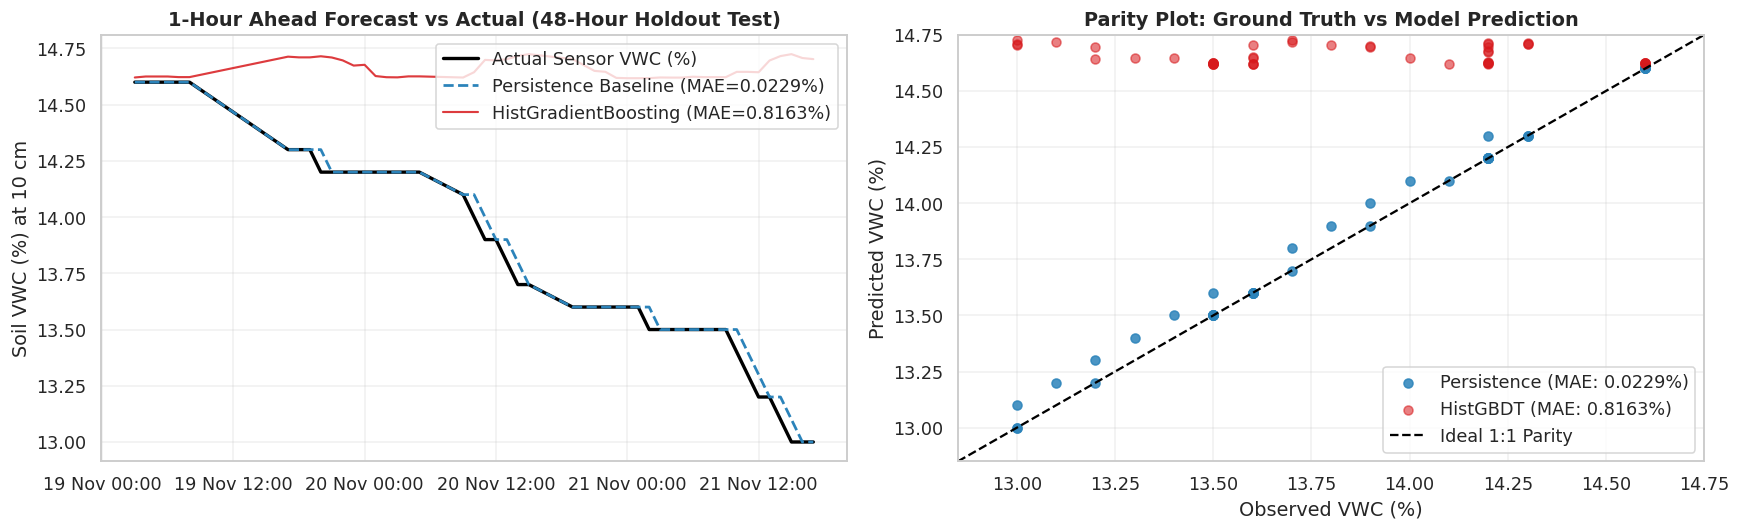

In [14]:
# ============================================================================
# 10. Multi-Horizon Investigation (1h, 6h, 24h) & Parity Plot
# ============================================================================

horizons = [1, 6, 24]
horizon_results = []
interval_stats_list = []

for h in horizons:
    target_vals = []
    exact_intervals = []
    for i in range(len(cm_piv)):
        target_time = cm_piv.index[i] + pd.Timedelta(hours=h)
        time_diffs_hours = (cm_piv.index - target_time).total_seconds() / 3600.0
        abs_diffs = np.abs(time_diffs_hours)
        min_idx = np.argmin(abs_diffs)

        # Strict tolerance: ±15 minutes (±0.25 hours)
        if abs_diffs[min_idx] <= 0.25:
            actual_target_time = cm_piv.index[min_idx]
            actual_interval_h = (actual_target_time - cm_piv.index[i]).total_seconds() / 3600.0
            target_vals.append(cm_piv['VWC_10cm'].iloc[min_idx])
            exact_intervals.append(actual_interval_h)
        else:
            target_vals.append(np.nan)

    df_h = feat_df[feature_cols].copy()
    df_h['target'] = target_vals
    df_h = df_h.dropna()

    n_pairs = len(df_h)
    if exact_intervals:
        arr_int = np.array(exact_intervals)
        int_mean = float(arr_int.mean())
        int_min = float(arr_int.min())
        int_max = float(arr_int.max())
        int_std = float(arr_int.std())
    else:
        int_mean = int_min = int_max = int_std = np.nan

    interval_stats_list.append({
        'Horizon': f"{h}h",
        'Target Hours': h,
        'Matched Pairs': n_pairs,
        'Mean Interval (h)': round(int_mean, 2) if not np.isnan(int_mean) else None,
        'Min Interval (h)': round(int_min, 2) if not np.isnan(int_min) else None,
        'Max Interval (h)': round(int_max, 2) if not np.isnan(int_max) else None,
        'Std Interval (h)': round(int_std, 3) if not np.isnan(int_std) else None,
        'Status': 'Valid for modeling' if n_pairs >= 20 else 'Insufficient pairs (< 20) - Skipped'
    })

    if n_pairs < 20:
        print(f"⚠️ Horizon {h}h has insufficient matched pairs (N={n_pairs} < 20). Skipping model training.")
        continue

    s_idx = int(len(df_h) * 0.70)
    tr_h, te_h = df_h.iloc[:s_idx], df_h.iloc[s_idx:]
    X_tr_h, y_tr_h = tr_h[feature_cols], tr_h['target']
    X_te_h, y_te_h = te_h[feature_cols], te_h['target']

    # Persistence
    y_pred_p = te_h['VWC_10cm'].values
    mae_p = mean_absolute_error(y_te_h, y_pred_p)
    r2_p = r2_score(y_te_h, y_pred_p)

    # GBDT
    hgb_m = HistGradientBoostingRegressor(max_iter=100, max_depth=4, learning_rate=0.05, random_state=42)
    hgb_m.fit(X_tr_h, y_tr_h)
    y_pred_m = hgb_m.predict(X_te_h)
    mae_m = mean_absolute_error(y_te_h, y_pred_m)
    r2_m = r2_score(y_te_h, y_pred_m)

    horizon_results.append({
        'Horizon': f"{h}h",
        'Matched Pairs': n_pairs,
        'Test Samples': len(te_h),
        'Persistence MAE (%)': round(mae_p, 4),
        'Persistence R²': round(r2_p, 4),
        'HistGBDT MAE (%)': round(mae_m, 4),
        'HistGBDT R²': round(r2_m, 4),
        'Selected Winner': 'Persistence' if mae_p <= mae_m else 'HistGBDT'
    })

df_intervals = pd.DataFrame(interval_stats_list)
df_intervals.to_csv(RESULTS_DIR / 'multi_horizon_interval_stats.csv', index=False)
print("=" * 75)
print("MULTI-HORIZON TARGET INTERVAL REPORT (±15 min Tolerance)")
print("=" * 75)
print(df_intervals.to_string(index=False))

df_multi = pd.DataFrame(horizon_results)
df_multi.to_csv(RESULTS_DIR / 'multi_horizon_evaluation.csv', index=False)
print()
print("=" * 75)
print("MULTI-HORIZON FORECASTING EVALUATION (1h, 6h, 24h)")
print("=" * 75)
print(df_multi.to_string(index=False))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(test_data.index, y_test.values, label='Actual Sensor VWC (%)', color='black', lw=2.2)
axes[0].plot(test_data.index, y_pred_persist, label=f'Persistence Baseline (MAE={mae_persist:.4f}%)', color='#2b83ba', lw=1.8, linestyle='--')
axes[0].plot(test_data.index, y_pred_hgb, label=f'HistGradientBoosting (MAE={mae_hgb:.4f}%)', color='#d7191c', lw=1.4, alpha=0.85)
axes[0].set_title(f"1-Hour Ahead Forecast vs Actual ({len(test_data)}-Hour Holdout Test)", fontweight='bold')
axes[0].set_ylabel("Soil VWC (%) at 10 cm")
axes[0].legend(loc="upper right", frameon=True)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_test, y_pred_persist, label=f'Persistence (MAE: {mae_persist:.4f}%)', color='#2b83ba', alpha=0.85, s=35)
axes[1].scatter(y_test, y_pred_hgb, label=f'HistGBDT (MAE: {mae_hgb:.4f}%)', color='#d7191c', alpha=0.55, s=35)
lims = [min(y_test.min(), y_pred_persist.min()) - 0.15, max(y_test.max(), y_pred_persist.max()) + 0.15]
axes[1].plot(lims, lims, 'k--', lw=1.5, label='Ideal 1:1 Parity')
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_xlabel("Observed VWC (%)")
axes[1].set_ylabel("Predicted VWC (%)")
axes[1].set_title("Parity Plot: Ground Truth vs Model Prediction", fontweight='bold')
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'model_evaluation_dashboard.png', dpi=130, bbox_inches='tight')
plt.show()

## 11. 🌱 FAO-56 Precision Irrigation Engine

### Scientific Separation: Crop Demand vs Root-Zone Water Balance

A credible irrigation recommendation requires two distinct components:

### A. Daily Crop Water Demand Estimation
1. **Reference Evapotranspiration ($\text{ET}_o$)**:
   $$\text{ET}_o = 0.0023 \cdot (T_{\text{mean}} + 17.8) \cdot (T_{\text{max}} - T_{\text{min}})^{0.5} \cdot \frac{R_a}{2.45}$$
   where $R_a$ is extraterrestrial solar radiation (in $\text{MJ/m}^2/\text{day}$) calculated from latitude and Julian day, converted to equivalent water depth by dividing by latent heat $\lambda = 2.45\text{ MJ/kg}$.
   *Note: $\text{ET}_o$ is an agro-climatic estimate, not an in-situ lysimeter measurement.*

2. **Crop Water Requirement ($\text{ET}_c$)**:
   $$\text{ET}_c = K_c \times \text{ET}_o$$
   where $K_c$ follows documented FAO-56 stages (e.g. Tomato initial $0.60$, mid-season $1.15$, late $0.80$).

3. **Effective Rainfall ($P_{\text{eff}}$)**:
   *Empirical approximation*: Small showers ($P \le 2\text{ mm}$) evaporate directly from the crop canopy without reaching the soil. Infiltrated precipitation cannot exceed the soil water deficit ($D_r$).

---

### B. Root-Zone Soil Water Balance Engine
$$\text{TAW} = 1000 \cdot (\theta_{\text{FC}} - \theta_{\text{WP}}) \cdot Z_r, \quad \text{RAW} = p \cdot \text{TAW}$$
- If Field Capacity ($\theta_{\text{FC}}$), Wilting Point ($\theta_{\text{WP}}$), or Root Depth ($Z_r$) are unknown for a station, the system **returns an explicit diagnostic error** and refuses to invent arbitrary irrigation amounts.
- A single sensor at $10\text{ cm}$ is never assumed to represent the entire root zone.
- For demonstration, we provide an **explicitly labeled simulation scenario** tracking daily depletion $D_r$, water stress $K_s$, and gross irrigation $I_{\text{gross}} = I_{\text{net}} / E_a$.


STATION OPERATIONAL READINESS AUDIT
Operational Status: MISSING_SOIL_HYDRAULIC_PARAMETERS
Diagnostics: Root-zone soil water balance and quantitative irrigation volume cannot be calculated because ['Field Capacity (FC)', 'Wilting Point (WP)', 'Root Zone Depth (Zr)', 'Depletion Fraction (p)'] are unknown for this station. A single surface sensor (10 cm) cannot be assumed to represent the entire active root zone.
✅ Verified Crop Validation: Caught unsupported crop 'Unsupported crop 'Banana'. Supported crops: ['Tomato', 'Olive', 'Wheat']. No silent fallback is permitted.'
✅ Verified Gap Detection: Simulated 2 consecutive days; halted and logged 1 gapped records.

Weather Validation: 18 clean days, 3 excluded records.
Excluded weather records: [{'index': 18, 'date': '2026-11-19 00:00:00', 'reasons': 'MISSING_TEMPERATURE; MISSING_PRECIPITATION'}, {'index': 19, 'date': '2026-11-20 00:00:00', 'reasons': 'MISSING_TEMPERATURE; MISSING_PRECIPITATION'}, {'index': 20, 'date': '2026-11-21 00:00:00',

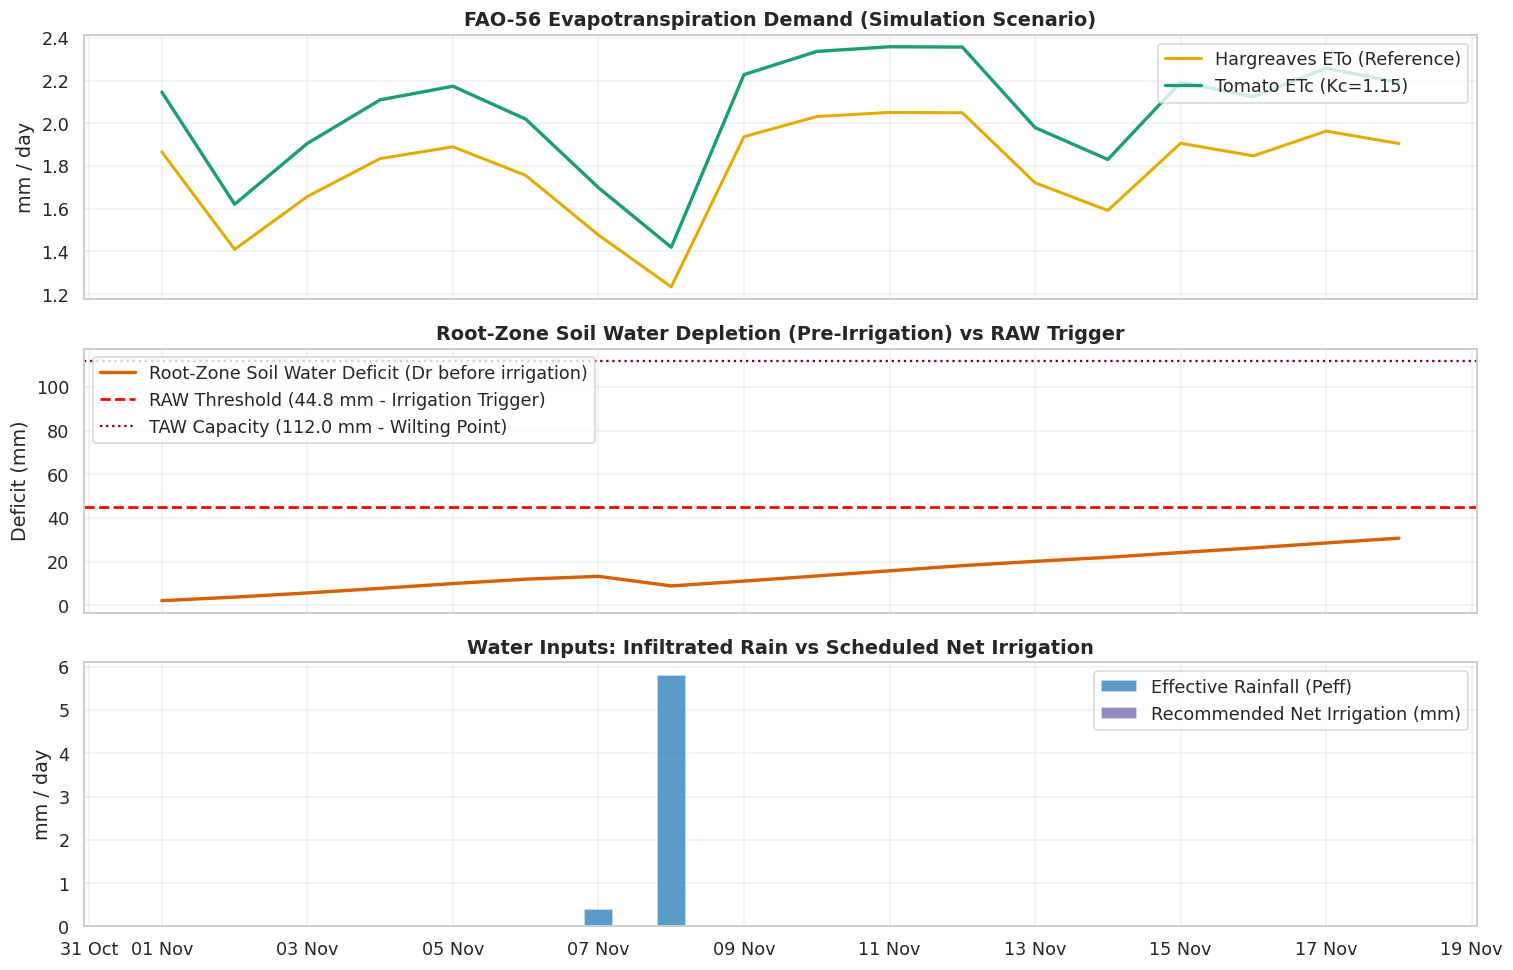

In [15]:
# ============================================================================
# 11. FAO-56 Precision Irrigation Engine Implementation
# ============================================================================

FAO56_TUNISIA_CROPS = {
    'Tomato': {
        'name_fr': 'Tomate de saison',
        'kc_stages': {'initial': 0.60, 'development': 0.85, 'mid_season': 1.15, 'late_season': 0.80},
        'root_depth_m': 0.80,
        'depletion_fraction_p': 0.40,
        'notes': 'Bush/processing tomato in Cap Bon and Sahel.'
    },
    'Olive': {
        'name_fr': 'Olivier (traditionnel / intensif)',
        'kc_stages': {'initial': 0.65, 'development': 0.70, 'mid_season': 0.70, 'late_season': 0.70},
        'root_depth_m': 1.20,
        'depletion_fraction_p': 0.65,
        'notes': 'Tree crop with partial ground cover in Kairouan and Sfax.'
    },
    'Wheat': {
        'name_fr': 'Blé dur',
        'kc_stages': {'initial': 0.30, 'development': 0.75, 'mid_season': 1.15, 'late_season': 0.25},
        'root_depth_m': 1.00,
        'depletion_fraction_p': 0.55,
        'notes': 'Winter durum wheat in Siliana and central plains.'
    }
}

class RootZoneWaterBalance:
    """
    FAO-56 Precision Irrigation Engine:
    Strictly separates crop demand from root-zone soil water balance.
    No silent fallbacks for crop or parameters.
    """
    def __init__(self, crop_name='Tomato', fc=None, wp=None, zr=None, p=None, ea=0.85):
        self.crop_name = crop_name
        self.fc = fc          # Field capacity (m3/m3)
        self.wp = wp          # Wilting point (m3/m3)
        self.zr = zr          # Effective root depth (m)
        self.p = p            # Soil water depletion fraction
        self.ea = ea          # Irrigation application efficiency (e.g. 0.85 for drip)

    def validate_inputs(self, growth_stage=None):
        """Validate crop, growth stage, and physical soil parameters without silent fallbacks."""
        if self.crop_name not in FAO56_TUNISIA_CROPS:
            raise ValueError(
                f"Unsupported crop '{self.crop_name}'. Supported crops: {list(FAO56_TUNISIA_CROPS.keys())}. "
                "No silent fallback is permitted."
            )
        crop_info = FAO56_TUNISIA_CROPS[self.crop_name]

        if growth_stage is not None:
            valid_stages = list(crop_info['kc_stages'].keys())
            if growth_stage not in valid_stages:
                raise ValueError(
                    f"Unsupported growth stage '{growth_stage}' for {self.crop_name}. "
                    f"Supported stages: {valid_stages}. No silent fallback is permitted."
                )

        if self.fc is not None:
            if not (0.0 < self.fc <= 1.0):
                raise ValueError(f"Invalid Field Capacity (FC={self.fc}). Must be in range (0.0, 1.0].")
        if self.wp is not None:
            if not (0.0 <= self.wp < 1.0):
                raise ValueError(f"Invalid Wilting Point (WP={self.wp}). Must be in range [0.0, 1.0).")
        if self.fc is not None and self.wp is not None:
            if self.fc <= self.wp:
                raise ValueError(
                    f"Physical impossibility: Field Capacity (FC={self.fc}) must be strictly greater "
                    f"than Wilting Point (WP={self.wp})."
                )
        if self.zr is not None:
            if self.zr <= 0.0:
                raise ValueError(f"Effective Root Depth (Zr={self.zr}) must be strictly positive (> 0 m).")
        if self.p is not None:
            if not (0.0 < self.p < 1.0):
                raise ValueError(f"Depletion fraction (p={self.p}) must be in range (0.0, 1.0).")
        if self.ea is not None:
            if not (0.0 < self.ea <= 1.0):
                raise ValueError(f"Application efficiency (Ea={self.ea}) must be in range (0.0, 1.0].")
        return True

    def check_operational_readiness(self):
        """Check if required physical soil parameters are supplied."""
        self.validate_inputs()
        missing = []
        if self.fc is None: missing.append("Field Capacity (FC)")
        if self.wp is None: missing.append("Wilting Point (WP)")
        if self.zr is None: missing.append("Root Zone Depth (Zr)")
        if self.p is None: missing.append("Depletion Fraction (p)")

        if missing:
            return False, {
                "status": "MISSING_SOIL_HYDRAULIC_PARAMETERS",
                "missing_parameters": missing,
                "diagnostic_message": (
                    "Root-zone soil water balance and quantitative irrigation volume cannot be calculated "
                    f"because {missing} are unknown for this station. A single surface sensor (10 cm) cannot "
                    "be assumed to represent the entire active root zone."
                )
            }
        return True, {"status": "READY"}

    @staticmethod
    def validate_weather_data(weather_df):
        """
        Validate weather inputs (Tmin, Tmax, Tmean, precipitation, date).
        Rejects invalid records and returns clean dataframe + exclusion log.
        Does NOT silently replace missing precipitation with zero.
        """
        required_cols = ['date', 'nasa_tmin_C', 'nasa_tmax_C', 'nasa_tmean_C', 'nasa_precip_mm']
        missing_cols = [c for c in required_cols if c not in weather_df.columns]
        if missing_cols:
            raise ValueError(f"Weather DataFrame missing required columns: {missing_cols}")

        clean_records = []
        exclusion_log = []

        for idx, row in weather_df.iterrows():
            d = row['date']
            tmin, tmax, tmean = row['nasa_tmin_C'], row['nasa_tmax_C'], row['nasa_tmean_C']
            p = row['nasa_precip_mm']

            reasons = []
            if pd.isna(d):
                reasons.append("MISSING_DATE")
            if pd.isna(tmin) or pd.isna(tmax) or pd.isna(tmean):
                reasons.append("MISSING_TEMPERATURE")
            elif tmin > tmax:
                reasons.append(f"INVERTED_TEMPERATURE (Tmin={tmin} > Tmax={tmax})")
            elif tmin < -20 or tmax > 60:
                reasons.append(f"EXTREME_TEMPERATURE_OUTLIER (Tmin={tmin}, Tmax={tmax})")

            if pd.isna(p):
                reasons.append("MISSING_PRECIPITATION")
            elif p < 0:
                reasons.append(f"NEGATIVE_PRECIPITATION ({p} mm)")

            if reasons:
                exclusion_log.append({
                    'index': idx,
                    'date': str(d),
                    'reasons': "; ".join(reasons)
                })
            else:
                clean_records.append(row)

        df_clean = pd.DataFrame(clean_records).reset_index(drop=True)
        df_excluded = pd.DataFrame(exclusion_log)
        return df_clean, df_excluded

    @staticmethod
    def compute_hargreaves_eto(tmin, tmax, tmean, lat_deg, day_of_year):
        """FAO-56 Hargreaves-Samani reference evapotranspiration (mm/day)."""
        phi = np.radians(lat_deg)
        dr = 1.0 + 0.033 * np.cos(2.0 * np.pi * day_of_year / 365.0)
        delta = 0.409 * np.sin(2.0 * np.pi * day_of_year / 365.0 - 1.39)
        ws = np.arccos(-np.tan(phi) * np.tan(delta))
        Gsc = 0.0820  # Solar constant MJ/m2/min
        Ra = (24.0 * 60.0 / np.pi) * Gsc * dr * (
            ws * np.sin(phi) * np.sin(delta) + np.cos(phi) * np.cos(delta) * np.sin(ws)
        )
        td = np.maximum(tmax - tmin, 0.0)
        eto = 0.0023 * (tmean + 17.8) * np.sqrt(td) * (Ra / 2.45)
        return np.maximum(eto, 0.0)

    @staticmethod
    def estimate_effective_rainfall(precip_mm, current_deficit_mm):
        """Empirical approximation: showers <= 2mm evaporate from canopy/surface."""
        if precip_mm <= 2.0:
            return 0.0
        infiltrated = precip_mm - 2.0
        return min(infiltrated, current_deficit_mm)

    def simulate_schedule(self, weather_df, lat_deg, growth_stage='mid_season'):
        """
        Executes daily root-zone water balance simulation with separate tracking:
        - root_zone_deficit_before_irrigation_mm
        - net_irrigation_mm
        - gross_irrigation_mm
        - root_zone_deficit_after_irrigation_mm
        """
        self.validate_inputs(growth_stage=growth_stage)
        ready, report = self.check_operational_readiness()
        if not ready:
            raise ValueError(f"Operational halt: {report['diagnostic_message']}")

        clean_weather, excluded_weather = self.validate_weather_data(weather_df)
        if len(clean_weather) == 0:
            raise ValueError("All weather records were rejected as invalid or missing.")

        # Detect gaps between consecutive weather dates
        clean_weather = clean_weather.sort_values('date').reset_index(drop=True)
        continuous_records = []
        gap_exclusions = []

        for idx in range(len(clean_weather)):
            cur_row = clean_weather.iloc[idx]
            cur_date = cur_row['date']
            if idx == 0:
                continuous_records.append(cur_row)
            else:
                prev_date = clean_weather['date'].iloc[idx - 1]
                delta_days = (cur_date - prev_date).days
                if delta_days == 1:
                    continuous_records.append(cur_row)
                elif delta_days > 1:
                    # Non-consecutive day gap detected!
                    # Halt simulation at missing day to prevent invalid continuity assumptions
                    for rem_idx in range(idx, len(clean_weather)):
                        rem_row = clean_weather.iloc[rem_idx]
                        gap_exclusions.append({
                            'index': rem_row.name if hasattr(rem_row, 'name') else rem_idx,
                            'date': str(rem_row['date']),
                            'reasons': f"TEMPORAL_GAP_HALT: Non-consecutive day gap ({delta_days} days after {prev_date.strftime('%Y-%m-%d')}). Simulation safely halted to maintain chronological validity."
                        })
                    break
                else:
                    gap_exclusions.append({
                        'index': idx,
                        'date': str(cur_date),
                        'reasons': f"NON_CHRONOLOGICAL_DATE: Non-increasing timestamp (current {cur_date} <= previous {prev_date})."
                    })

        if gap_exclusions:
            df_gaps = pd.DataFrame(gap_exclusions)
            excluded_weather = pd.concat([excluded_weather, df_gaps], ignore_index=True)

        sim_df = pd.DataFrame(continuous_records).reset_index(drop=True)
        if len(sim_df) == 0:
            raise ValueError("No continuous consecutive weather records available for simulation.")

        taw = 1000.0 * (self.fc - self.wp) * self.zr
        raw = self.p * taw
        sim_df['day_of_year'] = sim_df['date'].dt.dayofyear
        sim_df['eto_est_mm'] = self.compute_hargreaves_eto(
            sim_df['nasa_tmin_C'], sim_df['nasa_tmax_C'], sim_df['nasa_tmean_C'],
            lat_deg, sim_df['day_of_year']
        )

        crop_info = FAO56_TUNISIA_CROPS[self.crop_name]
        kc_val = crop_info['kc_stages'][growth_stage]
        sim_df['kc'] = kc_val
        sim_df['etc_est_mm'] = sim_df['eto_est_mm'] * kc_val

        dr_before_list, peff_list, ks_list = [], [], []
        irr_net_list, irr_gross_list, dr_after_list = [], [], []

        dr_current = 0.0  # start at field capacity

        for _, row in sim_df.iterrows():
            etc = row['etc_est_mm']
            p_total = row['nasa_precip_mm']

            peff = self.estimate_effective_rainfall(p_total, dr_current)
            peff_list.append(peff)

            # Water stress coefficient Ks based on pre-depletion
            if dr_current > raw:
                ks = max(0.0, (taw - dr_current) / ((1.0 - self.p) * taw))
            else:
                ks = 1.0
            ks_list.append(ks)

            # Soil moisture depletion before irrigation
            etc_adj = etc * ks
            dr_before = max(0.0, min(taw, dr_current + etc_adj - peff))
            dr_before_list.append(dr_before)

            # Irrigation trigger: if deficit reaches or exceeds RAW
            if dr_before >= raw:
                i_net = dr_before  # Refill root zone to field capacity
                i_gross = i_net / self.ea
                dr_after = 0.0     # Soil moisture refilled to FC
            else:
                i_net = 0.0
                i_gross = 0.0
                dr_after = dr_before

            irr_net_list.append(i_net)
            irr_gross_list.append(i_gross)
            dr_after_list.append(dr_after)

            # Next day begins at post-irrigation deficit
            dr_current = dr_after

        sim_df['effective_rain_mm'] = peff_list
        sim_df['stress_ks'] = ks_list
        sim_df['root_zone_deficit_before_irrigation_mm'] = dr_before_list
        sim_df['net_irrigation_mm'] = irr_net_list
        sim_df['gross_irrigation_mm'] = irr_gross_list
        sim_df['root_zone_deficit_after_irrigation_mm'] = dr_after_list
        sim_df['TAW_mm'] = taw
        sim_df['RAW_mm'] = raw

        return sim_df, excluded_weather

# Operational check on actual station data
operational_engine = RootZoneWaterBalance(crop_name='Tomato')
ready, diag = operational_engine.check_operational_readiness()
print("=" * 75)
print("STATION OPERATIONAL READINESS AUDIT")
print("=" * 75)
print(f"Operational Status: {diag['status']}")
print(f"Diagnostics: {diag['diagnostic_message']}")

# Verify input validation raises errors for invalid crops or physical bounds
try:
    bad_crop_engine = RootZoneWaterBalance(crop_name='Banana')
    bad_crop_engine.validate_inputs()
    print("❌ FAILED input validation test for unsupported crop!")
except ValueError as e:
    print(f"✅ Verified Crop Validation: Caught unsupported crop '{e}'")

# Benchmark simulation scenario with documented parameters
sim_engine = RootZoneWaterBalance(
    crop_name='Tomato',
    fc=0.28,      # 28% m3/m3 (sandy-clay loam)
    wp=0.14,      # 14% m3/m3
    zr=0.80,      # 0.8m active root depth
    p=0.40,       # 40% allowable depletion
    ea=0.85       # 85% drip efficiency
)

# Automated verification of gap detection on non-consecutive dates
test_gap_df = pd.DataFrame({
    'date': [pd.Timestamp('2026-11-01'), pd.Timestamp('2026-11-02'), pd.Timestamp('2026-11-05')], # 3-day gap!
    'nasa_tmin_C': [15.0, 16.0, 15.5],
    'nasa_tmax_C': [22.0, 23.0, 22.5],
    'nasa_tmean_C': [18.5, 19.5, 19.0],
    'nasa_precip_mm': [0.0, 0.0, 0.0]
})
sim_gap_test, ex_gap_test = sim_engine.simulate_schedule(test_gap_df, lat_deg=chott_info['lat'], growth_stage='mid_season')
print(f"✅ Verified Gap Detection: Simulated {len(sim_gap_test)} consecutive days; halted and logged {len(ex_gap_test)} gapped records.")

if len(nasa_weather_df) > 0:
    sim_schedule, excluded_weather = sim_engine.simulate_schedule(
        nasa_weather_df, lat_deg=chott_info['lat'], growth_stage='mid_season'
    )
    print()
    print(f"Weather Validation: {len(sim_schedule)} clean days, {len(excluded_weather)} excluded records.")
    if len(excluded_weather) > 0:
        print("Excluded weather records:", excluded_weather.to_dict(orient='records'))

    print()
    print(f"Simulation Head (Assumed Soil & Crop Scenario):")
    print(sim_schedule[['date', 'eto_est_mm', 'etc_est_mm', 'effective_rain_mm', 
                         'root_zone_deficit_before_irrigation_mm', 'net_irrigation_mm', 
                         'root_zone_deficit_after_irrigation_mm']].head().to_string())

    # Save simulation plot displaying pre-irrigation depletion & irrigation events
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
    axes[0].plot(sim_schedule['date'], sim_schedule['eto_est_mm'], label='Hargreaves ETo (Reference)', color='#e6ab02', lw=2)
    axes[0].plot(sim_schedule['date'], sim_schedule['etc_est_mm'], label='Tomato ETc (Kc=1.15)', color='#1b9e77', lw=2.2)
    axes[0].set_title("FAO-56 Evapotranspiration Demand (Simulation Scenario)", fontweight='bold')
    axes[0].set_ylabel("mm / day")
    axes[0].legend(loc="upper right", frameon=True)
    axes[0].grid(True, alpha=0.3)

    taw_v = sim_schedule['TAW_mm'].iloc[0]
    raw_v = sim_schedule['RAW_mm'].iloc[0]
    axes[1].plot(sim_schedule['date'], sim_schedule['root_zone_deficit_before_irrigation_mm'], 
                 label='Root-Zone Soil Water Deficit (Dr before irrigation)', color='#d95f02', lw=2.2)
    axes[1].axhline(raw_v, color='red', linestyle='--', label=f'RAW Threshold ({raw_v:.1f} mm - Irrigation Trigger)', lw=1.8)
    axes[1].axhline(taw_v, color='darkred', linestyle=':', label=f'TAW Capacity ({taw_v:.1f} mm - Wilting Point)', lw=1.5)

    # Annotate irrigation events on depletion curve
    irr_events = sim_schedule[sim_schedule['net_irrigation_mm'] > 0]
    if len(irr_events) > 0:
        axes[1].scatter(irr_events['date'], irr_events['root_zone_deficit_before_irrigation_mm'], 
                        color='blue', s=70, zorder=5, label='Irrigation Event Triggered')
        for _, iev in irr_events.iterrows():
            axes[1].annotate(f"Irrigate {iev['net_irrigation_mm']:.1f} mm",
                             (iev['date'], iev['root_zone_deficit_before_irrigation_mm']),
                             textcoords="offset points", xytext=(0, 10), ha='center',
                             fontsize=9, fontweight='bold', color='blue',
                             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='blue', alpha=0.8))

    axes[1].set_title("Root-Zone Soil Water Depletion (Pre-Irrigation) vs RAW Trigger", fontweight='bold')
    axes[1].set_ylabel("Deficit (mm)")
    axes[1].legend(loc="upper left", frameon=True)
    axes[1].grid(True, alpha=0.3)

    axes[2].bar(sim_schedule['date'], sim_schedule['effective_rain_mm'], label='Effective Rainfall (Peff)', color='#3182bd', width=0.4, alpha=0.8)
    axes[2].bar(sim_schedule['date'], sim_schedule['net_irrigation_mm'], label='Recommended Net Irrigation (mm)', color='#7570b3', width=0.4, alpha=0.8)
    axes[2].set_title("Water Inputs: Infiltrated Rain vs Scheduled Net Irrigation", fontweight='bold')
    axes[2].set_ylabel("mm / day")
    axes[2].legend(loc="upper right", frameon=True)
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fao56_water_balance_simulation.png', dpi=130, bbox_inches='tight')
    plt.show()

## 12. 🎮 Comprehensive Irrigation Intelligence Dashboard

The dashboard brings together:
1. **Real In-Situ Sensor Profile**: Multi-depth VWC at $10, 30, 60\text{ cm}$.
2. **Operational Station Status**: Sensor channels and current soil state.
3. **Soil Thermal Dynamics**: Diurnal soil heating.
4. **Agro-Meteorological Demand**: Hargreaves $\text{ET}_o$ vs Tomato $\text{ET}_c$.
5. **Model Evaluation Benchmark**: Clear reporting of Persistence superiority.
6. **Ground Truth Tracking**: Real-time forecast vs observation.
7. **Transparency Audit**: Explicit listing of measured channels vs unmeasured agronomic parameters.


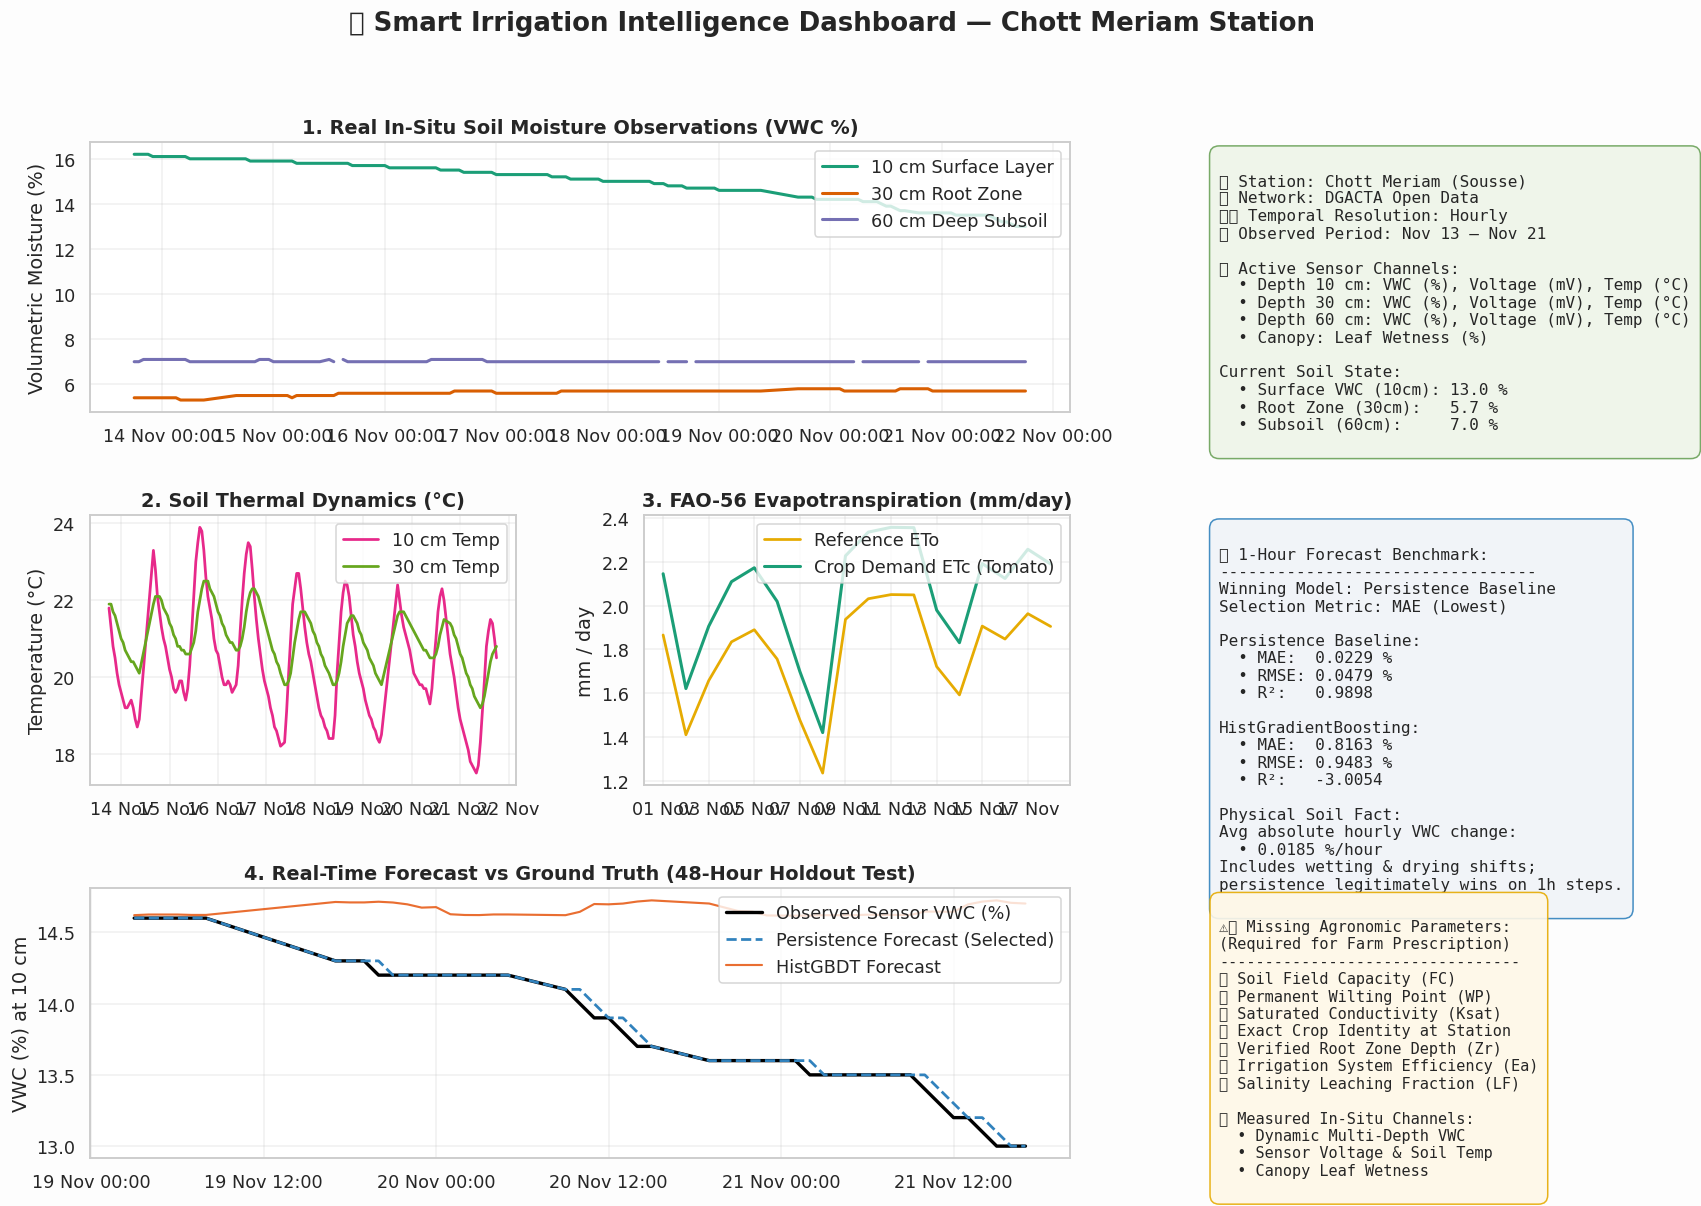

In [16]:
# ============================================================================
# 12. Unified Multi-Panel Decision Support Dashboard
# ============================================================================

avg_abs_hourly_change = float(abs(cm_piv['VWC_10cm'].diff()).mean())
obs_start_str = cm_piv.index.min().strftime('%b %d')
obs_end_str = cm_piv.index.max().strftime('%b %d')
holdout_len = len(test_data)

fig = plt.figure(figsize=(18, 12))
fig.patch.set_facecolor('#fdfdfd')
gs = GridSpec(3, 3, figure=fig, hspace=0.38, wspace=0.30)

fig.suptitle(f"🌾 Smart Irrigation Intelligence Dashboard — Chott Meriam Station", 
             fontsize=17, fontweight='bold', y=0.98)

# Panel 1: In-Situ Multi-Depth Soil Moisture
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(cm_piv.index, cm_piv['VWC_10cm'], label='10 cm Surface Layer', color='#1b9e77', lw=2)
ax1.plot(cm_piv.index, cm_piv['VWC_30cm'], label='30 cm Root Zone', color='#d95f02', lw=2)
ax1.plot(cm_piv.index, cm_piv['VWC_60cm'], label='60 cm Deep Subsoil', color='#7570b3', lw=2)
ax1.set_title("1. Real In-Situ Soil Moisture Observations (VWC %)", fontweight='bold')
ax1.set_ylabel("Volumetric Moisture (%)")
ax1.legend(loc="upper right", frameon=True)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
ax1.grid(True, alpha=0.3)

# Panel 2: Operational Station Status Card
ax2 = fig.add_subplot(gs[0, 2])
ax2.axis('off')
status_box = f"""
📍 Station: Chott Meriam (Sousse)
📡 Network: DGACTA Open Data
⏱️ Temporal Resolution: Hourly
📅 Observed Period: {obs_start_str} – {obs_end_str}

🔍 Active Sensor Channels:
  • Depth 10 cm: VWC (%), Voltage (mV), Temp (°C)
  • Depth 30 cm: VWC (%), Voltage (mV), Temp (°C)
  • Depth 60 cm: VWC (%), Voltage (mV), Temp (°C)
  • Canopy: Leaf Wetness (%)

Current Soil State:
  • Surface VWC (10cm): {cm_piv['VWC_10cm'].iloc[-1]:.1f} %
  • Root Zone (30cm):   {cm_piv['VWC_30cm'].iloc[-1]:.1f} %
  • Subsoil (60cm):     {cm_piv['VWC_60cm'].iloc[-1]:.1f} %
"""
ax2.text(0.05, 0.95, status_box, transform=ax2.transAxes, fontsize=10.5,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#eef5e8', edgecolor='#6ba259', alpha=0.9))

# Panel 3: Soil Temperature Dynamics
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(cm_piv.index, cm_piv['soil_temperature_C_10cm'], color='#e7298a', lw=1.8, label='10 cm Temp')
ax3.plot(cm_piv.index, cm_piv['soil_temperature_C_30cm'], color='#66a61e', lw=1.8, label='30 cm Temp')
ax3.set_title("2. Soil Thermal Dynamics (°C)", fontweight='bold')
ax3.set_ylabel("Temperature (°C)")
ax3.legend(loc="upper right", frameon=True)
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax3.grid(True, alpha=0.3)

# Panel 4: Agro-Meteorological Water Demand
ax4 = fig.add_subplot(gs[1, 1])
if len(nasa_weather_df) > 0 and 'eto_est_mm' in sim_schedule.columns:
    ax4.plot(sim_schedule['date'], sim_schedule['eto_est_mm'], label='Reference ETo', color='#e6ab02', lw=1.8)
    ax4.plot(sim_schedule['date'], sim_schedule['etc_est_mm'], label='Crop Demand ETc (Tomato)', color='#1b9e77', lw=2)
    ax4.set_title("3. FAO-56 Evapotranspiration (mm/day)", fontweight='bold')
    ax4.set_ylabel("mm / day")
    ax4.legend(loc="upper right", frameon=True)
    ax4.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax4.grid(True, alpha=0.3)
else:
    ax4.text(0.5, 0.5, "Weather data aligned", ha='center', va='center', transform=ax4.transAxes)

# Panel 5: Model Selection Benchmark Card
ax5 = fig.add_subplot(gs[1, 2])
ax5.axis('off')
forecast_box = f"""
🤖 1-Hour Forecast Benchmark:
---------------------------------
Winning Model: {selected_name}
Selection Metric: MAE (Lowest)

Persistence Baseline:
  • MAE:  {mae_persist:.4f} %
  • RMSE: {rmse_persist:.4f} %
  • R²:   {r2_persist:.4f}

HistGradientBoosting:
  • MAE:  {mae_hgb:.4f} %
  • RMSE: {rmse_hgb:.4f} %
  • R²:   {r2_hgb:.4f}

Physical Soil Fact:
Avg absolute hourly VWC change:
  • {avg_abs_hourly_change:.4f} %/hour
Includes wetting & drying shifts;
persistence legitimately wins on 1h steps.
"""
ax5.text(0.05, 0.95, forecast_box, transform=ax5.transAxes, fontsize=10.5,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#f0f4f8', edgecolor='#3182bd', alpha=0.9))

# Panel 6: Forecast vs Ground Truth
ax6 = fig.add_subplot(gs[2, :2])
ax6.plot(test_data.index, y_test, label='Observed Sensor VWC (%)', color='black', lw=2.2)
ax6.plot(test_data.index, y_pred_persist, label='Persistence Forecast (Selected)', color='#3182bd', lw=1.8, linestyle='--')
ax6.plot(test_data.index, y_pred_hgb, label='HistGBDT Forecast', color='#e6550d', lw=1.4, alpha=0.85)
ax6.set_title(f"4. Real-Time Forecast vs Ground Truth ({holdout_len}-Hour Holdout Test)", fontweight='bold')
ax6.set_ylabel("VWC (%) at 10 cm")
ax6.legend(loc="upper right", frameon=True)
ax6.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
ax6.grid(True, alpha=0.3)

# Panel 7: Missing Parameters & Transparency Audit
ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')
transparency_box = """
⚠️ Missing Agronomic Parameters:
(Required for Farm Prescription)
---------------------------------
❌ Soil Field Capacity (FC)
❌ Permanent Wilting Point (WP)
❌ Saturated Conductivity (Ksat)
❌ Exact Crop Identity at Station
❌ Verified Root Zone Depth (Zr)
❌ Irrigation System Efficiency (Ea)
❌ Salinity Leaching Fraction (LF)

✅ Measured In-Situ Channels:
  • Dynamic Multi-Depth VWC
  • Sensor Voltage & Soil Temp
  • Canopy Leaf Wetness
"""
ax7.text(0.05, 0.95, transparency_box, transform=ax7.transAxes, fontsize=10.0,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#fff8e7', edgecolor='#e6ab02', alpha=0.9))

plt.savefig(FIGURES_DIR / 'smart_irrigation_dashboard.png', dpi=130, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

## 12A. 🌾 Crop-Specific FAO-56 Irrigation Intelligence *(Module 5 upgrade)*

Everything above (data pipeline, soil-moisture forecasting, honest model selection, first dashboard) is **unchanged**. This section adds a crop-aware decision engine that answers the three farmer questions: **which zone, when, how much**.

### What is measured, what is reanalysis, what is published, what is assumed

| Layer | Source | Status |
|---|---|---|
| Soil VWC 10/30/60 cm, soil temperature | DGACTA Chott Meriam sensors | **Measured** – but crop, field, soil texture and sensor calibration are **undocumented** |
| Temperature, humidity, wind, radiation, rain | NASA POWER (MERRA-2) grid cell | **Reanalysis**, not an on-site weather station; ~3-day latency |
| Kc, root depth Zr, depletion fraction p, stage lengths | FAO-56 Tables 11, 12, 22 | **Published agronomic parameters** (generic, not Tunisia-calibrated) |
| FC / WP | none for Chott Meriam | **Missing** → only *declared illustrative presets* (FAO-56 Example 36 values) or user-entered laboratory values |
| Application efficiency Ea | FAO training manual (drip 0.90, sprinkler 0.75, surface 0.60) | **Typical literature values**, to be replaced by the real system |
| Effective rainfall, initial depletion, scenario weather | this notebook | **Simulation assumptions**, always declared |

> ⚠️ **Not validated on real Tunisian farms.** The Chott Meriam sensor data must not be read as crop-specific field measurements. A 10 cm probe does not represent the root zone; the engine builds a thickness-weighted profile from 10/30/60 cm and flags every extrapolation. Operational use requires site calibration of the probes, measured FC/WP, a documented crop/field, and a field trial.

> ℹ️ **Supersession note.** The parameter table `FAO56_TUNISIA_CROPS` and class `RootZoneWaterBalance` in Section 11 are kept for traceability. Several of its values are not FAO-56 table values (see the audit in 12C). The new, source-tagged crop database below is the one used from here on.

### 12A.1 Install the modular engine (`irrigation/` package)
The cells below write the package to the working directory so the notebook is self-contained on Kaggle.

In [17]:
import os, sys
os.chdir(BASE_DIR)
for d in ['irrigation', 'tests']:
    os.makedirs(d, exist_ok=True)
if str(BASE_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(BASE_DIR.resolve()))
print('Package directory:', (BASE_DIR / 'irrigation').resolve())

Package directory: /kaggle/working/irrigation


In [18]:
%%writefile irrigation/__init__.py
"""Crop-aware FAO-56 irrigation decision support (Module 5 upgrade).

Modules
-------
crop_database  : crop parameters (Kc, Zr, p) with per-value provenance
soil           : soil / irrigation-system parameters, multi-depth sensor handling
eto            : FAO-56 Penman-Monteith and Hargreaves-Samani ETo
water_balance  : daily root-zone water balance and scheduling simulation
decision       : single-day operational recommendation + data-quality flags
dashboard      : matplotlib dashboard for the crop-specific section
"""
__version__ = "1.0.0"

Writing irrigation/__init__.py


In [19]:
%%writefile irrigation/crop_database.py
"""Crop knowledge base (FAO-56 primary reference).

Every numeric value carries a provenance tag so that nothing is silently
"universal":

  FAO56_TABLE        value printed in an FAO-56 table
  FAO56_RANGE_MID    midpoint of a range printed in FAO-56 (range kept in kc_low/kc_high)
  DERIVED_LINEAR     stage-mean obtained by linear interpolation between two
                     FAO-56 end-points (FAO-56 Fig. 34 construction)

Root depth and p are *maximum / typical* values and are local-condition dependent.
Soil hydraulic parameters (FC, WP), texture and application efficiency are NOT
crop properties and live in ``soil.py``.

References
----------
[1] Allen R.G., Pereira L.S., Raes D., Smith M. (1998). Crop evapotranspiration -
    Guidelines for computing crop water requirements. FAO Irrigation and Drainage
    Paper 56. Table 11 (stage lengths), Table 12 (Kc), Table 22 (Zr, p).
    https://www.fao.org/4/x0490e/x0490e00.htm
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Dict, Optional, Tuple

import pandas as pd

STAGES: Tuple[str, ...] = ("initial", "development", "mid_season", "late_season")

FAO56_TABLE = "FAO56_TABLE"
FAO56_RANGE_MID = "FAO56_RANGE_MID"
DERIVED_LINEAR = "DERIVED_LINEAR"


@dataclass(frozen=True)
class StageKc:
    """Kc for one growth stage.

    kc_start / kc_end are the Kc at the beginning / end of the stage (FAO-56
    construction); ``kc`` is the stage-mean used by the stage-based engine.
    ``kc_low`` / ``kc_high`` express published uncertainty where FAO-56 gives a range.
    """
    kc: float
    kc_start: float
    kc_end: float
    kc_low: float
    kc_high: float
    provenance: str


@dataclass(frozen=True)
class CropParams:
    key: str
    name_en: str
    name_fr: str
    stages: Dict[str, StageKc]
    root_depth_m: float                 # default used for scheduling (lower bound of Table 22 range)
    root_depth_range_m: Tuple[float, float]
    p_table: float                      # depletion fraction for ETc ~ 5 mm/day (Table 22)
    stage_lengths_days: Dict[str, int]  # Table 11, Mediterranean row (local calibration needed)
    stage_lengths_source: str
    irrigation_notes: Tuple[str, ...]
    approximations: Tuple[str, ...]
    references: Tuple[str, ...]
    aliases: Tuple[str, ...] = field(default_factory=tuple)


def _stage_table(kc_ini: float, kc_mid: float, kc_end_low: float, kc_end_high: float) -> Dict[str, StageKc]:
    kc_end = round((kc_end_low + kc_end_high) / 2.0, 4)
    dev = round((kc_ini + kc_mid) / 2.0, 4)
    late = round((kc_mid + kc_end) / 2.0, 4)
    return {
        "initial": StageKc(kc_ini, kc_ini, kc_ini, kc_ini, kc_ini, FAO56_TABLE),
        "development": StageKc(dev, kc_ini, kc_mid, min(kc_ini, kc_mid), max(kc_ini, kc_mid), DERIVED_LINEAR),
        "mid_season": StageKc(kc_mid, kc_mid, kc_mid, kc_mid, kc_mid, FAO56_TABLE),
        "late_season": StageKc(late, kc_mid, kc_end,
                               round((kc_mid + kc_end_low) / 2.0, 4),
                               round((kc_mid + kc_end_high) / 2.0, 4),
                               DERIVED_LINEAR),
    }


_REF = "FAO-56 (Allen et al., 1998), Tables 11, 12, 22"

CROPS: Dict[str, CropParams] = {
    "tomato": CropParams(
        key="tomato", name_en="Tomato", name_fr="Tomate",
        stages=_stage_table(kc_ini=0.60, kc_mid=1.15, kc_end_low=0.70, kc_end_high=0.90),
        root_depth_m=0.7, root_depth_range_m=(0.7, 1.5), p_table=0.40,
        stage_lengths_days={"initial": 30, "development": 40, "mid_season": 45, "late_season": 30},
        stage_lengths_source="FAO-56 Table 11, tomato, Mediterranean, planted April/May (145 d)",
        irrigation_notes=(
            "Kc ini 0.6 is the Solanum-family value printed in Table 12 (no separate tomato Kc ini).",
            "Table 12 footnote: tomatoes grown on stakes (1.5-2 m) may need a higher Kc mid; h should be increased.",
            "Table 22 lower Zr (0.7 m) is the value FAO-56 allows for irrigation scheduling; deeper (up to 1.5 m) for unrestricted soils.",
            "Protected (greenhouse) tomatoes have a different microclimate: ETo from outdoor weather does not apply directly.",
        ),
        approximations=(
            "Development and late-season Kc are stage means by linear interpolation (DERIVED_LINEAR), not table values.",
            "Late-season Kc end is the midpoint of the published range 0.70-0.90; kc_low/kc_high give the range.",
            "Actual active root depth is smaller than the tabulated maximum in initial/development stages.",
        ),
        references=(_REF,),
        aliases=("tomate", "tomatoes"),
    ),
    "olive": CropParams(
        key="olive", name_en="Olive", name_fr="Olivier",
        stages=_stage_table(kc_ini=0.65, kc_mid=0.70, kc_end_low=0.70, kc_end_high=0.70),
        root_depth_m=1.2, root_depth_range_m=(1.2, 1.7), p_table=0.65,
        stage_lengths_days={"initial": 30, "development": 90, "mid_season": 60, "late_season": 90},
        stage_lengths_source="FAO-56 Table 11, olives, Mediterranean, March (270 d; total printed '2705' in source is a typo)",
        irrigation_notes=(
            "Table 12 values represent about 40-60 % ground cover (footnote 24); sparse traditional groves need a cover-based reduction not applied here.",
            "FAO-56 footnote 24 also lists an alternative set (Kc ini 0.65, mid 0.45, end 0.65) for Spanish conditions.",
            "Evergreen tree crop: 'growth stages' are phenological phases with weak Kc contrast; deficit/regulated irrigation is common practice.",
        ),
        approximations=(
            "Kc values are for 40-60 % canopy cover only; real Tunisian orchards (density, cultivar, ground cover) differ.",
            "Stage lengths are from a single Mediterranean example row.",
        ),
        references=(_REF,),
        aliases=("olivier", "olives"),
    ),
    "durum_wheat": CropParams(
        key="durum_wheat", name_en="Durum wheat", name_fr="Blé dur",
        stages=_stage_table(kc_ini=0.70, kc_mid=1.15, kc_end_low=0.25, kc_end_high=0.40),
        root_depth_m=1.5, root_depth_range_m=(1.5, 1.8), p_table=0.55,
        stage_lengths_days={"initial": 30, "development": 140, "mid_season": 40, "late_season": 30},
        stage_lengths_source="FAO-56 Table 11, winter wheat, Mediterranean, November sowing (240 d)",
        irrigation_notes=(
            "FAO-56 gives no durum-specific row; values are the generic winter-wheat rows (non-frozen soils: Kc ini 0.7; spring wheat group header: 0.3).",
            "Kc ini is a function of wetting interval and evaporation power (Table 12 footnote 1): with infrequent wetting it can be much lower than 0.7; refine with FAO-56 Fig. 29-30.",
            "Kc end 0.25-0.40: the higher value is for hand-harvested crops (footnote 10).",
            "In Tunisia durum wheat is largely rainfed with supplementary irrigation; the engine only computes the atmospheric/soil demand, not yield response.",
        ),
        approximations=(
            "Kc ini 0.7 is a table value but is probably high for dry, infrequently wetted soil: use kc_override with a documented reason if local data exist.",
            "Zr 1.5 m is the lower end of the Table 22 range; early in the season the active root depth is far smaller (TAW overestimated).",
            "Development and late-season Kc are DERIVED_LINEAR stage means.",
        ),
        references=(_REF,),
        aliases=("wheat", "durum wheat", "durum", "ble dur", "blé dur", "blé", "ble"),
    ),
}


def list_crops() -> list:
    return sorted(CROPS)


def get_crop(name: str) -> CropParams:
    """Return crop parameters or raise ValueError. No silent fallback."""
    if not isinstance(name, str) or not name.strip():
        raise ValueError(f"Crop name must be a non-empty string; supported crops: {list_crops()}")
    token = name.strip().lower().replace("-", " ").replace("_", " ")
    for key, crop in CROPS.items():
        names = {key.replace("_", " "), crop.name_en.lower(), crop.name_fr.lower(), *crop.aliases}
        if token in {n.replace("_", " ") for n in names}:
            return crop
    raise ValueError(f"Unsupported crop '{name}'. Supported crops: {list_crops()}. No silent fallback is applied.")


def validate_stage(stage: str) -> str:
    if stage not in STAGES:
        raise ValueError(f"Unsupported growth stage '{stage}'. Supported stages: {list(STAGES)}.")
    return stage


def kc_for_stage(crop: str, stage: str, kc_override: Optional[float] = None) -> float:
    """Stage-mean Kc. ``kc_override`` must be a positive number the caller takes responsibility for."""
    c = get_crop(crop)
    validate_stage(stage)
    if kc_override is not None:
        if not (0.0 < float(kc_override) <= 1.6):
            raise ValueError(f"kc_override={kc_override} outside plausible range (0, 1.6].")
        return float(kc_override)
    return c.stages[stage].kc


def kc_on_day(crop: str, day_after_planting: float, stage_lengths: Optional[Dict[str, int]] = None) -> float:
    """Day-wise Kc curve (FAO-56 Fig. 34): constant Kc ini, linear rise to Kc mid,
    constant Kc mid, linear decline to Kc end. Day 0 = start of the initial stage."""
    c = get_crop(crop)
    L = stage_lengths or c.stage_lengths_days
    if any(k not in L or L[k] <= 0 for k in STAGES):
        raise ValueError(f"stage_lengths must define positive lengths for {STAGES}")
    kc_ini = c.stages["initial"].kc
    kc_mid = c.stages["mid_season"].kc
    kc_end = c.stages["late_season"].kc_end
    d = float(day_after_planting)
    total = sum(L[s] for s in STAGES)
    if d < 0 or d > total:
        raise ValueError(f"day_after_planting={d} outside the season (0-{total} d).")
    if d <= L["initial"]:
        return kc_ini
    d -= L["initial"]
    if d <= L["development"]:
        return kc_ini + d / L["development"] * (kc_mid - kc_ini)
    d -= L["development"]
    if d <= L["mid_season"]:
        return kc_mid
    d -= L["mid_season"]
    return kc_mid + d / L["late_season"] * (kc_end - kc_mid)


def crop_table() -> pd.DataFrame:
    """Flat table of every stage value with provenance (exported to CSV / shown in the notebook)."""
    rows = []
    for c in CROPS.values():
        for s in STAGES:
            k = c.stages[s]
            rows.append({
                "crop": c.key, "name_fr": c.name_fr, "stage": s,
                "kc_stage_mean": k.kc, "kc_start": k.kc_start, "kc_end": k.kc_end,
                "kc_low": k.kc_low, "kc_high": k.kc_high, "kc_provenance": k.provenance,
                "root_depth_m_default": c.root_depth_m,
                "root_depth_range_m": f"{c.root_depth_range_m[0]}-{c.root_depth_range_m[1]}",
                "p_table22_ETc5": c.p_table,
                "stage_length_days": c.stage_lengths_days[s],
                "reference": c.references[0],
            })
    return pd.DataFrame(rows)

Writing irrigation/crop_database.py


In [20]:
%%writefile irrigation/soil.py
"""Soil, irrigation-system and multi-depth sensor handling.

FC, WP, texture and application efficiency are properties of the *field* and the
*irrigation system*, never of a crop. They must be measured (laboratory / field
calibration) or explicitly declared by the user.

Illustrative presets are limited to values that were verified in FAO-56 Example 36
(loamy sand, silt, silty clay; printed as approximate). The full FAO-56 Table 19
was not transcribed: enter FC/WP from Table 19 or a soil analysis via ``SoilParams``.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, Iterable, Mapping, Optional

SOIL_SOURCES = ("measured", "user_declared", "illustrative_preset")
EA_SOURCES = ("measured", "user_declared", "typical_literature")


@dataclass(frozen=True)
class SoilParams:
    """Hydraulic limits of the root-zone soil (volumetric, m3/m3)."""
    fc: float
    wp: float
    texture: Optional[str] = None
    source: str = "user_declared"
    note: str = ""

    def __post_init__(self):
        if self.source not in SOIL_SOURCES:
            raise ValueError(f"soil source must be one of {SOIL_SOURCES}")
        if not (0.0 <= self.wp < 1.0):
            raise ValueError(f"Wilting point WP={self.wp} must be in [0, 1) m3/m3 (not percent).")
        if not (0.0 < self.fc <= 1.0):
            raise ValueError(f"Field capacity FC={self.fc} must be in (0, 1] m3/m3 (not percent).")
        if self.fc <= self.wp:
            raise ValueError(f"Field capacity ({self.fc}) must be strictly greater than wilting point ({self.wp}).")

    @property
    def awc_mm_per_m(self) -> float:
        return 1000.0 * (self.fc - self.wp)


@dataclass(frozen=True)
class IrrigationSystem:
    """Field application efficiency Ea (fraction of applied water reaching the root zone)."""
    method: str
    ea: float
    source: str = "user_declared"

    def __post_init__(self):
        if self.source not in EA_SOURCES:
            raise ValueError(f"efficiency source must be one of {EA_SOURCES}")
        if not (0.0 < self.ea <= 1.0):
            raise ValueError(f"Application efficiency Ea={self.ea} must be in (0, 1].")


# FAO Irrigation Water Management training manual, Annex I Table 8 (Brouwer & Heibloem):
# surface 60 %, sprinkler 75 %, drip 90 % - indicative, lower with poor management.
TYPICAL_EA = {"surface": 0.60, "sprinkler": 0.75, "drip": 0.90}


def typical_system(method: str) -> IrrigationSystem:
    if method not in TYPICAL_EA:
        raise ValueError(f"Unknown irrigation method '{method}'. Choose from {sorted(TYPICAL_EA)} or build IrrigationSystem explicitly.")
    return IrrigationSystem(method, TYPICAL_EA[method], source="typical_literature")


# FAO-56 Example 36 values (printed with '~'): ILLUSTRATIVE ONLY, not site measurements.
ILLUSTRATIVE_SOILS: Dict[str, SoilParams] = {
    "loamy_sand": SoilParams(0.15, 0.06, "loamy sand", "illustrative_preset", "FAO-56 Example 36 (approximate)"),
    "silt": SoilParams(0.32, 0.15, "silt", "illustrative_preset", "FAO-56 Example 36 (approximate)"),
    "silty_clay": SoilParams(0.35, 0.23, "silty clay", "illustrative_preset", "FAO-56 Example 36 (approximate)"),
}


def get_illustrative_soil(name: str) -> SoilParams:
    if name not in ILLUSTRATIVE_SOILS:
        raise ValueError(f"No illustrative preset '{name}'. Available: {sorted(ILLUSTRATIVE_SOILS)}. "
                         "Provide measured FC/WP via SoilParams instead.")
    return ILLUSTRATIVE_SOILS[name]


# ---------------------------------------------------------------- units -----
def vwc_to_fraction(value: float, units: str = "percent") -> float:
    """Convert a volumetric water content to m3/m3 with an explicit unit declaration."""
    if units == "percent":
        v = float(value) / 100.0
    elif units == "fraction":
        v = float(value)
    else:
        raise ValueError("units must be 'percent' or 'fraction'")
    if not (0.0 <= v <= 1.0):
        raise ValueError(f"VWC {value} ({units}) is outside the physical range 0-1 m3/m3 - check units.")
    return v


def taw_mm(soil: SoilParams, zr_m: float) -> float:
    """Total available water, FAO-56 Eq. 82: TAW = 1000 (FC - WP) Zr  [mm]."""
    if zr_m <= 0:
        raise ValueError(f"Root depth Zr={zr_m} m must be > 0.")
    return 1000.0 * (soil.fc - soil.wp) * zr_m


# ---------------------------------------------------------- root zone -------
def root_zone_theta(theta_by_depth_cm: Mapping[float, float], zr_m: float, units: str = "percent") -> Dict:
    """Thickness-weighted root-zone mean VWC from point sensors at several depths.

    Each sensor is assumed to represent the layer around it (boundaries at mid-points
    between sensors; the first layer starts at the surface; the deepest layer is
    supported down to its sensor depth plus half the last sensor spacing).
    Below the supported depth the deepest reading is *extrapolated* - this is flagged
    in ``coverage_fraction`` / ``warnings``. This is a modelling assumption that needs
    site calibration; one sensor never represents the whole root zone.
    """
    if zr_m <= 0:
        raise ValueError("Root depth must be > 0 m")
    depths = sorted(float(d) for d in theta_by_depth_cm)
    if not depths:
        raise ValueError("At least one sensor depth is required.")
    if any(d <= 0 for d in depths):
        raise ValueError("Sensor depths must be positive (cm).")
    vals = {d: vwc_to_fraction(theta_by_depth_cm[d], units) for d in depths}
    zr_cm = zr_m * 100.0
    bounds = [0.0] + [(depths[i] + depths[i + 1]) / 2.0 for i in range(len(depths) - 1)]
    half_last = (depths[-1] - depths[-2]) / 2.0 if len(depths) > 1 else depths[-1]
    supported_to = depths[-1] + half_last
    layers = []
    for i, d in enumerate(depths):
        top = bounds[i]
        bottom = bounds[i + 1] if i + 1 < len(depths) else zr_cm
        top_c, bottom_c = min(top, zr_cm), min(bottom, zr_cm)
        if bottom_c > top_c:
            layers.append({"sensor_cm": d, "top_cm": top_c, "bottom_cm": bottom_c,
                           "thickness_cm": bottom_c - top_c, "theta": vals[d]})
    thick = sum(l["thickness_cm"] for l in layers)
    theta_rz = sum(l["theta"] * l["thickness_cm"] for l in layers) / thick
    coverage = min(1.0, supported_to / zr_cm)
    warnings = []
    if coverage < 1.0:
        warnings.append(f"Root zone ({zr_cm:.0f} cm) extends below the sensor-supported depth "
                        f"({supported_to:.0f} cm): deepest reading is extrapolated over "
                        f"{100*(1-coverage):.0f} % of the root zone.")
    if len(depths) == 1:
        warnings.append("Single sensor depth: root-zone mean is an extrapolation of one point.")
    return {"theta_rz": theta_rz, "layers": layers, "coverage_fraction": coverage,
            "supported_depth_cm": supported_to, "warnings": warnings}


def depletion_from_theta(theta_rz: float, soil: SoilParams, zr_m: float) -> Dict:
    """Dr = 1000 (FC - theta) Zr (FAO-56 Eq. 87), clipped to [0, TAW]; flags physical inconsistencies."""
    taw = taw_mm(soil, zr_m)
    raw_dr = 1000.0 * (soil.fc - theta_rz) * zr_m
    flags = []
    if theta_rz > soil.fc:
        flags.append("theta above field capacity (Dr set to 0): check FC or sensor calibration.")
    if theta_rz < soil.wp:
        flags.append("theta below wilting point (Dr set to TAW): sensor reading is inconsistent with the declared "
                     "soil (or the crop is at permanent wilting) - sensor/soil calibration required.")
    return {"dr_mm": min(max(raw_dr, 0.0), taw), "dr_unclipped_mm": raw_dr, "flags": flags}

Writing irrigation/soil.py


In [21]:
%%writefile irrigation/eto.py
"""Reference evapotranspiration (FAO-56).

* ``eto_penman_monteith``  FAO-56 Eq. 6 (daily), preferred when Tmin, Tmax, Tmean, RH, u2 and Rs exist.
* ``eto_hargreaves``       Hargreaves-Samani (FAO-56 Eq. 52), explicit fallback needing only temperatures.
* ``compute_eto``          row-wise selection; the method used is returned for every day.

Units: temperature degC, RH %, wind m/s at 2 m, Rs MJ m-2 day-1, ETo mm day-1.
Missing inputs are never replaced by defaults: the day is computed with a lower-ranked
method if allowed, otherwise ETo is NaN.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

GSC = 0.0820          # MJ m-2 min-1
SIGMA = 4.903e-9      # MJ K-4 m-2 day-1
NASA_FILL = -999.0


def svp(t):
    """Saturation vapour pressure (kPa), FAO-56 Eq. 11."""
    t = np.asarray(t, dtype=float)
    return 0.6108 * np.exp(17.27 * t / (t + 237.3))


def extraterrestrial_radiation(lat_deg, doy):
    """Ra (MJ m-2 day-1), FAO-56 Eq. 21."""
    phi = np.radians(lat_deg)
    doy = np.asarray(doy, dtype=float)
    dr = 1.0 + 0.033 * np.cos(2.0 * np.pi * doy / 365.0)
    delta = 0.409 * np.sin(2.0 * np.pi * doy / 365.0 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1.0, 1.0))
    return (24.0 * 60.0 / np.pi) * GSC * dr * (
        ws * np.sin(phi) * np.sin(delta) + np.cos(phi) * np.cos(delta) * np.sin(ws))


def eto_penman_monteith(tmin, tmax, tmean, rh_mean, u2, rs, lat_deg, doy, elevation_m, ea_kpa=None):
    """FAO-56 Penman-Monteith daily ETo (mm/day). G = 0 for daily steps.

    ``ea_kpa`` can be supplied directly; otherwise ea = RHmean/100 * (e(Tmax)+e(Tmin))/2 (Eq. 19).
    """
    tmin, tmax, tmean = (np.asarray(x, dtype=float) for x in (tmin, tmax, tmean))
    u2, rs = np.asarray(u2, dtype=float), np.asarray(rs, dtype=float)
    z = float(elevation_m)
    p = 101.3 * ((293.0 - 0.0065 * z) / 293.0) ** 5.26
    gamma = 0.000665 * p
    delta = 4098.0 * svp(tmean) / (tmean + 237.3) ** 2
    es = (svp(tmax) + svp(tmin)) / 2.0
    ea = np.asarray(ea_kpa, dtype=float) if ea_kpa is not None else np.asarray(rh_mean, dtype=float) / 100.0 * es
    ra = extraterrestrial_radiation(lat_deg, doy)
    rso = (0.75 + 2e-5 * z) * ra
    rns = (1.0 - 0.23) * rs
    ratio = np.clip(rs / np.where(rso > 0, rso, np.nan), 0.0, 1.0)
    rnl = SIGMA * ((tmax + 273.16) ** 4 + (tmin + 273.16) ** 4) / 2.0 * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * ratio - 0.35)
    rn = rns - rnl
    num = 0.408 * delta * rn + gamma * 900.0 / (tmean + 273.0) * u2 * (es - ea)
    den = delta + gamma * (1.0 + 0.34 * u2)
    return np.maximum(num / den, 0.0)


def eto_hargreaves(tmin, tmax, tmean, lat_deg, doy):
    """Hargreaves-Samani ETo (mm/day) = 0.0023 (Tmean+17.8) sqrt(Tmax-Tmin) Ra/2.45."""
    tmin, tmax, tmean = (np.asarray(x, dtype=float) for x in (tmin, tmax, tmean))
    ra = extraterrestrial_radiation(lat_deg, doy)
    return np.maximum(0.0023 * (tmean + 17.8) * np.sqrt(np.maximum(tmax - tmin, 0.0)) * ra / 2.45, 0.0)


def standardize_nasa_power(df: pd.DataFrame) -> pd.DataFrame:
    """Map the notebook's NASA POWER columns to generic names; -999 fill values become NaN."""
    m = {"nasa_tmin_C": "tmin", "nasa_tmax_C": "tmax", "nasa_tmean_C": "tmean", "nasa_rh2m_pct": "rh_mean",
         "nasa_wind_ms": "u2", "nasa_solar_MJ": "rs", "nasa_precip_mm": "rain_mm"}
    missing = [c for c in ("date", *m) if c not in df.columns]
    if missing:
        raise ValueError(f"NASA POWER dataframe lacks columns {missing}")
    out = df[["date", *m]].rename(columns=m).copy()
    out["date"] = pd.to_datetime(out["date"])
    for c in m.values():
        out[c] = pd.to_numeric(out[c], errors="coerce").replace(NASA_FILL, np.nan)
    out["source"] = df["provenance"].values if "provenance" in df.columns else "unspecified"
    return out.sort_values("date").reset_index(drop=True)


def compute_eto(weather: pd.DataFrame, lat_deg: float, elevation_m: float, method: str = "auto") -> pd.DataFrame:
    """Add ``eto_mm`` and ``eto_method`` columns (never silent about the method).

    method: 'auto' (PM if complete else Hargreaves if temperatures complete else NaN),
            'pm' (PM only), 'hargreaves' (HS only).
    """
    if method not in ("auto", "pm", "hargreaves"):
        raise ValueError("method must be 'auto', 'pm' or 'hargreaves'")
    need = ["date", "tmin", "tmax", "tmean"]
    miss = [c for c in need if c not in weather.columns]
    if miss:
        raise ValueError(f"weather lacks columns {miss}")
    w = weather.copy()
    doy = pd.to_datetime(w["date"]).dt.dayofyear.values
    temps_ok = w[["tmin", "tmax", "tmean"]].notna().all(axis=1) & (w["tmin"] <= w["tmax"])
    pm_cols = [c for c in ("rh_mean", "u2", "rs") if c in w.columns]
    pm_ok = temps_ok & (len(pm_cols) == 3) & (w[pm_cols].notna().all(axis=1) if len(pm_cols) == 3 else False)
    if len(pm_cols) == 3:
        pm_ok = pm_ok & (w["rs"] >= 0) & (w["u2"] >= 0) & w["rh_mean"].between(0, 100)
    eto = np.full(len(w), np.nan)
    used = np.array(["unavailable"] * len(w), dtype=object)
    if method in ("auto", "pm") and len(pm_cols) == 3:
        idx = pm_ok.values
        if idx.any():
            eto[idx] = eto_penman_monteith(w.loc[idx, "tmin"], w.loc[idx, "tmax"], w.loc[idx, "tmean"],
                                           w.loc[idx, "rh_mean"], w.loc[idx, "u2"], w.loc[idx, "rs"],
                                           lat_deg, doy[idx], elevation_m)
            used[idx] = "FAO56_Penman_Monteith"
    if method in ("auto", "hargreaves"):
        idx = (temps_ok.values) & np.isnan(eto)
        if idx.any():
            eto[idx] = eto_hargreaves(w.loc[idx, "tmin"], w.loc[idx, "tmax"], w.loc[idx, "tmean"], lat_deg, doy[idx])
            used[idx] = "Hargreaves_Samani(fallback)"
    w["eto_mm"] = eto
    w["eto_method"] = used
    return w

Writing irrigation/eto.py


In [22]:
%%writefile irrigation/water_balance.py
"""Daily root-zone water balance (FAO-56 Eqs. 82-87) with transparent bookkeeping.

State variable: root-zone depletion Dr (mm below field capacity), 0 <= Dr <= TAW.

  Dr_end = Dr_start - Pe - I_applied - I_recommended + ETa + DP          (closed exactly)

  ETa = min(Ks*Kc*ETo, TAW - Dr_start + Pe + I_applied)   (cannot extract more than is there)
  DP  = max(0, Pe + I_applied - ETa - Dr_start)           (water beyond field capacity drains)

Assumptions (all reported in the output ``attrs['assumptions']``):
  * runoff RO = 0, capillary rise CR = 0 (no shallow water table), flat uniform field
  * effective rainfall Pe = max(0, P - interception_mm) - an empirical approximation
    (default 2 mm/event-day); FAO-56 gives no universal daily rule, calibrate locally
  * Ks from FAO-56 Eq. 84 evaluated on start-of-day depletion
  * p adjusted for evaporative demand p = p_table + 0.04 (5 - ETc), limited to 0.1-0.8 (Table 22 note)
  * irrigation is recommended at the end of day when Dr_before_irrigation >= trigger * RAW
    and refills the root zone to field capacity (net = Dr).
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Mapping, Optional

import numpy as np
import pandas as pd

from .crop_database import get_crop, kc_for_stage, validate_stage
from .soil import IrrigationSystem, SoilParams, taw_mm


def effective_rainfall(p_mm: float, interception_mm: float = 2.0) -> float:
    if p_mm < 0 or np.isnan(p_mm):
        raise ValueError(f"Rainfall must be a non-negative number, got {p_mm}.")
    if interception_mm < 0:
        raise ValueError("interception_mm must be >= 0")
    return max(0.0, p_mm - interception_mm)


def adjusted_p(p_table: float, etc_mm: float) -> float:
    """FAO-56 Table 22 footnote: p = p_table + 0.04 (5 - ETc), 0.1 <= p <= 0.8."""
    return float(min(0.8, max(0.1, p_table + 0.04 * (5.0 - etc_mm))))


def stress_coefficient(dr_mm: float, taw: float, p: float) -> float:
    """FAO-56 Eq. 84: Ks = 1 if Dr <= RAW else (TAW - Dr) / ((1 - p) TAW), floored at 0."""
    raw = p * taw
    if dr_mm <= raw:
        return 1.0
    return float(max(0.0, (taw - dr_mm) / ((1.0 - p) * taw)))


def net_to_gross(net_mm: float, ea: float) -> float:
    if not (0.0 < ea <= 1.0):
        raise ValueError(f"Ea={ea} must be in (0, 1]")
    if net_mm < 0:
        raise ValueError("net irrigation must be >= 0")
    return net_mm / ea


def gross_to_net(gross_mm: float, ea: float) -> float:
    if not (0.0 < ea <= 1.0):
        raise ValueError(f"Ea={ea} must be in (0, 1]")
    if gross_mm < 0:
        raise ValueError("gross irrigation must be >= 0")
    return gross_mm * ea


@dataclass(frozen=True)
class IrrigationPolicy:
    trigger_fraction: float = 1.0      # irrigate when Dr >= trigger_fraction * RAW
    max_net_mm: Optional[float] = None  # optional cap per event (system capacity)
    enabled: bool = True

    def __post_init__(self):
        if not (0.0 < self.trigger_fraction <= 1.0):
            raise ValueError("trigger_fraction must be in (0, 1]")
        if self.max_net_mm is not None and self.max_net_mm <= 0:
            raise ValueError("max_net_mm must be > 0")


def _prepare_weather(w: pd.DataFrame, on_gap: str, eto_col: str, rain_col: str):
    if on_gap not in ("raise", "truncate"):
        raise ValueError("on_gap must be 'raise' or 'truncate'")
    for c in ("date", eto_col, rain_col):
        if c not in w.columns:
            raise ValueError(f"Weather input lacks required column '{c}'.")
    w = w.sort_values("date").reset_index(drop=True).copy()
    w["date"] = pd.to_datetime(w["date"])
    excluded = []
    bad = w[eto_col].isna() | w[rain_col].isna() | (w[rain_col] < 0) | (w[eto_col] < 0)
    gaps = w["date"].diff().dt.days.fillna(1) != 1
    stop = None
    for i in range(len(w)):
        if bad.iloc[i] or gaps.iloc[i]:
            stop = i
            break
    if stop is not None:
        reason = ("missing/invalid ETo or rainfall" if bad.iloc[stop] else "non-consecutive date") + \
                 f" at {w['date'].iloc[stop].date()}"
        if on_gap == "raise":
            raise ValueError(f"Weather series invalid: {reason}. No default value is substituted.")
        excluded = [{"date": str(d.date()), "reason": reason} for d in w["date"].iloc[stop:]]
        w = w.iloc[:stop].reset_index(drop=True)
    if len(w) == 0:
        raise ValueError("No valid consecutive weather days available.")
    return w, excluded


def simulate_water_balance(weather: pd.DataFrame, crop: str, stage: str, soil: SoilParams,
                           system: IrrigationSystem, *, initial_depletion_mm: float,
                           zr_m: Optional[float] = None, kc_override: Optional[float] = None,
                           applied_gross_mm: Optional[Mapping] = None, policy: IrrigationPolicy = IrrigationPolicy(),
                           adjust_p: bool = True, interception_mm: float = 2.0,
                           eto_col: str = "eto_mm", rain_col: str = "rain_mm", on_gap: str = "raise") -> pd.DataFrame:
    """Simulate daily root-zone depletion, stress and irrigation recommendations.

    ``initial_depletion_mm`` is mandatory (measured, or an explicitly declared assumption).
    ``applied_gross_mm`` maps date -> gross water applied by the farmer (converted to net with Ea).
    """
    c = get_crop(crop)
    validate_stage(stage)
    zr = float(zr_m) if zr_m is not None else c.root_depth_m
    taw = taw_mm(soil, zr)
    if not (0.0 <= initial_depletion_mm <= taw):
        raise ValueError(f"initial_depletion_mm={initial_depletion_mm} must be within [0, TAW={taw:.1f}] mm.")
    kc = kc_for_stage(crop, stage, kc_override)
    w, excluded = _prepare_weather(weather, on_gap, eto_col, rain_col)
    applied = {pd.Timestamp(k): float(v) for k, v in (applied_gross_mm or {}).items()}
    unknown = [d for d in applied if d not in set(w["date"])]
    if unknown:
        raise ValueError(f"applied_gross_mm contains dates outside the simulated weather series: {[str(d.date()) for d in unknown]}")

    rows, dr = [], float(initial_depletion_mm)
    for _, r in w.iterrows():
        eto, rain = float(r[eto_col]), float(r[rain_col])
        etc = eto * kc
        p = adjusted_p(c.p_table, etc) if adjust_p else c.p_table
        raw = p * taw
        ks = stress_coefficient(dr, taw, p)
        pe = effective_rainfall(rain, interception_mm)
        i_app_gross = applied.get(r["date"], 0.0)
        i_app = gross_to_net(i_app_gross, system.ea)
        eta = min(ks * etc, taw - dr + pe + i_app)
        dp = max(0.0, pe + i_app - eta - dr)
        dr_before = dr - pe - i_app + eta + dp
        i_rec = 0.0
        if policy.enabled and dr_before >= policy.trigger_fraction * raw:
            i_rec = dr_before if policy.max_net_mm is None else min(dr_before, policy.max_net_mm)
        dr_end = dr_before - i_rec
        rows.append({
            "date": r["date"], "eto_mm": eto, "kc": kc, "etc_mm": etc, "p_used": p, "TAW_mm": taw, "RAW_mm": raw,
            "ks": ks, "eta_mm": eta, "rain_mm": rain, "rain_effective_mm": pe,
            "irrigation_applied_gross_mm": i_app_gross, "irrigation_applied_net_mm": i_app,
            "deep_percolation_mm": dp, "dr_start_mm": dr, "dr_before_irrigation_mm": dr_before,
            "irrigation_net_mm": i_rec, "irrigation_gross_mm": net_to_gross(i_rec, system.ea),
            "dr_end_mm": dr_end,
            "balance_residual_mm": dr_end - (dr - pe - i_app - i_rec + eta + dp),
        })
        dr = dr_end
    out = pd.DataFrame(rows)
    out.attrs["excluded_weather"] = excluded
    out.attrs["assumptions"] = [
        "runoff=0, capillary rise=0, uniform flat field",
        f"effective rainfall = max(0, P - {interception_mm} mm) (empirical approximation)",
        "Ks from FAO-56 Eq. 84 on start-of-day depletion",
        "p adjusted for ETc (Table 22 note)" if adjust_p else "p not adjusted for ETc",
        f"irrigation at end of day when Dr >= {policy.trigger_fraction}*RAW, refill to field capacity" if policy.enabled else "irrigation recommendations disabled",
        f"initial depletion {initial_depletion_mm:.1f} mm (caller-supplied)",
        f"Zr={zr} m, Kc={kc} ({stage}), soil source={soil.source}, Ea={system.ea} ({system.source})",
    ]
    return out


def conservation_report(sim: pd.DataFrame, initial_depletion_mm: float) -> dict:
    """Cumulative closure: sum(inputs) - sum(ETa) - sum(DP) must equal the drop in depletion."""
    inputs = (sim["rain_effective_mm"] + sim["irrigation_applied_net_mm"] + sim["irrigation_net_mm"]).sum()
    lhs = inputs - sim["eta_mm"].sum() - sim["deep_percolation_mm"].sum()
    rhs = initial_depletion_mm - sim["dr_end_mm"].iloc[-1]
    return {"inputs_mm": float(inputs), "eta_mm": float(sim["eta_mm"].sum()),
            "deep_percolation_mm": float(sim["deep_percolation_mm"].sum()),
            "storage_change_mm": float(rhs), "closure_error_mm": float(lhs - rhs)}

Writing irrigation/water_balance.py


In [23]:
%%writefile irrigation/decision.py
"""Single-day operational irrigation recommendation.

Combines: measured soil moisture (multi-depth), forecast soil moisture, crop water demand
(FAO-56 Kc x ETo), growth stage, rainfall (observed / forecast) and previous irrigation.

Readiness levels (never hidden):
  MISSING_INPUTS                       a required input is absent -> NO quantitative volume is produced
  ILLUSTRATIVE                         all numbers computable, but soil parameters are presets/assumed,
                                       the sensor is uncalibrated or the field/crop is undocumented
  CANDIDATE_REQUIRES_FIELD_VALIDATION  measured soil limits + calibrated sensor + documented field;
                                       still NOT validated on real farms
"""
from __future__ import annotations

from typing import Mapping, Optional, Sequence

import numpy as np

from .crop_database import CROPS, get_crop, kc_for_stage, validate_stage
from .soil import (IrrigationSystem, SoilParams, depletion_from_theta, root_zone_theta, taw_mm)
from .water_balance import adjusted_p, effective_rainfall, net_to_gross, stress_coefficient

NOT_VALIDATED = "Prototype: not validated on real Tunisian farms."


def recommend_irrigation(*, crop: str, stage: str,
                         soil: Optional[SoilParams] = None,
                         system: Optional[IrrigationSystem] = None,
                         theta_now_by_depth_cm: Optional[Mapping[float, float]] = None,
                         theta_units: str = "percent",
                         theta_forecast_by_depth_cm: Optional[Mapping[float, float]] = None,
                         forecast_horizon_h: Optional[float] = None,
                         depletion_mm_override: Optional[float] = None,
                         eto_mm_today: Optional[float] = None,
                         eto_mm_next_days: Optional[Sequence[float]] = None,
                         rain_forecast_mm_next_days: Optional[Sequence[float]] = None,
                         rain_last_24h_mm: Optional[float] = None,
                         last_irrigation: Optional[Mapping] = None,
                         zr_m: Optional[float] = None, kc_override: Optional[float] = None,
                         horizon_days: int = 1, interception_mm: float = 2.0, adjust_p: bool = True,
                         max_net_mm: Optional[float] = None,
                         sensor_calibrated: bool = False, field_documented: bool = False,
                         eto_method: str = "unspecified", weather_source: str = "unspecified",
                         weather_age_days: Optional[float] = None) -> dict:
    # --- hard validation (raises) -------------------------------------------------
    c = get_crop(crop)
    validate_stage(stage)
    if horizon_days < 1:
        raise ValueError("horizon_days must be >= 1")
    zr = float(zr_m) if zr_m is not None else c.root_depth_m
    if zr <= 0:
        raise ValueError(f"Root depth Zr={zr} must be > 0 m.")
    kc = kc_for_stage(crop, stage, kc_override)

    missing, warnings, expl = [], [], []
    res = {"crop": c.key, "crop_fr": c.name_fr, "stage": stage, "kc": kc,
           "kc_provenance": "USER_OVERRIDE" if kc_override is not None else c.stages[stage].provenance,
           "kc_low": c.stages[stage].kc_low, "kc_high": c.stages[stage].kc_high,
           "zr_m": zr, "zr_source": "USER" if zr_m is not None else "FAO56_TABLE22_lower_bound",
           "eto_mm": eto_mm_today, "eto_method": eto_method, "weather_source": weather_source,
           "etc_mm": None, "taw_mm": None, "raw_mm": None, "p_used": None, "theta_rz_now": None,
           "theta_rz_forecast": None, "dr_now_mm": None, "dr_forecast_sensor_mm": None,
           "dr_projected_mm": None, "ks_now": None, "irrigate": None, "timing": None,
           "net_mm": None, "gross_mm": None, "days_to_raw": None, "sensor_coverage_fraction": None}

    # --- crop demand -------------------------------------------------------------
    if eto_mm_today is None or not np.isfinite(eto_mm_today) or eto_mm_today < 0:
        missing.append("ETo today (mm/day)")
    else:
        res["etc_mm"] = eto_mm_today * kc
        res["p_used"] = adjusted_p(c.p_table, res["etc_mm"]) if adjust_p else c.p_table

    # --- required soil / system inputs ---------------------------------------------
    if soil is None:
        missing.append("soil field capacity & wilting point (FC, WP)")
    if system is None:
        missing.append("irrigation application efficiency (Ea)")
    if theta_now_by_depth_cm is None and depletion_mm_override is None:
        missing.append("current soil moisture (sensor profile) or water-balance depletion")

    if stage in ("initial", "development") and zr_m is None:
        warnings.append(f"Stage '{stage}': tabulated Zr ({zr} m) is the MAXIMUM root depth; the active root zone is "
                        "shallower now, so TAW/RAW are overestimated. Supply a measured zr_m.")
    if res["kc_provenance"] == "DERIVED_LINEAR":
        warnings.append(f"Kc for '{stage}' is a stage mean derived by linear interpolation between FAO-56 end-points "
                        f"(published range {res['kc_low']:.2f}-{res['kc_high']:.2f}).")
    if c.key == "durum_wheat" and stage == "initial" and kc_override is None:
        warnings.append("Durum wheat initial Kc (0.70) depends strongly on wetting frequency (FAO-56 Fig. 29-30); likely high for dry bare soil.")
    if eto_method.startswith("Hargreaves"):
        warnings.append("ETo from Hargreaves-Samani (fallback): less accurate than Penman-Monteith.")
    if "reanalysis" in weather_source.lower() or "nasa" in weather_source.lower():
        warnings.append("Weather is NASA POWER reanalysis (grid cell), not an on-site measurement.")
    if "fixture" in weather_source.lower() or "synthetic" in weather_source.lower():
        warnings.append("Weather is a TEST FIXTURE (synthetic) - not an observation.")

    if weather_age_days is not None and weather_age_days > 1:
        warnings.append(f"Weather inputs are {weather_age_days:g} days older than the soil-moisture reading (reanalysis latency).")
    res["missing_inputs"] = missing
    if missing:
        res.update(status="MISSING_INPUTS", readiness="MISSING_INPUTS", confidence="NONE")
        expl.append("Quantitative irrigation advice withheld - missing: " + "; ".join(missing) + ".")
        if res["etc_mm"] is not None:
            expl.append(f"Crop demand can still be stated: ETc = ETo {eto_mm_today:.2f} x Kc {kc:.2f} = {res['etc_mm']:.2f} mm/day.")
        res["warnings"], res["explanation"] = warnings + [NOT_VALIDATED], expl
        return res

    # --- root-zone status ----------------------------------------------------------
    taw = taw_mm(soil, zr)
    p = res["p_used"]
    raw = p * taw
    res.update(taw_mm=taw, raw_mm=raw)

    if depletion_mm_override is not None:
        if not (0 <= depletion_mm_override <= taw):
            raise ValueError(f"depletion_mm_override must be within [0, TAW={taw:.1f}] mm")
        dr_now = float(depletion_mm_override)
        res["depletion_source"] = "water-balance simulation (no sensor)"
        profile_now = None
    else:
        prof = root_zone_theta(theta_now_by_depth_cm, zr, theta_units)
        dep = depletion_from_theta(prof["theta_rz"], soil, zr)
        dr_now, profile_now = dep["dr_mm"], prof
        res.update(theta_rz_now=prof["theta_rz"], sensor_coverage_fraction=prof["coverage_fraction"],
                   depletion_source="multi-depth sensor profile")
        warnings += prof["warnings"] + dep["flags"]
        for lay in prof["layers"]:
            if lay["theta"] < soil.wp:
                warnings.append(f"Sensor at {lay['sensor_cm']:.0f} cm reads {100*lay['theta']:.1f} % < declared WP "
                                f"{100*soil.wp:.1f} % - this layer is physically inconsistent with the declared soil.")
        if prof["theta_rz"] < soil.wp:
            res.update(status="INCONSISTENT_SENSOR_SOIL", readiness="INCONSISTENT_INPUTS", confidence="NONE",
                       dr_now_mm=None, ks_now=None, dr_fraction_of_taw=None)
            expl.append(f"Root-zone mean VWC {100*prof['theta_rz']:.1f} % is below the declared wilting point "
                        f"{100*soil.wp:.1f} %. That is a sensor-calibration or soil-parameter problem, not evidence "
                        "of an agronomic need: no irrigation volume is issued. Calibrate the sensors against the soil "
                        "(FC/WP measured on site) and re-run.")
            res["warnings"], res["explanation"] = warnings + [NOT_VALIDATED], expl
            return res
    res["dr_now_mm"] = dr_now
    res["ks_now"] = stress_coefficient(dr_now, taw, p)
    res["dr_fraction_of_taw"] = dr_now / taw

    # --- forecast soil moisture (sensor model) -------------------------------------
    dr_fc = None
    if theta_forecast_by_depth_cm is not None and profile_now is not None:
        merged = {float(d): v for d, v in theta_now_by_depth_cm.items()}
        merged.update({float(d): v for d, v in theta_forecast_by_depth_cm.items()})
        prof_f = root_zone_theta(merged, zr, theta_units)
        dr_fc = depletion_from_theta(prof_f["theta_rz"], soil, zr)["dr_mm"]
        res.update(theta_rz_forecast=prof_f["theta_rz"], dr_forecast_sensor_mm=dr_fc)
        horizon_txt = f"{forecast_horizon_h:g} h" if forecast_horizon_h else "unspecified horizon"
        warnings.append(f"Soil-moisture forecast ({horizon_txt}) covers depths {sorted(theta_forecast_by_depth_cm)} cm only; "
                        "other depths are held at their current value.")
    elif theta_forecast_by_depth_cm is not None:
        warnings.append("Forecast soil moisture ignored: depletion comes from the water balance, not from sensors.")

    # --- weather projection ----------------------------------------------------------
    etos = list(eto_mm_next_days) if eto_mm_next_days is not None else None
    if etos is None or len(etos) < horizon_days:
        etos = [eto_mm_today] * horizon_days
        warnings.append("No ETo forecast for the horizon: today's ETo is assumed to persist (declared assumption).")
    rains = list(rain_forecast_mm_next_days) if rain_forecast_mm_next_days is not None else None
    if rains is None or len(rains) < horizon_days:
        rains = [0.0] * horizon_days
        warnings.append("No rainfall forecast supplied: 0 mm assumed over the horizon (may overstate irrigation need).")
    etc_proj = sum(e * kc for e in etos[:horizon_days])
    pe_proj = sum(effective_rainfall(r, interception_mm) for r in rains[:horizon_days])
    dr_proj = float(min(max(dr_now + etc_proj - pe_proj, 0.0), taw))
    res["dr_projected_mm"] = dr_proj

    if last_irrigation:
        h = last_irrigation.get("hours_ago")
        if h is not None and h < 24:
            warnings.append(f"Irrigation of {last_irrigation.get('gross_mm', '?')} mm (gross) applied {h:g} h ago: "
                            "sensors may not have equilibrated yet.")
    if rain_last_24h_mm and rain_last_24h_mm > 0:
        warnings.append(f"{rain_last_24h_mm:g} mm rain in the last 24 h is already reflected in sensor readings (not added again).")

    # --- decision ------------------------------------------------------------------------
    trigger = raw
    basis = max([x for x in (dr_proj, dr_fc) if x is not None])
    if dr_now >= trigger:
        timing, irrigate, need = "NOW", True, dr_now
        expl.append(f"Depletion {dr_now:.1f} mm >= RAW {raw:.1f} mm: crop is at/after the stress threshold (Ks={res['ks_now']:.2f}).")
    elif basis >= trigger:
        timing, irrigate, need = "WITHIN_HORIZON", True, basis
        src = "forecast soil moisture" if (dr_fc is not None and dr_fc >= trigger and dr_fc >= dr_proj) else "projected crop demand"
        expl.append(f"Depletion {dr_now:.1f} mm is below RAW {raw:.1f} mm now, but {src} reaches {basis:.1f} mm "
                    f"within {horizon_days} day(s): plan irrigation inside that window.")
    else:
        timing, irrigate, need = "NOT_NEEDED", False, 0.0
        etc_rate = max(res["etc_mm"], 1e-6)
        res["days_to_raw"] = (raw - dr_now) / etc_rate
        expl.append(f"Depletion {dr_now:.1f} mm < RAW {raw:.1f} mm and projected {dr_proj:.1f} mm over {horizon_days} day(s) "
                    f"stays below it; at ETc {res['etc_mm']:.2f} mm/day RAW is reached in ~{res['days_to_raw']:.1f} day(s) without rain.")
    net = 0.0 if not irrigate else (need if max_net_mm is None else min(need, max_net_mm))
    res.update(irrigate=irrigate, timing=timing, net_mm=net, gross_mm=net_to_gross(net, system.ea))
    expl.append(f"Crop: {c.name_en} / {stage}: Kc {kc:.2f} x ETo {eto_mm_today:.2f} = ETc {res['etc_mm']:.2f} mm/day; "
                f"TAW {taw:.0f} mm (Zr {zr} m), p {p:.2f}.")
    if irrigate:
        expl.append(f"Net {net:.1f} mm refills the root zone to field capacity; gross {res['gross_mm']:.1f} mm at Ea {system.ea:.2f}.")

    # --- readiness / confidence ---------------------------------------------------------
    reasons = []
    if soil.source != "measured":
        reasons.append(f"soil FC/WP source is '{soil.source}' (not measured)")
    if system.source != "measured":
        reasons.append(f"Ea source is '{system.source}'")
    if depletion_mm_override is None and not sensor_calibrated:
        reasons.append("soil-moisture sensors not calibrated for this soil")
    if not field_documented:
        reasons.append("crop/field not documented for the sensor location")
    if reasons:
        readiness, conf = "ILLUSTRATIVE", "LOW"
        warnings.append("ILLUSTRATIVE ONLY - " + "; ".join(reasons) + ".")
    else:
        readiness, conf = "CANDIDATE_REQUIRES_FIELD_VALIDATION", "MEDIUM"
    res.update(status="OK", readiness=readiness, confidence=conf,
               warnings=warnings + [NOT_VALIDATED], explanation=expl)
    return res

Writing irrigation/decision.py


In [24]:
%%writefile irrigation/dashboard.py
"""Crop-specific irrigation dashboard (matplotlib, CPU only).

Colours: first three slots of a validated categorical palette (blue, orange, aqua) identify
crops; status colours are always paired with a text label.
"""
from __future__ import annotations

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

CROP_COLORS = {"tomato": "#2a78d6", "olive": "#eb6834", "durum_wheat": "#1baf7a"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e3e2de", "#fcfcfb"
STATUS = {"NOW": ("#b3261e", "IRRIGATE NOW"), "WITHIN_HORIZON": ("#b26a00", "IRRIGATE WITHIN HORIZON"),
          "NOT_NEEDED": ("#1d6b3a", "NO IRRIGATION NEEDED")}


def _tile(ax, title, value, sub="", color=INK):
    ax.set_facecolor("#f3f2ee")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(0.05, 0.84, title, transform=ax.transAxes, fontsize=9.5, color=MUTED, va="top")
    ax.text(0.05, 0.50, value, transform=ax.transAxes, fontsize=14, fontweight="bold", color=color, va="center")
    ax.text(0.05, 0.14, sub, transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom")


def _clean(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#b9b8b2")
    ax.grid(axis="y", color=GRID, lw=0.8); ax.grid(axis="x", visible=False)
    ax.tick_params(colors=MUTED, labelsize=9)


def plot_dashboard(dec: dict, *, soil, profile_now: dict, theta_fc_by_depth: dict | None,
                   stage_etc_df, sim_df, path, title="Crop-specific irrigation intelligence", data_note=""):
    fig = plt.figure(figsize=(18, 11.5))
    fig.patch.set_facecolor(SURFACE)
    gs = GridSpec(3, 6, figure=fig, height_ratios=[2.2, 2.2, 1.1], hspace=0.5, wspace=0.55, top=0.82, bottom=0.04)
    gt = GridSpec(1, 6, figure=fig, top=0.925, bottom=0.845, wspace=0.07)
    fig.suptitle(title, fontsize=17, fontweight="bold", x=0.05, ha="left", y=0.985, color=INK)
    ok = dec.get("status") == "OK"

    # ---- KPI tiles -----------------------------------------------------------------
    f = lambda v, d=1: "n/a" if v is None else f"{v:.{d}f}"
    _tile(fig.add_subplot(gt[0, 0]), "Crop / stage", f"{dec['crop_fr']}", f"{dec['stage']} | Kc {dec['kc']:.2f}")
    _tile(fig.add_subplot(gt[0, 1]), "Crop water use (ETc)", f"{f(dec['etc_mm'],2)} mm/d", f"ETo {f(dec['eto_mm'],2)} mm/d ({dec['eto_method'].replace('FAO56_Penman_Monteith','Penman-Monteith').replace('Hargreaves_Samani(fallback)','Hargreaves*')})")
    th = dec.get("theta_rz_now")
    _tile(fig.add_subplot(gt[0, 2]), "Root-zone moisture now", "n/a" if th is None else f"{100*th:.1f} %",
          "forecast " + ("n/a" if dec.get("theta_rz_forecast") is None else f"{100*dec['theta_rz_forecast']:.1f} %"))
    frac = dec.get("dr_fraction_of_taw")
    _tile(fig.add_subplot(gt[0, 3]), "Depletion / RAW", "withheld" if not ok else f"{f(dec['dr_now_mm'])} / {f(dec['raw_mm'])} mm",
          "" if not ok else f"{100*frac:.0f} % of TAW {dec['taw_mm']:.0f} mm")
    col, label = STATUS.get(dec.get("timing"), ("#6b1f8a", "WITHHELD - " + dec.get("status", "")))
    _tile(fig.add_subplot(gt[0, 4]), "Recommendation", label, f"readiness: {dec['readiness']}", col)
    vol = "n/a" if dec.get("net_mm") is None else f"{dec['net_mm']:.1f} mm net"
    _tile(fig.add_subplot(gt[0, 5]), "Irrigation volume", vol, "" if dec.get("gross_mm") is None else f"{dec['gross_mm']:.1f} mm gross (Ea)")

    # ---- soil profile ------------------------------------------------------------------
    ax = fig.add_subplot(gs[0, 0:2]); _clean(ax)
    layers = profile_now["layers"] if profile_now else []
    for l in layers:
        d = l["sensor_cm"]
        ax.barh(d, 100 * l["theta"], height=min(14, l["thickness_cm"] * 0.8), color="#2a78d6", label="measured now" if d == layers[0]["sensor_cm"] else None)
        ax.text(100 * l["theta"] + 0.3, d, f"{100*l['theta']:.1f} %", va="center", fontsize=9, color=INK)
        if theta_fc_by_depth and d in theta_fc_by_depth:
            ax.plot(theta_fc_by_depth[d], d, "D", color="#eb6834", ms=8, mec=SURFACE, mew=1.5, label="forecast")
    if soil is not None:
        ax.axvline(100 * soil.fc, color="#1d6b3a", ls="--", lw=1.6); ax.text(100 * soil.fc, 0.02, " FC", transform=ax.get_xaxis_transform(), color="#1d6b3a", fontsize=9)
        ax.axvline(100 * soil.wp, color="#b3261e", ls="--", lw=1.6); ax.text(100 * soil.wp, 0.02, " WP", transform=ax.get_xaxis_transform(), color="#b3261e", fontsize=9)
    ax.set_xlim(0, 100 * max(soil.fc if soil else 0.2, max([l["theta"] for l in layers] + [0.1])) * 1.35)
    ax.invert_yaxis(); ax.set_xlabel("VWC (%)"); ax.set_ylabel("sensor depth (cm)")
    ax.set_title("Measured soil moisture vs declared FC / WP", loc="left", fontsize=11, fontweight="bold", color=INK)
    ax.grid(axis="y", visible=False); ax.legend(frameon=False, fontsize=9, loc="lower right")

    # ---- root-zone water bar ---------------------------------------------------------
    ax = fig.add_subplot(gs[0, 2:3]); _clean(ax)
    if ok:
        taw, raw, dr = dec["taw_mm"], dec["raw_mm"], dec["dr_now_mm"]
        ax.bar([0], [taw], color="#e3e2de", width=0.6)
        ax.bar([0], [dr], color="#2a78d6", width=0.6)
        ax.axhline(raw, color="#b3261e", ls="--", lw=1.6)
        ax.text(0.33, raw, f"RAW {raw:.0f}", color="#b3261e", va="bottom", fontsize=9)
        ax.text(0, dr / 2, f"Dr {dr:.0f}", ha="center", color="white", fontsize=10, fontweight="bold")
        ax.text(0, taw, f"TAW {taw:.0f}", ha="center", va="bottom", color=MUTED, fontsize=9)
        ax.set_ylim(0, taw * 1.12)
    else:
        ax.text(0.5, 0.5, "withheld\n(see warnings)", transform=ax.transAxes, ha="center", color=MUTED)
    ax.set_xlim(-0.6, 1.0); ax.set_xticks([]); ax.set_ylabel("mm"); ax.grid(False)
    ax.set_title("Root-zone depletion", loc="left", fontsize=11, fontweight="bold", color=INK)

    # ---- ETc by crop & stage ----------------------------------------------------------------
    ax = fig.add_subplot(gs[0, 3:6]); _clean(ax)
    stages = list(dict.fromkeys(stage_etc_df["stage"]))
    crops = list(dict.fromkeys(stage_etc_df["crop"]))
    w = 0.26
    for j, c in enumerate(crops):
        sub = stage_etc_df[stage_etc_df["crop"] == c].set_index("stage").loc[stages]
        xs = [i + (j - 1) * w for i in range(len(stages))]
        ax.bar(xs, sub["etc_mm"], width=w - 0.03, color=CROP_COLORS[c], label=c.replace("_", " "))
        ax.errorbar(xs, sub["etc_mm"], yerr=[sub["etc_mm"] - sub["etc_low_mm"], sub["etc_high_mm"] - sub["etc_mm"]],
                    fmt="none", ecolor=INK, lw=1, capsize=2)
    ax.set_xticks(range(len(stages))); ax.set_xticklabels([s.replace("_", "\n") for s in stages])
    ax.set_ylabel("ETc (mm/day)"); ax.set_ylim(0, ax.get_ylim()[1] * 1.3); ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left")
    ax.set_title("Same weather, different crops and stages (bars: FAO-56 Kc range)", loc="left", fontsize=11, fontweight="bold", color=INK)

    # ---- simulated depletion ------------------------------------------------------------------
    ax = fig.add_subplot(gs[1, 0:4]); _clean(ax)
    for c, g in sim_df.groupby("crop"):
        ax.plot(g["day"], g["dr_end_mm"], color=CROP_COLORS[c], lw=2, label=c.replace("_", " "))
        ax.plot(g["day"], g["RAW_mm"], color=CROP_COLORS[c], lw=1, ls=":")
        ev = g[g["irrigation_net_mm"] > 0]
        ax.plot(ev["day"], ev["dr_before_irrigation_mm"], "o", color=CROP_COLORS[c], ms=8, mec=SURFACE, mew=1.5)
    ax.set_xlabel("day of simulation"); ax.set_ylabel("depletion (mm)")
    ax.set_title("Scenario simulation (declared assumptions): depletion, RAW (dotted), irrigation events (dots)", loc="left", fontsize=11, fontweight="bold", color=INK)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.25); ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left")

    # ---- reasoning & warnings --------------------------------------------------------------
    ax = fig.add_subplot(gs[1, 4:6]); ax.axis("off")
    txt = "WHY\n" + "\n".join("- " + e for e in dec["explanation"][:3])
    ax.text(0, 1, _wrap(txt, 52), va="top", fontsize=8.8, color=INK, transform=ax.transAxes)

    ax = fig.add_subplot(gs[2, :]); ax.axis("off")
    warns = dec["warnings"]
    box = "CONFIDENCE: " + dec["confidence"] + "   |   DATA-QUALITY WARNINGS\n" + "\n".join("! " + w_ for w_ in warns[:5])
    if data_note:
        box += "\n" + data_note
    ax.text(0, 1, _wrap(box, 215), va="top", fontsize=8.6, color="#7a1c14", transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=0.5", fc="#fff4ec", ec="#eb6834"))
    fig.savefig(path, dpi=130, bbox_inches="tight", facecolor=SURFACE)
    return fig


def _wrap(text, width):
    import textwrap
    out = []
    for line in text.split("\n"):
        out.extend(textwrap.wrap(line, width, subsequent_indent="  ") or [""])
    return "\n".join(out)

Writing irrigation/dashboard.py


In [25]:
%%writefile tests/test_irrigation.py
"""Unit tests for the crop-aware irrigation engine. Run: python -m unittest discover -s tests -v"""
import math
import unittest

import numpy as np
import pandas as pd

from irrigation import crop_database as cdb
from irrigation import eto as E
from irrigation import water_balance as wb
from irrigation.decision import recommend_irrigation
from irrigation.soil import (IrrigationSystem, SoilParams, depletion_from_theta, get_illustrative_soil,
                             root_zone_theta, taw_mm, typical_system, vwc_to_fraction)

SOIL = SoilParams(0.30, 0.12, "loam", "measured")
DRIP = IrrigationSystem("drip", 0.90, "measured")


def weather(n=20, eto=4.0, rain=None, start="2026-06-01"):
    d = pd.date_range(start, periods=n, freq="D")
    return pd.DataFrame({"date": d, "eto_mm": eto, "rain_mm": rain if rain is not None else 0.0})


class TestCropSelection(unittest.TestCase):
    def test_supported_and_aliases(self):
        self.assertEqual(cdb.get_crop("Tomato").key, "tomato")
        self.assertEqual(cdb.get_crop("OLIVIER").key, "olive")
        self.assertEqual(cdb.get_crop("Blé dur").key, "durum_wheat")
        self.assertEqual(cdb.get_crop("Wheat").key, "durum_wheat")

    def test_unsupported_crop_rejected(self):
        for bad in ("Banana", "", None, 5):
            with self.assertRaises(ValueError):
                cdb.get_crop(bad)
        with self.assertRaises(ValueError):
            recommend_irrigation(crop="Banana", stage="mid_season")


class TestStagesAndKc(unittest.TestCase):
    def test_invalid_stage(self):
        with self.assertRaises(ValueError):
            cdb.kc_for_stage("tomato", "flowering")

    def test_fao56_table_values(self):
        self.assertEqual(cdb.kc_for_stage("tomato", "initial"), 0.60)
        self.assertEqual(cdb.kc_for_stage("tomato", "mid_season"), 1.15)
        self.assertEqual(cdb.kc_for_stage("olive", "initial"), 0.65)
        self.assertEqual(cdb.kc_for_stage("olive", "mid_season"), 0.70)
        self.assertEqual(cdb.kc_for_stage("durum_wheat", "mid_season"), 1.15)

    def test_derived_stage_means(self):
        self.assertAlmostEqual(cdb.kc_for_stage("tomato", "development"), (0.60 + 1.15) / 2)
        self.assertAlmostEqual(cdb.kc_for_stage("tomato", "late_season"), (1.15 + 0.80) / 2)
        self.assertAlmostEqual(cdb.kc_for_stage("durum_wheat", "late_season"), (1.15 + 0.325) / 2)
        self.assertEqual(cdb.CROPS["tomato"].stages["development"].provenance, cdb.DERIVED_LINEAR)
        self.assertEqual(cdb.CROPS["tomato"].stages["mid_season"].provenance, cdb.FAO56_TABLE)

    def test_kc_curve_end_points_and_monotonic_dev(self):
        c = cdb.CROPS["tomato"]
        L = c.stage_lengths_days
        self.assertAlmostEqual(cdb.kc_on_day("tomato", 0), 0.60)
        self.assertAlmostEqual(cdb.kc_on_day("tomato", L["initial"] + L["development"]), 1.15)
        self.assertAlmostEqual(cdb.kc_on_day("tomato", sum(L.values())), 0.80)
        vals = [cdb.kc_on_day("tomato", d) for d in range(L["initial"], L["initial"] + L["development"] + 1)]
        self.assertTrue(all(b >= a for a, b in zip(vals, vals[1:])))
        with self.assertRaises(ValueError):
            cdb.kc_on_day("tomato", sum(L.values()) + 1)

    def test_kc_override_bounds(self):
        self.assertEqual(cdb.kc_for_stage("tomato", "initial", 0.5), 0.5)
        for bad in (0, -1, 2.0):
            with self.assertRaises(ValueError):
                cdb.kc_for_stage("tomato", "initial", bad)

    def test_crop_parameters_in_fao_ranges(self):
        for c in cdb.CROPS.values():
            lo, hi = c.root_depth_range_m
            self.assertTrue(lo <= c.root_depth_m <= hi)
            self.assertTrue(0.0 < c.p_table < 1.0)
            for s in cdb.STAGES:
                k = c.stages[s]
                self.assertTrue(k.kc_low <= k.kc <= k.kc_high + 1e-9)

    def test_crops_differ_under_same_eto(self):
        etc = {k: 4.0 * cdb.kc_for_stage(k, "mid_season") for k in cdb.CROPS}
        self.assertGreater(etc["tomato"], etc["olive"])
        self.assertGreater(etc["durum_wheat"], etc["olive"])


class TestSoilAndUnits(unittest.TestCase):
    def test_fc_greater_than_wp(self):
        for fc, wp in ((0.10, 0.10), (0.10, 0.20)):
            with self.assertRaises(ValueError):
                SoilParams(fc, wp)

    def test_percent_passed_as_fraction_rejected(self):
        with self.assertRaises(ValueError):
            SoilParams(30.0, 12.0)           # percent instead of m3/m3
        with self.assertRaises(ValueError):
            vwc_to_fraction(16.2, "fraction")  # 16.2 is not a fraction
        self.assertAlmostEqual(vwc_to_fraction(16.2, "percent"), 0.162)

    def test_positive_root_depth(self):
        for zr in (0, -0.5):
            with self.assertRaises(ValueError):
                taw_mm(SOIL, zr)
            with self.assertRaises(ValueError):
                root_zone_theta({10: 20}, zr)

    def test_taw_units_mm(self):
        self.assertAlmostEqual(taw_mm(SOIL, 1.0), 180.0)       # 1000 * 0.18 * 1 m
        self.assertAlmostEqual(taw_mm(SOIL, 0.5), 90.0)

    def test_depletion_valid_fraction_and_efficiency(self):
        with self.assertRaises(ValueError):
            IrrigationSystem("drip", 0.0)
        with self.assertRaises(ValueError):
            IrrigationSystem("drip", 1.2)
        self.assertEqual(IrrigationSystem("x", 1.0).ea, 1.0)
        self.assertAlmostEqual(wb.adjusted_p(0.4, 5.0), 0.4)
        self.assertAlmostEqual(wb.adjusted_p(0.4, 3.0), 0.48)
        self.assertEqual(wb.adjusted_p(0.4, 20.0), 0.1)   # floor
        self.assertEqual(wb.adjusted_p(0.65, 0.0), 0.8)   # cap
        self.assertEqual(wb.stress_coefficient(10, 100, 0.5), 1.0)
        self.assertAlmostEqual(wb.stress_coefficient(75, 100, 0.5), 0.5)
        self.assertEqual(wb.stress_coefficient(100, 100, 0.5), 0.0)

    def test_depletion_from_theta_and_flags(self):
        d = depletion_from_theta(0.21, SOIL, 1.0)
        self.assertAlmostEqual(d["dr_mm"], 90.0)
        self.assertEqual(depletion_from_theta(0.35, SOIL, 1.0)["dr_mm"], 0.0)
        self.assertTrue(depletion_from_theta(0.35, SOIL, 1.0)["flags"])
        self.assertAlmostEqual(depletion_from_theta(0.05, SOIL, 1.0)["dr_mm"], 180.0)
        self.assertTrue(depletion_from_theta(0.05, SOIL, 1.0)["flags"])

    def test_root_zone_weighting(self):
        r = root_zone_theta({10: 20.0, 30: 10.0, 60: 10.0}, 0.6)
        self.assertAlmostEqual(sum(l["thickness_cm"] for l in r["layers"]), 60.0)
        self.assertAlmostEqual(r["theta_rz"], (0.20 * 20 + 0.10 * 25 + 0.10 * 15) / 60)
        self.assertEqual(r["coverage_fraction"], 1.0)

    def test_sensor_extrapolation_flagged(self):
        r = root_zone_theta({10: 20.0, 30: 10.0, 60: 10.0}, 1.5)
        self.assertLess(r["coverage_fraction"], 1.0)
        self.assertTrue(r["warnings"])
        self.assertTrue(root_zone_theta({10: 20.0}, 0.7)["warnings"])


class TestRainAndIrrigationAccounting(unittest.TestCase):
    def test_effective_rainfall(self):
        self.assertEqual(wb.effective_rainfall(1.5), 0.0)
        self.assertEqual(wb.effective_rainfall(10.0), 8.0)
        self.assertEqual(wb.effective_rainfall(10.0, 0.0), 10.0)
        with self.assertRaises(ValueError):
            wb.effective_rainfall(-1)
        with self.assertRaises(ValueError):
            wb.effective_rainfall(float("nan"))

    def test_net_gross_conversion(self):
        self.assertAlmostEqual(wb.net_to_gross(18.0, 0.9), 20.0)
        self.assertAlmostEqual(wb.gross_to_net(20.0, 0.9), 18.0)
        self.assertAlmostEqual(wb.gross_to_net(wb.net_to_gross(33.3, 0.75), 0.75), 33.3)
        with self.assertRaises(ValueError):
            wb.net_to_gross(10, 0)

    def test_rain_reduces_depletion_exactly(self):
        w = weather(1, eto=0.0, rain=12.0)
        s = wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=30.0,
                                      policy=wb.IrrigationPolicy(enabled=False))
        self.assertAlmostEqual(s["dr_end_mm"].iloc[0], 30.0 - 10.0)   # 12 mm - 2 mm interception
        self.assertAlmostEqual(s["deep_percolation_mm"].iloc[0], 0.0)

    def test_previous_irrigation_uses_efficiency(self):
        w = weather(2, eto=0.0, rain=0.0)
        s = wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=30.0,
                                      applied_gross_mm={"2026-06-01": 20.0}, policy=wb.IrrigationPolicy(enabled=False))
        self.assertAlmostEqual(s["irrigation_applied_net_mm"].iloc[0], 18.0)
        self.assertAlmostEqual(s["dr_end_mm"].iloc[0], 12.0)

    def test_over_application_drains(self):
        w = weather(1, eto=0.0, rain=0.0)
        s = wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=10.0,
                                      applied_gross_mm={"2026-06-01": 50.0}, policy=wb.IrrigationPolicy(enabled=False))
        self.assertAlmostEqual(s["dr_end_mm"].iloc[0], 0.0)
        self.assertAlmostEqual(s["deep_percolation_mm"].iloc[0], 45.0 - 10.0)

    def test_applied_dates_outside_series_rejected(self):
        with self.assertRaises(ValueError):
            wb.simulate_water_balance(weather(3), "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=0.0,
                                      applied_gross_mm={"2030-01-01": 5.0})


class TestWaterBalanceConservation(unittest.TestCase):
    def _run(self, crop, stage, eto, rain, applied=None, init=20.0, **kw):
        w = weather(len(eto), start="2026-05-01")
        w["eto_mm"], w["rain_mm"] = eto, rain
        s = wb.simulate_water_balance(w, crop, stage, SOIL, DRIP, initial_depletion_mm=init,
                                      applied_gross_mm=applied, **kw)
        return s

    def test_closure_and_bounds_all_crops(self):
        rng = np.random.default_rng(0)
        eto = rng.uniform(0.5, 8.0, 60)
        rain = np.where(rng.random(60) < 0.2, rng.uniform(0, 30, 60), 0.0)
        for crop in cdb.CROPS:
            for stage in cdb.STAGES:
                s = self._run(crop, stage, eto, rain, applied={"2026-05-10": 25.0})
                self.assertLess(s["balance_residual_mm"].abs().max(), 1e-9)
                rep = wb.conservation_report(s, 20.0)
                self.assertAlmostEqual(rep["closure_error_mm"], 0.0, places=8)
                self.assertTrue((s["dr_end_mm"] >= -1e-9).all())
                self.assertTrue((s["dr_end_mm"] <= s["TAW_mm"] + 1e-9).all())
                self.assertTrue((s["eta_mm"] <= s["etc_mm"] + 1e-9).all())

    def test_closure_without_irrigation_with_stress(self):
        s = self._run("tomato", "mid_season", [6.0] * 40, [0.0] * 40, init=0.0, policy=wb.IrrigationPolicy(enabled=False))
        self.assertLess(s["ks"].min(), 1.0)                       # stress develops
        self.assertAlmostEqual(wb.conservation_report(s, 0.0)["closure_error_mm"], 0.0, places=8)
        self.assertLessEqual(s["dr_end_mm"].max(), s["TAW_mm"].iloc[0] + 1e-9)

    def test_irrigation_triggers_at_raw_and_refills(self):
        s = self._run("tomato", "mid_season", [5.0] * 30, [0.0] * 30, init=0.0)
        ev = s[s["irrigation_net_mm"] > 0]
        self.assertGreater(len(ev), 0)
        for _, r in ev.iterrows():
            self.assertGreaterEqual(r["dr_before_irrigation_mm"], r["RAW_mm"] - 1e-9)
            self.assertAlmostEqual(r["dr_end_mm"], 0.0)
            self.assertAlmostEqual(r["irrigation_gross_mm"], r["irrigation_net_mm"] / 0.9)
        no = s[s["irrigation_net_mm"] == 0]
        self.assertTrue((no["dr_before_irrigation_mm"] < no["RAW_mm"]).all())

    def test_max_net_cap(self):
        s = self._run("tomato", "mid_season", [5.0] * 30, [0.0] * 30, init=0.0, policy=wb.IrrigationPolicy(max_net_mm=10.0))
        self.assertLessEqual(s["irrigation_net_mm"].max(), 10.0 + 1e-9)
        self.assertLess(wb.conservation_report(s, 0.0)["closure_error_mm"], 1e-8)

    def test_stage_changes_demand(self):
        a = self._run("tomato", "initial", [4.0] * 10, [0.0] * 10)["etc_mm"].sum()
        b = self._run("tomato", "mid_season", [4.0] * 10, [0.0] * 10)["etc_mm"].sum()
        self.assertAlmostEqual(b / a, 1.15 / 0.60)


class TestMissingInputHandling(unittest.TestCase):
    def test_initial_depletion_is_mandatory(self):
        with self.assertRaises(TypeError):
            wb.simulate_water_balance(weather(3), "tomato", "mid_season", SOIL, DRIP)

    def test_initial_depletion_bounds(self):
        with self.assertRaises(ValueError):
            wb.simulate_water_balance(weather(3), "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=1e6)

    def test_nan_weather_raises_by_default(self):
        w = weather(5)
        w.loc[2, "rain_mm"] = np.nan
        with self.assertRaises(ValueError):
            wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=0.0)

    def test_nan_weather_truncates_and_logs(self):
        w = weather(5)
        w.loc[3, "eto_mm"] = np.nan
        s = wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=0.0, on_gap="truncate")
        self.assertEqual(len(s), 3)
        self.assertEqual(len(s.attrs["excluded_weather"]), 2)

    def test_date_gap_detected(self):
        w = weather(5).drop(index=2).reset_index(drop=True)
        with self.assertRaises(ValueError):
            wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=0.0)
        s = wb.simulate_water_balance(w, "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=0.0, on_gap="truncate")
        self.assertEqual(len(s), 2)

    def test_missing_column(self):
        with self.assertRaises(ValueError):
            wb.simulate_water_balance(weather(3).drop(columns=["rain_mm"]), "tomato", "mid_season", SOIL, DRIP, initial_depletion_mm=0.0)

    def test_decision_without_soil_withholds_volume(self):
        r = recommend_irrigation(crop="tomato", stage="mid_season", system=DRIP, eto_mm_today=4.0,
                                 theta_now_by_depth_cm={10: 20})
        self.assertEqual(r["status"], "MISSING_INPUTS")
        self.assertIsNone(r["net_mm"])
        self.assertIsNone(r["gross_mm"])
        self.assertIsNone(r["irrigate"])
        self.assertTrue(any("FC" in m for m in r["missing_inputs"]))
        self.assertAlmostEqual(r["etc_mm"], 4.0 * 1.15)          # demand can still be stated

    def test_decision_missing_each_required_input(self):
        base = dict(crop="olive", stage="mid_season", soil=SOIL, system=DRIP,
                    theta_now_by_depth_cm={10: 20, 30: 20}, eto_mm_today=3.0)
        self.assertEqual(recommend_irrigation(**base)["status"], "OK")
        for k in ("soil", "system", "theta_now_by_depth_cm", "eto_mm_today"):
            kw = dict(base)
            kw[k] = None
            r = recommend_irrigation(**kw)
            self.assertEqual(r["status"], "MISSING_INPUTS", k)
            self.assertIsNone(r["net_mm"], k)


class TestEto(unittest.TestCase):
    def test_extraterrestrial_radiation_fao_examples(self):
        self.assertAlmostEqual(float(E.extraterrestrial_radiation(50.80, 187)), 41.09, delta=0.1)   # Example 18
        self.assertAlmostEqual(float(E.extraterrestrial_radiation(45.72, 196)), 40.55, delta=0.15)  # Example 20

    def test_penman_monteith_fao56_example18(self):
        # Uccle: Tmax 21.5, Tmin 12.3, u2 2.078, Rs 22.07, ea 1.409 kPa, z 100 m -> ETo 3.88 mm/day
        eto = E.eto_penman_monteith(12.3, 21.5, 16.9, None, 2.078, 22.07, 50.80, 187, 100, ea_kpa=1.409)
        self.assertAlmostEqual(float(eto), 3.88, delta=0.05)

    def test_hargreaves_fao56_example20(self):
        eto = E.eto_hargreaves(14.8, 26.6, 20.7, 45.72, 196)
        self.assertAlmostEqual(float(eto), 5.0, delta=0.15)

    def test_method_label_and_no_silent_default(self):
        w = pd.DataFrame({"date": pd.date_range("2026-07-01", periods=3), "tmin": [18, 18, np.nan], "tmax": [32, 33, 34],
                          "tmean": [25, 25.5, 26], "rh_mean": [50, np.nan, 50], "u2": [2, 2, 2], "rs": [25, 25, 25]})
        out = E.compute_eto(w, 35.9, 10, "auto")
        self.assertEqual(out["eto_method"].tolist(), ["FAO56_Penman_Monteith", "Hargreaves_Samani(fallback)", "unavailable"])
        self.assertTrue(np.isnan(out["eto_mm"].iloc[2]))
        pm_only = E.compute_eto(w, 35.9, 10, "pm")
        self.assertEqual(pm_only["eto_method"].tolist(), ["FAO56_Penman_Monteith", "unavailable", "unavailable"])

    def test_nasa_fill_value_becomes_nan(self):
        df = pd.DataFrame({"date": ["2026-11-19"], "nasa_tmin_C": [-999.0], "nasa_tmax_C": [-999.0], "nasa_tmean_C": [-999.0],
                           "nasa_rh2m_pct": [-999.0], "nasa_wind_ms": [-999.0], "nasa_solar_MJ": [-999.0], "nasa_precip_mm": [-999.0]})
        out = E.standardize_nasa_power(df)
        self.assertTrue(out[["tmin", "rain_mm", "rs"]].isna().all().all())

    def test_pm_vs_hargreaves_same_order_of_magnitude(self):
        eto_pm = E.eto_penman_monteith(15, 30, 22.5, 50, 2.0, 22.0, 35.9, 180, 10)
        eto_hs = E.eto_hargreaves(15, 30, 22.5, 35.9, 180)
        self.assertLess(abs(float(eto_pm) - float(eto_hs)), 1.5)


class TestDecisionEngine(unittest.TestCase):
    base = dict(crop="tomato", stage="mid_season", soil=SOIL, system=DRIP, eto_mm_today=5.0, zr_m=0.6,
                sensor_calibrated=True, field_documented=True)

    def test_dry_soil_irrigate_now_with_gross_conversion(self):
        r = recommend_irrigation(theta_now_by_depth_cm={10: 14, 30: 14}, **self.base)
        self.assertTrue(r["irrigate"])
        self.assertEqual(r["timing"], "NOW")
        self.assertAlmostEqual(r["gross_mm"], r["net_mm"] / 0.9)
        self.assertAlmostEqual(r["net_mm"], r["dr_now_mm"])
        self.assertEqual(r["readiness"], "CANDIDATE_REQUIRES_FIELD_VALIDATION")

    def test_wet_soil_no_irrigation(self):
        r = recommend_irrigation(theta_now_by_depth_cm={10: 29, 30: 29}, **self.base)
        self.assertFalse(r["irrigate"])
        self.assertEqual(r["net_mm"], 0.0)
        self.assertGreater(r["days_to_raw"], 0)

    def test_forecast_or_demand_triggers_window(self):
        kw = dict(self.base)
        near = recommend_irrigation(theta_now_by_depth_cm={10: 22.5, 30: 22.5}, horizon_days=1, **kw)
        # choose moisture just above the trigger, so one more day of ETc crosses RAW
        taw = r_taw = near["taw_mm"]
        raw = near["raw_mm"]
        theta = 0.30 - (raw - 0.5 * near["etc_mm"]) / (1000 * 0.6)
        r = recommend_irrigation(theta_now_by_depth_cm={10: 100 * theta, 30: 100 * theta}, horizon_days=1, **kw)
        self.assertEqual(r["timing"], "WITHIN_HORIZON")
        self.assertTrue(r["irrigate"])
        # rain forecast cancels it
        r2 = recommend_irrigation(theta_now_by_depth_cm={10: 100 * theta, 30: 100 * theta}, horizon_days=1,
                                  rain_forecast_mm_next_days=[20.0], **kw)
        self.assertEqual(r2["timing"], "NOT_NEEDED")

    def test_sensor_forecast_used(self):
        kw = dict(self.base)
        now = {10: 26.0, 30: 22.0}
        r0 = recommend_irrigation(theta_now_by_depth_cm=now, **kw)
        r1 = recommend_irrigation(theta_now_by_depth_cm=now, theta_forecast_by_depth_cm={10: 10.0}, forecast_horizon_h=6, **kw)
        self.assertGreater(r1["dr_forecast_sensor_mm"], r0["dr_now_mm"])
        self.assertIsNotNone(r1["theta_rz_forecast"])

    def test_illustrative_and_uncalibrated_are_labelled(self):
        r = recommend_irrigation(crop="olive", stage="mid_season", soil=get_illustrative_soil("loamy_sand"),
                                 system=typical_system("drip"), theta_now_by_depth_cm={10: 10, 30: 10, 60: 10}, eto_mm_today=3.0)
        self.assertEqual(r["readiness"], "ILLUSTRATIVE")
        self.assertEqual(r["confidence"], "LOW")
        self.assertTrue(any("ILLUSTRATIVE" in w for w in r["warnings"]))
        self.assertTrue(any("validated" in w for w in r["warnings"]))

    def test_sensor_below_wp_withholds_volume(self):
        r = recommend_irrigation(crop="tomato", stage="mid_season", soil=get_illustrative_soil("silt"),
                                 system=typical_system("drip"), theta_now_by_depth_cm={10: 9, 30: 9, 60: 9}, eto_mm_today=2.0)
        self.assertEqual(r["status"], "INCONSISTENT_SENSOR_SOIL")
        self.assertIsNone(r["net_mm"])
        self.assertIsNone(r["irrigate"])

    def test_early_stage_root_warning_and_override(self):
        r = recommend_irrigation(theta_now_by_depth_cm={10: 20, 30: 20},
                                 **{**self.base, "stage": "initial", "zr_m": None})
        self.assertTrue(any("MAXIMUM root depth" in w for w in r["warnings"]))
        r2 = recommend_irrigation(theta_now_by_depth_cm={10: 20, 30: 20}, **{**self.base, "stage": "initial"})
        self.assertFalse(any("MAXIMUM root depth" in w for w in r2["warnings"]))

    def test_same_weather_different_crops(self):
        out = {}
        for crop in cdb.CROPS:
            out[crop] = recommend_irrigation(crop=crop, stage="mid_season", soil=SOIL, system=DRIP, eto_mm_today=5.0,
                                             theta_now_by_depth_cm={10: 22, 30: 22})["etc_mm"]
        self.assertAlmostEqual(out["tomato"], 5.75)
        self.assertAlmostEqual(out["olive"], 3.5)
        self.assertAlmostEqual(out["durum_wheat"], 5.75)

    def test_depletion_override_from_water_balance(self):
        r = recommend_irrigation(crop="tomato", stage="mid_season", soil=SOIL, system=DRIP, eto_mm_today=5.0,
                                 depletion_mm_override=60.0, zr_m=0.6)
        self.assertEqual(r["depletion_source"], "water-balance simulation (no sensor)")
        self.assertAlmostEqual(r["dr_now_mm"], 60.0)


if __name__ == "__main__":
    unittest.main(verbosity=2)

Writing tests/test_irrigation.py


### 12A.2 Scientific safeguards: run the unit tests
Crop/stage validation, Kc selection, unit consistency, FC > WP, Zr > 0, p and Ea bounds, rainfall/irrigation accounting, water-balance closure, net→gross conversion, missing-input handling, and ETo checks against the **FAO-56 worked examples 18 and 20**. The notebook stops if any test fails.

In [26]:
import subprocess, importlib
importlib.invalidate_caches()
res = subprocess.run([sys.executable, '-B', '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                     cwd=str(BASE_DIR), capture_output=True, text=True)
report = res.stdout + res.stderr
(RESULTS_DIR / 'unit_test_report.txt').write_text(report, encoding='utf-8')
print('\n'.join(report.strip().splitlines()[-12:]))
assert res.returncode == 0, 'Unit tests failed - see results/unit_test_report.txt'
print('\n✅ Tests executed in this run; report saved to', RESULTS_DIR / 'unit_test_report.txt')

test_kc_curve_end_points_and_monotonic_dev (test_irrigation.TestStagesAndKc.test_kc_curve_end_points_and_monotonic_dev) ... ok
test_kc_override_bounds (test_irrigation.TestStagesAndKc.test_kc_override_bounds) ... ok
test_closure_and_bounds_all_crops (test_irrigation.TestWaterBalanceConservation.test_closure_and_bounds_all_crops) ... ok
test_closure_without_irrigation_with_stress (test_irrigation.TestWaterBalanceConservation.test_closure_without_irrigation_with_stress) ... ok
test_irrigation_triggers_at_raw_and_refills (test_irrigation.TestWaterBalanceConservation.test_irrigation_triggers_at_raw_and_refills) ... ok
test_max_net_cap (test_irrigation.TestWaterBalanceConservation.test_max_net_cap) ... ok
test_stage_changes_demand (test_irrigation.TestWaterBalanceConservation.test_stage_changes_demand) ... ok

----------------------------------------------------------------------
Ran 51 tests in 0.204s

OK

✅ Tests executed in this run; report saved to /kaggle/working/results/unit_test_repo

## 12B. 📚 Crop knowledge base (FAO-56) with provenance
Every value is tagged: `FAO56_TABLE` (printed in FAO-56), `DERIVED_LINEAR` (stage mean interpolated between two FAO-56 end-points) or a user override. Soil FC/WP, texture and Ea are **not** crop properties and live in separate objects.

In [27]:
from irrigation.crop_database import CROPS, STAGES, crop_table, list_crops, get_crop
from irrigation.soil import (SoilParams, IrrigationSystem, get_illustrative_soil, typical_system, root_zone_theta,
                             ILLUSTRATIVE_SOILS, TYPICAL_EA)
from irrigation.eto import standardize_nasa_power, compute_eto, eto_hargreaves
from irrigation.water_balance import simulate_water_balance, conservation_report, IrrigationPolicy
from irrigation.decision import recommend_irrigation
from irrigation.dashboard import plot_dashboard, CROP_COLORS

ct = crop_table()
ct.to_csv(RESULTS_DIR / 'crop_parameters_fao56.csv', index=False)
display_cols = ['crop', 'stage', 'kc_stage_mean', 'kc_low', 'kc_high', 'kc_provenance', 'root_depth_m_default',
                'root_depth_range_m', 'p_table22_ETc5', 'stage_length_days']
print(ct[display_cols].to_string(index=False))
print('\nCrop-specific notes and approximations (read before trusting any number):')
for c in CROPS.values():
    print(f"\n[{c.name_en} / {c.name_fr}]  stage lengths: {c.stage_lengths_source}")
    for n in c.irrigation_notes + c.approximations:
        print('  -', n)

# Audit of the earlier Section-11 table against the verified FAO-56 values
if 'FAO56_TUNISIA_CROPS' in globals():
    old_map = {'Tomato': 'tomato', 'Olive': 'olive', 'Wheat': 'durum_wheat'}
    rows = []
    for ok_, nk in old_map.items():
        o, n = FAO56_TUNISIA_CROPS[ok_], CROPS[nk]
        rows.append({'crop': nk, 'old_Kc_initial': o['kc_stages']['initial'], 'new_Kc_initial': n.stages['initial'].kc,
                     'old_Kc_dev': o['kc_stages']['development'], 'new_Kc_dev(derived)': n.stages['development'].kc,
                     'old_Zr_m': o['root_depth_m'], 'new_Zr_m': n.root_depth_m, 'Zr_FAO_range': n.root_depth_range_m,
                     'old_p': o['depletion_fraction_p'], 'new_p': n.p_table})
    audit = pd.DataFrame(rows)
    audit.to_csv(RESULTS_DIR / 'crop_parameter_audit_old_vs_new.csv', index=False)
    print('\nAudit of the Section-11 table vs verified FAO-56 values:')
    print(audit.to_string(index=False))

       crop       stage  kc_stage_mean  kc_low  kc_high  kc_provenance  root_depth_m_default root_depth_range_m  p_table22_ETc5  stage_length_days
     tomato     initial         0.6000   0.600    0.600    FAO56_TABLE                   0.7            0.7-1.5            0.40                 30
     tomato development         0.8750   0.600    1.150 DERIVED_LINEAR                   0.7            0.7-1.5            0.40                 40
     tomato  mid_season         1.1500   1.150    1.150    FAO56_TABLE                   0.7            0.7-1.5            0.40                 45
     tomato late_season         0.9750   0.925    1.025 DERIVED_LINEAR                   0.7            0.7-1.5            0.40                 30
      olive     initial         0.6500   0.650    0.650    FAO56_TABLE                   1.2            1.2-1.7            0.65                 30
      olive development         0.6750   0.650    0.700 DERIVED_LINEAR                   1.2            1.2-1.7       

## 12C. 🌦️ Weather inputs and reference evapotranspiration (ETo)
NASA POWER provides Tmin/Tmax/Tmean, RH, wind at 2 m and solar radiation, so **FAO-56 Penman–Monteith** is used wherever all inputs exist. **Hargreaves–Samani** is used only as an explicitly labelled fallback and is compared with PM on the same days. `-999` fill values become `NaN`; no value is ever invented.

*Declared assumption:* station elevation `ELEVATION_M` (used only for atmospheric pressure and clear-sky radiation; the effect of ±50 m on ETo is far below 1 %).

In [28]:
ELEVATION_M = 10.0        # DECLARED ASSUMPTION (coastal Sousse area); replace with the surveyed station elevation
WEATHER_OK = False
weather_for_sim, last_valid_eto, last_valid_date, weather_source, ETO_METHOD_LAST = None, None, None, 'none', 'unspecified'
try:
    if 'nasa_weather_df' not in globals() or len(nasa_weather_df) == 0:
        raise ValueError('nasa_weather_df is empty - run Section 6.2 with Internet enabled.')
    wx = standardize_nasa_power(nasa_weather_df)
    wx = compute_eto(wx, lat_deg=chott_info['lat'], elevation_m=ELEVATION_M, method='auto')
    wx['eto_hargreaves_mm'] = np.where(wx[['tmin', 'tmax', 'tmean']].notna().all(axis=1),
                                       eto_hargreaves(wx['tmin'], wx['tmax'], wx['tmean'], chott_info['lat'], wx['date'].dt.dayofyear), np.nan)
    wx.to_csv(RESULTS_DIR / 'eto_daily_chott_meriam.csv', index=False)
    print('ETo method used per day:')
    print(wx['eto_method'].value_counts().to_string())
    both = wx.dropna(subset=['eto_mm', 'eto_hargreaves_mm'])
    both = both[both['eto_method'] == 'FAO56_Penman_Monteith']
    if len(both):
        diff = both['eto_hargreaves_mm'] - both['eto_mm']
        print(f"\nHargreaves vs Penman-Monteith over {len(both)} days: mean PM {both['eto_mm'].mean():.2f} mm/d, "
              f"mean HS {both['eto_hargreaves_mm'].mean():.2f} mm/d, bias {diff.mean():+.2f} mm/d, MAE {diff.abs().mean():.2f} mm/d")
    valid = wx.dropna(subset=['eto_mm', 'rain_mm'])
    if len(valid) == 0:
        raise ValueError('No day with complete ETo and rainfall.')
    weather_for_sim = wx[['date', 'eto_mm', 'rain_mm']].copy()
    last_valid_eto, last_valid_date = float(valid['eto_mm'].iloc[-1]), valid['date'].iloc[-1]
    weather_source = str(wx['source'].iloc[0])
    ETO_METHOD_LAST = str(wx.loc[valid.index[-1], 'eto_method'])
    excluded = wx[wx['eto_mm'].isna() | wx['rain_mm'].isna()]
    print(f"\nValid weather days: {len(valid)} | excluded (NaN/-999): {len(excluded)} -> {[str(d.date()) for d in excluded['date']]}")
    print(f"Last valid ETo: {last_valid_eto:.2f} mm/day on {last_valid_date.date()}  | source: {weather_source}")
    WEATHER_OK = True
except Exception as e:
    print('⚠️ Weather/ETo unavailable - crop water-demand sections that need weather are skipped:', e)

ETo method used per day:
eto_method
FAO56_Penman_Monteith          15
Hargreaves_Samani(fallback)     3
unavailable                     3

Hargreaves vs Penman-Monteith over 15 days: mean PM 3.27 mm/d, mean HS 1.76 mm/d, bias -1.51 mm/d, MAE 1.51 mm/d

Valid weather days: 18 | excluded (NaN/-999): 3 -> ['2026-11-19', '2026-11-20', '2026-11-21']
Last valid ETo: 1.91 mm/day on 2026-11-18  | source: NASA_POWER_MERRA2_reanalysis


## 12D. ⚖️ Crop comparison under identical conditions
Tomato, Olive and Durum wheat see **exactly the same weather, soil, irrigation system and starting state**; only crop parameters differ.

* **Scenario A** – real NASA POWER weather of the notebook period (cool November: low ETo, so few irrigation events).
* **Scenario B** – *hypothetical* constant ETo = 5 mm/day, no rain, 30 days (the reference demand of FAO-56 Table 22). It is **not an observation**; it makes the effect of Kc and root-zone parameters visible.

Shared declared assumptions: loamy-sand preset (FC 0.15 / WP 0.06 – FAO-56 Example 36, illustrative), drip Ea = 0.90, root zone starts at field capacity, all crops simulated at the *mid-season* stage (a controlled comparison, not a real crop calendar), effective rain = P − 2 mm.

Reference ETo for the stage table (scenario A mean of 18 valid days): 3.04 mm/day

                   scenario        crop      stage  days   Kc  Zr_m  TAW_mm  RAW_mm_mean  total_ETc_mm  total_ETa_mm  min_Ks  irrigation_events  first_irrigation_day  total_net_mm  total_gross_mm  closure_error_mm                           weather_source
  A_real_NASA_POWER_weather durum_wheat mid_season    18 1.15   1.5   135.0        82.36         62.97         62.97     1.0                  0                   NaN          0.00            0.00               0.0             NASA_POWER_MERRA2_reanalysis
  A_real_NASA_POWER_weather       olive mid_season    18 0.70   1.2   108.0        82.60         38.33         38.33     1.0                  0                   NaN          0.00            0.00               0.0             NASA_POWER_MERRA2_reanalysis
  A_real_NASA_POWER_weather      tomato mid_season    18 1.15   0.7    63.0        28.98         62.97         62.97     1.0                  1         

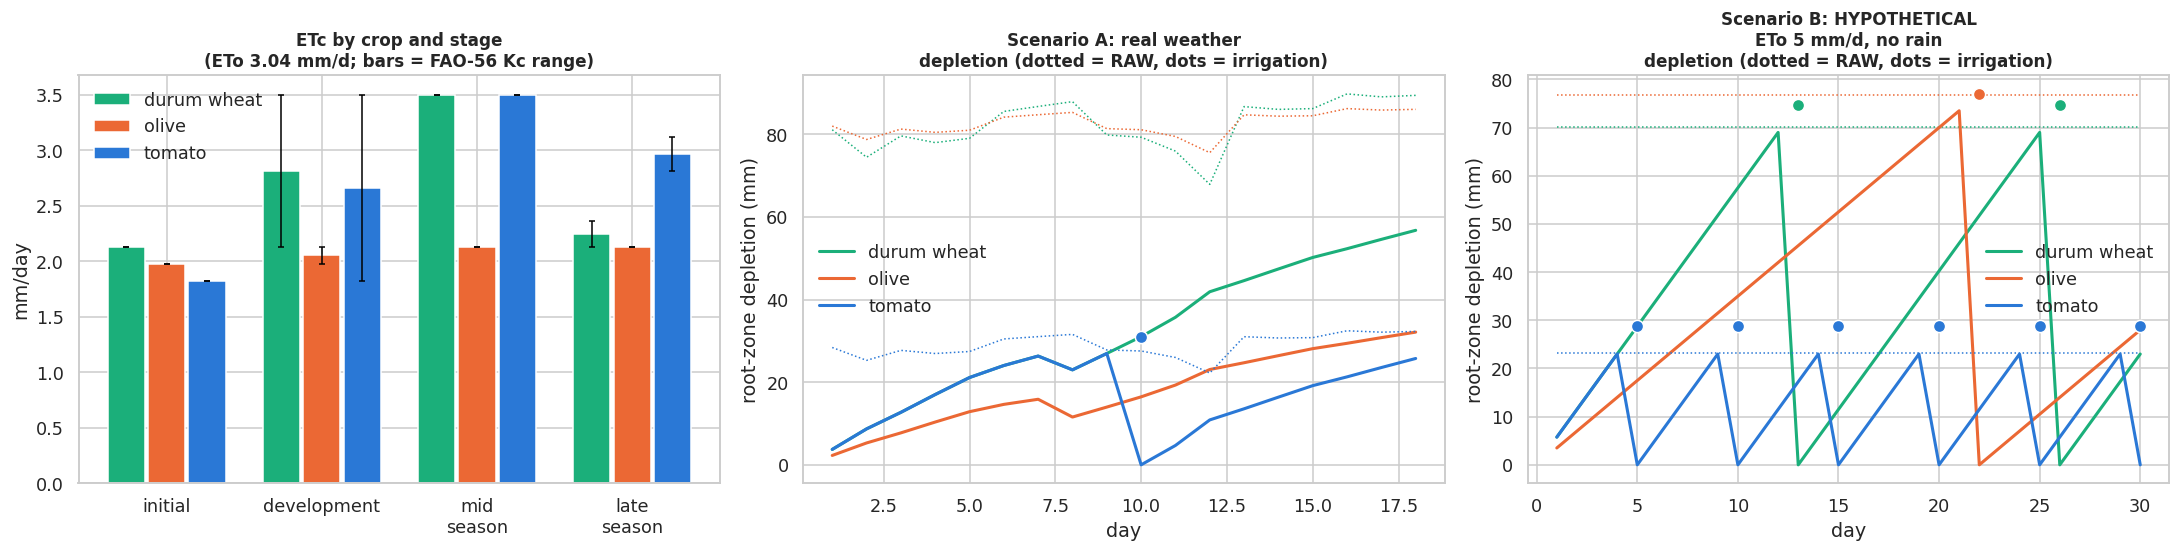

In [29]:
CMP_SOIL, CMP_SYSTEM, CMP_STAGE = get_illustrative_soil('loamy_sand'), typical_system('drip'), 'mid_season'
stage_etc_df = pd.DataFrame(); cmp_sim = pd.DataFrame(); cmp_summary = pd.DataFrame()
if WEATHER_OK:
    scenarios = {}
    run_a = weather_for_sim.copy()
    scenarios['A_real_NASA_POWER_weather'] = (run_a, weather_source)
    b = pd.DataFrame({'date': pd.date_range('2026-07-01', periods=30), 'eto_mm': 5.0, 'rain_mm': 0.0})
    scenarios['B_hypothetical_ETo5_no_rain'] = (b, 'HYPOTHETICAL_SCENARIO_NOT_AN_OBSERVATION')

    # (1) ETc by crop and stage under the mean valid ETo of scenario A
    valid_a = run_a.dropna(subset=['eto_mm', 'rain_mm'])
    eto_ref = float(valid_a['eto_mm'].mean())
    rows = []
    for crop in list_crops():
        for st in STAGES:
            k = CROPS[crop].stages[st]
            rows.append({'crop': crop, 'stage': st, 'kc': k.kc, 'kc_low': k.kc_low, 'kc_high': k.kc_high, 'kc_provenance': k.provenance,
                         'eto_mm': eto_ref, 'etc_mm': eto_ref * k.kc, 'etc_low_mm': eto_ref * k.kc_low, 'etc_high_mm': eto_ref * k.kc_high,
                         'weather_source': weather_source})
    stage_etc_df = pd.DataFrame(rows)
    stage_etc_df.to_csv(RESULTS_DIR / 'crop_comparison_stage_etc.csv', index=False)

    # (2) water-balance simulations
    sims, summ = [], []
    for sc, (wdf, src) in scenarios.items():
        for crop in list_crops():
            s = simulate_water_balance(wdf, crop, CMP_STAGE, CMP_SOIL, CMP_SYSTEM, initial_depletion_mm=0.0, on_gap='truncate')
            rep = conservation_report(s, 0.0)
            assert abs(rep['closure_error_mm']) < 1e-6, 'water balance does not close'
            s.insert(0, 'day', range(1, len(s) + 1)); s.insert(0, 'crop', crop); s.insert(0, 'scenario', sc)
            s['weather_source'] = src; s['soil_source'] = CMP_SOIL.source; s['stage'] = CMP_STAGE
            sims.append(s)
            ev = s[s['irrigation_net_mm'] > 0]
            summ.append({'scenario': sc, 'crop': crop, 'stage': CMP_STAGE, 'days': len(s), 'Kc': s['kc'].iloc[0], 'Zr_m': CROPS[crop].root_depth_m,
                         'TAW_mm': s['TAW_mm'].iloc[0], 'RAW_mm_mean': s['RAW_mm'].mean(), 'total_ETc_mm': s['etc_mm'].sum(),
                         'total_ETa_mm': s['eta_mm'].sum(), 'min_Ks': s['ks'].min(), 'irrigation_events': len(ev),
                         'first_irrigation_day': int(ev['day'].iloc[0]) if len(ev) else None,
                         'total_net_mm': s['irrigation_net_mm'].sum(), 'total_gross_mm': s['irrigation_gross_mm'].sum(),
                         'closure_error_mm': rep['closure_error_mm'], 'weather_source': src})
    cmp_sim, cmp_summary = pd.concat(sims, ignore_index=True), pd.DataFrame(summ)
    cmp_sim.to_csv(RESULTS_DIR / 'irrigation_simulation_daily.csv', index=False)
    cmp_summary.to_csv(RESULTS_DIR / 'crop_comparison_summary.csv', index=False)
    print(f'Reference ETo for the stage table (scenario A mean of {len(valid_a)} valid days): {eto_ref:.2f} mm/day\n')
    print(cmp_summary.round(2).to_string(index=False))
    print('\nSimulation assumptions:'); [print('  -', a) for a in s.attrs['assumptions']]

    # (3) figure
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
    w = 0.26
    for j, crop in enumerate(list_crops()):
        sub = stage_etc_df[stage_etc_df['crop'] == crop]
        xs = np.arange(len(STAGES)) + (j - 1) * w
        axes[0].bar(xs, sub['etc_mm'], width=w - 0.02, color=CROP_COLORS[crop], label=crop.replace('_', ' '))
        axes[0].errorbar(xs, sub['etc_mm'], yerr=[sub['etc_mm'] - sub['etc_low_mm'], sub['etc_high_mm'] - sub['etc_mm']], fmt='none', ecolor='k', lw=1, capsize=2)
    axes[0].set_xticks(range(len(STAGES))); axes[0].set_xticklabels([s_.replace('_', '\n') for s_ in STAGES])
    axes[0].set_title(f'ETc by crop and stage\n(ETo {eto_ref:.2f} mm/d; bars = FAO-56 Kc range)', fontweight='bold', fontsize=11); axes[0].set_ylabel('mm/day'); axes[0].legend(frameon=False)
    for ax_, sc, ttl in ((axes[1], 'A_real_NASA_POWER_weather', 'Scenario A: real weather'), (axes[2], 'B_hypothetical_ETo5_no_rain', 'Scenario B: HYPOTHETICAL\nETo 5 mm/d, no rain')):
        for crop in list_crops():
            g = cmp_sim[(cmp_sim['scenario'] == sc) & (cmp_sim['crop'] == crop)]
            ax_.plot(g['day'], g['dr_end_mm'], color=CROP_COLORS[crop], lw=2, label=crop.replace('_', ' '))
            ax_.plot(g['day'], g['RAW_mm'], color=CROP_COLORS[crop], lw=1, ls=':')
            ev = g[g['irrigation_net_mm'] > 0]
            ax_.plot(ev['day'], ev['dr_before_irrigation_mm'], 'o', color=CROP_COLORS[crop], ms=8, mec='white')
        ax_.set_title(ttl + '\ndepletion (dotted = RAW, dots = irrigation)', fontweight='bold', fontsize=11); ax_.set_xlabel('day'); ax_.set_ylabel('root-zone depletion (mm)'); ax_.legend(frameon=False)
    plt.tight_layout(); plt.savefig(FIGURES_DIR / 'crop_comparison.png', dpi=130, bbox_inches='tight'); plt.show()
else:
    print('Skipped: no valid weather (see 12C).')

## 12E. 🎮 Interactive irrigation demonstration

Choose crop, growth stage, soil (illustrative preset, your own measured FC/WP, or *not provided*), irrigation system, current soil moisture, ETo, previous rainfall/irrigation. The engine prints the ten requested items and **withholds any volume** when an input is missing or the sensors contradict the declared soil.

**How the three depths are used:** 10/30/60 cm readings are combined into a thickness-weighted root-zone mean (each probe represents the layer around it). If the root zone is deeper than the deepest supported layer, the deepest reading is extrapolated and flagged. Values must be **calibrated for the soil** (probe VWC vs. gravimetric samples, plus measured FC/WP) before any operational use.

**Forecast integration:** the selected 1-hour soil-moisture forecast replaces the 10 cm reading in the profile (other depths held constant), and crop demand is projected over the horizon. Because the honest model selection chose *persistence*, the forecast currently equals the latest reading; the interface is ready for a better model if one ever wins the benchmark.

In [30]:
# ---- inputs taken from the existing pipeline (latest hourly sensor row, selected 1 h model) -------------
latest = cm_piv.iloc[-1]; latest_ts = cm_piv.index[-1]
SENSOR_DEPTHS = {10: float(latest['VWC_10cm']), 30: float(latest['VWC_30cm']), 60: float(latest['VWC_60cm'])}
try:
    X_latest = feat_df[feature_cols].iloc[[-1]]
    assert not X_latest.isna().any().any()
    fc_10cm_1h = float(np.ravel(best_estimator.predict(X_latest))[0])
except Exception as e:
    fc_10cm_1h = None; print('Forecast unavailable:', e)
weather_age_days = (latest_ts.normalize() - last_valid_date).days if WEATHER_OK else None
eto_default = round(last_valid_eto, 2) if WEATHER_OK else None
print(f"Latest sensor reading {latest_ts}: {SENSOR_DEPTHS} % | 1 h forecast at 10 cm ({selected_name}): {fc_10cm_1h}")
print(f"ETo default {eto_default} mm/d from {last_valid_date.date() if WEATHER_OK else 'n/a'} (weather is {weather_age_days} day(s) older than the sensor reading)")

SOIL_MENU = {'loamy_sand (illustrative FAO-56 Ex.36)': 'loamy_sand', 'silt (illustrative FAO-56 Ex.36)': 'silt',
             'silty_clay (illustrative FAO-56 Ex.36)': 'silty_clay', 'custom measured FC/WP': 'custom', 'not provided': None}

def run_irrigation_demo(crop='tomato', stage='mid_season', soil_choice='loamy_sand (illustrative FAO-56 Ex.36)',
                        custom_fc=0.0, custom_wp=0.0, method='drip', ea_override=0.0,
                        vwc_10=None, vwc_30=None, vwc_60=None, eto_today=None, rain_last_24h=0.0,
                        irrigation_gross_last=0.0, irrigation_hours_ago=0.0, zr_m=0.0, use_forecast=True,
                        sensor_calibrated=False, field_documented=False, verbose=True):
    # NOTE: 0.0 means 'not supplied' for the optional numeric widgets.
    vwc = {10: vwc_10 if vwc_10 is not None else SENSOR_DEPTHS[10], 30: vwc_30 if vwc_30 is not None else SENSOR_DEPTHS[30],
           60: vwc_60 if vwc_60 is not None else SENSOR_DEPTHS[60]}
    eto_in = eto_today if eto_today not in (None, 0.0) else eto_default
    key = SOIL_MENU[soil_choice]
    try:
        if key is None: soil = None
        elif key == 'custom': soil = SoilParams(custom_fc, custom_wp, source='user_declared', note='entered in demo')
        else: soil = get_illustrative_soil(key)
        system = (IrrigationSystem(method, ea_override, 'user_declared') if ea_override else typical_system(method))
        fc_in = {10: fc_10cm_1h} if (use_forecast and fc_10cm_1h is not None) else None
        dec = recommend_irrigation(
            crop=crop, stage=stage, soil=soil, system=system, theta_now_by_depth_cm=vwc, theta_forecast_by_depth_cm=fc_in,
            forecast_horizon_h=1 if fc_in else None, eto_mm_today=eto_in,
            rain_last_24h_mm=rain_last_24h or None,
            last_irrigation={'gross_mm': irrigation_gross_last, 'hours_ago': irrigation_hours_ago} if irrigation_gross_last else None,
            zr_m=zr_m or None, sensor_calibrated=sensor_calibrated, field_documented=field_documented,
            eto_method=(ETO_METHOD_LAST if WEATHER_OK else 'unspecified') if eto_in == eto_default else 'user-entered',
            weather_source=weather_source, weather_age_days=weather_age_days if eto_in == eto_default else None)
    except ValueError as e:
        print('❌ Input rejected:', e); return None
    if verbose:
        f = lambda v, d=1, u='': 'not available' if v is None else f'{v:.{d}f}{u}'
        th_txt = 'n/a' if dec['theta_rz_now'] is None else '%.1f %%' % (100 * dec['theta_rz_now'])
        print('=' * 78)
        print(f"1. Crop / stage      : {dec['crop_fr']} ({dec['crop']}) - {dec['stage']}")
        print(f"2. Kc used           : {dec['kc']:.2f}  [{dec['kc_provenance']}; published range {dec['kc_low']:.2f}-{dec['kc_high']:.2f}]")
        print(f"3. ETo / ETc         : {f(dec['eto_mm'],2,' mm/d')} / {f(dec['etc_mm'],2,' mm/d')}   ({dec['eto_method']})")
        print(f"4. Root-zone status  : source={dec.get('depletion_source','n/a')}; theta_rz={th_txt}; Ks={f(dec['ks_now'],2)}; Zr={dec['zr_m']} m ({dec['zr_source']})")
        print(f"5. TAW / RAW         : {f(dec['taw_mm'],1,' mm')} / {f(dec['raw_mm'],1,' mm')}   (p used {f(dec['p_used'],2)})")
        print(f"6. Current depletion : {f(dec['dr_now_mm'],1,' mm')}   | sensor-forecast {f(dec['dr_forecast_sensor_mm'],1,' mm')} | projected {f(dec['dr_projected_mm'],1,' mm')}")
        print(f"7. Irrigate?         : {dec['irrigate']}  (timing: {dec['timing']}; status: {dec['status']})")
        print(f"8. Net irrigation    : {f(dec['net_mm'],1,' mm')}")
        print(f"9. Gross irrigation  : {f(dec['gross_mm'],1,' mm')}")
        print('10. Explanation      :'); [print('    -', e) for e in dec['explanation']]
        print(f"    Readiness: {dec['readiness']} | confidence: {dec['confidence']}")
        if dec['missing_inputs']: print('    Missing inputs:', dec['missing_inputs'])
        print('    Warnings:'); [print('    !', w) for w in dec['warnings']]
    return dec

# ---- widget UI (falls back silently to the static runs below if ipywidgets is unavailable) ------------
try:
    import ipywidgets as W
    from IPython.display import display
    ui = dict(
        crop=W.Dropdown(options=list_crops(), value='tomato', description='Crop'),
        stage=W.Dropdown(options=list(STAGES), value='mid_season', description='Stage'),
        soil_choice=W.Dropdown(options=list(SOIL_MENU), description='Soil', layout=W.Layout(width='420px')),
        custom_fc=W.FloatText(value=0.0, description='FC m3/m3'), custom_wp=W.FloatText(value=0.0, description='WP m3/m3'),
        method=W.Dropdown(options=list(TYPICAL_EA), value='drip', description='System'),
        ea_override=W.FloatText(value=0.0, description='Ea (0=typ.)'),
        vwc_10=W.FloatText(value=round(SENSOR_DEPTHS[10], 2), description='VWC 10cm %'), vwc_30=W.FloatText(value=round(SENSOR_DEPTHS[30], 2), description='VWC 30cm %'),
        vwc_60=W.FloatText(value=round(SENSOR_DEPTHS[60], 2), description='VWC 60cm %'),
        eto_today=W.FloatText(value=eto_default or 0.0, description='ETo mm/d'), rain_last_24h=W.FloatText(value=0.0, description='Rain 24h mm'),
        irrigation_gross_last=W.FloatText(value=0.0, description='Last irr. mm'), irrigation_hours_ago=W.FloatText(value=0.0, description='...h ago'),
        zr_m=W.FloatText(value=0.0, description='Zr m (0=FAO)'), use_forecast=W.Checkbox(value=True, description='use soil-moisture forecast'),
        sensor_calibrated=W.Checkbox(value=False, description='sensors calibrated'), field_documented=W.Checkbox(value=False, description='crop/field documented'))
    out = W.interactive_output(run_irrigation_demo, ui)
    display(W.VBox([W.HBox([ui['crop'], ui['stage'], ui['soil_choice']]), W.HBox([ui['custom_fc'], ui['custom_wp'], ui['method'], ui['ea_override']]),
                    W.HBox([ui['vwc_10'], ui['vwc_30'], ui['vwc_60'], ui['eto_today']]), W.HBox([ui['rain_last_24h'], ui['irrigation_gross_last'], ui['irrigation_hours_ago'], ui['zr_m']]),
                    W.HBox([ui['use_forecast'], ui['sensor_calibrated'], ui['field_documented']]), out]))
except Exception as e:
    print('ipywidgets UI not available (', e, ') - see the static demonstrations below.')

Latest sensor reading 2026-11-21 18:00:00: {10: 13.0, 30: 5.7, 60: 7.0} % | 1 h forecast at 10 cm (Persistence Baseline): 13.0
ETo default 1.91 mm/d from 2026-11-18 (weather is 3 day(s) older than the sensor reading)


In [31]:
# ---- Static demonstration 1: the same sensor state, three crops (declared loamy-sand preset, drip) ----------
print('DEMO 1 - latest Chott Meriam profile, SAME soil/system/weather, different crops (illustrative: crop & field undocumented)\n')
demo_rows = []
if WEATHER_OK:
    for crop in list_crops():
        d = run_irrigation_demo(crop=crop, stage='mid_season', verbose=(crop == 'tomato'))
        if d:
            demo_rows.append({'case': 'same_sensor_3_crops', **{k: v for k, v in d.items() if k not in ('warnings', 'explanation', 'missing_inputs')},
                              'warnings': ' | '.join(d['warnings']), 'explanation': ' | '.join(d['explanation']), 'missing_inputs': '; '.join(d['missing_inputs'])})
    tbl = pd.DataFrame(demo_rows)[['crop', 'kc', 'etc_mm', 'taw_mm', 'raw_mm', 'dr_now_mm', 'timing', 'net_mm', 'gross_mm', 'readiness']]
    print('\nSummary for the three crops:\n' + tbl.round(2).to_string(index=False))

    print('\n\nDEMO 2 - why soil parameters matter: tomato, identical sensors, three declared soils')
    for key in ['loamy_sand (illustrative FAO-56 Ex.36)', 'silt (illustrative FAO-56 Ex.36)', 'silty_clay (illustrative FAO-56 Ex.36)']:
        d = run_irrigation_demo(crop='tomato', soil_choice=key, verbose=False)
        print(f"  {key:<42} -> status {d['status']:<26} timing {str(d['timing']):<12} net {d['net_mm'] if d['net_mm'] is None else round(d['net_mm'],1)}")
        demo_rows.append({'case': 'soil_sensitivity_tomato', **{k: v for k, v in d.items() if k not in ('warnings', 'explanation', 'missing_inputs')},
                          'soil_choice': key, 'warnings': ' | '.join(d['warnings']), 'explanation': ' | '.join(d['explanation']), 'missing_inputs': '; '.join(d['missing_inputs'])})

    print('\n\nDEMO 3 - missing soil parameters: no quantitative volume is produced')
    d = run_irrigation_demo(crop='olive', soil_choice='not provided')
    demo_rows.append({'case': 'missing_soil_olive', **{k: v for k, v in d.items() if k not in ('warnings', 'explanation', 'missing_inputs')},
                      'warnings': ' | '.join(d['warnings']), 'explanation': ' | '.join(d['explanation']), 'missing_inputs': '; '.join(d['missing_inputs'])})
    pd.DataFrame(demo_rows).to_csv(RESULTS_DIR / 'irrigation_decision_demo.csv', index=False)
    print('\n💾 saved', RESULTS_DIR / 'irrigation_decision_demo.csv')
else:
    print('Skipped: no valid weather.')

DEMO 1 - latest Chott Meriam profile, SAME soil/system/weather, different crops (illustrative: crop & field undocumented)

1. Crop / stage      : Tomate (tomato) - mid_season
2. Kc used           : 1.15  [FAO56_TABLE; published range 1.15-1.15]
3. ETo / ETc         : 1.91 mm/d / 2.20 mm/d   (Hargreaves_Samani(fallback))
4. Root-zone status  : source=multi-depth sensor profile; theta_rz=8.2 %; Ks=0.51; Zr=0.7 m (FAO56_TABLE22_lower_bound)
5. TAW / RAW         : 63.0 mm / 32.3 mm   (p used 0.51)
6. Current depletion : 47.2 mm   | sensor-forecast 47.2 mm | projected 49.4 mm
7. Irrigate?         : True  (timing: NOW; status: OK)
8. Net irrigation    : 47.2 mm
9. Gross irrigation  : 52.5 mm
10. Explanation      :
    - Depletion 47.2 mm >= RAW 32.3 mm: crop is at/after the stress threshold (Ks=0.51).
    - Crop: Tomato / mid_season: Kc 1.15 x ETo 1.91 = ETc 2.20 mm/day; TAW 63 mm (Zr 0.7 m), p 0.51.
    - Net 47.2 mm refills the root zone to field capacity; gross 52.5 mm at Ea 0.90.
    Rea

## 12F. 📊 Crop-specific irrigation dashboard
One screen for the hackathon jury: current vs forecast soil moisture, selected crop/stage, estimated crop water use, root-zone status, recommendation, volume, and explicit data-quality warnings. Colours: crops use fixed slots of a colour-blind-validated palette; status colours always come with a text label. The earlier dashboard (Section 12) is untouched.

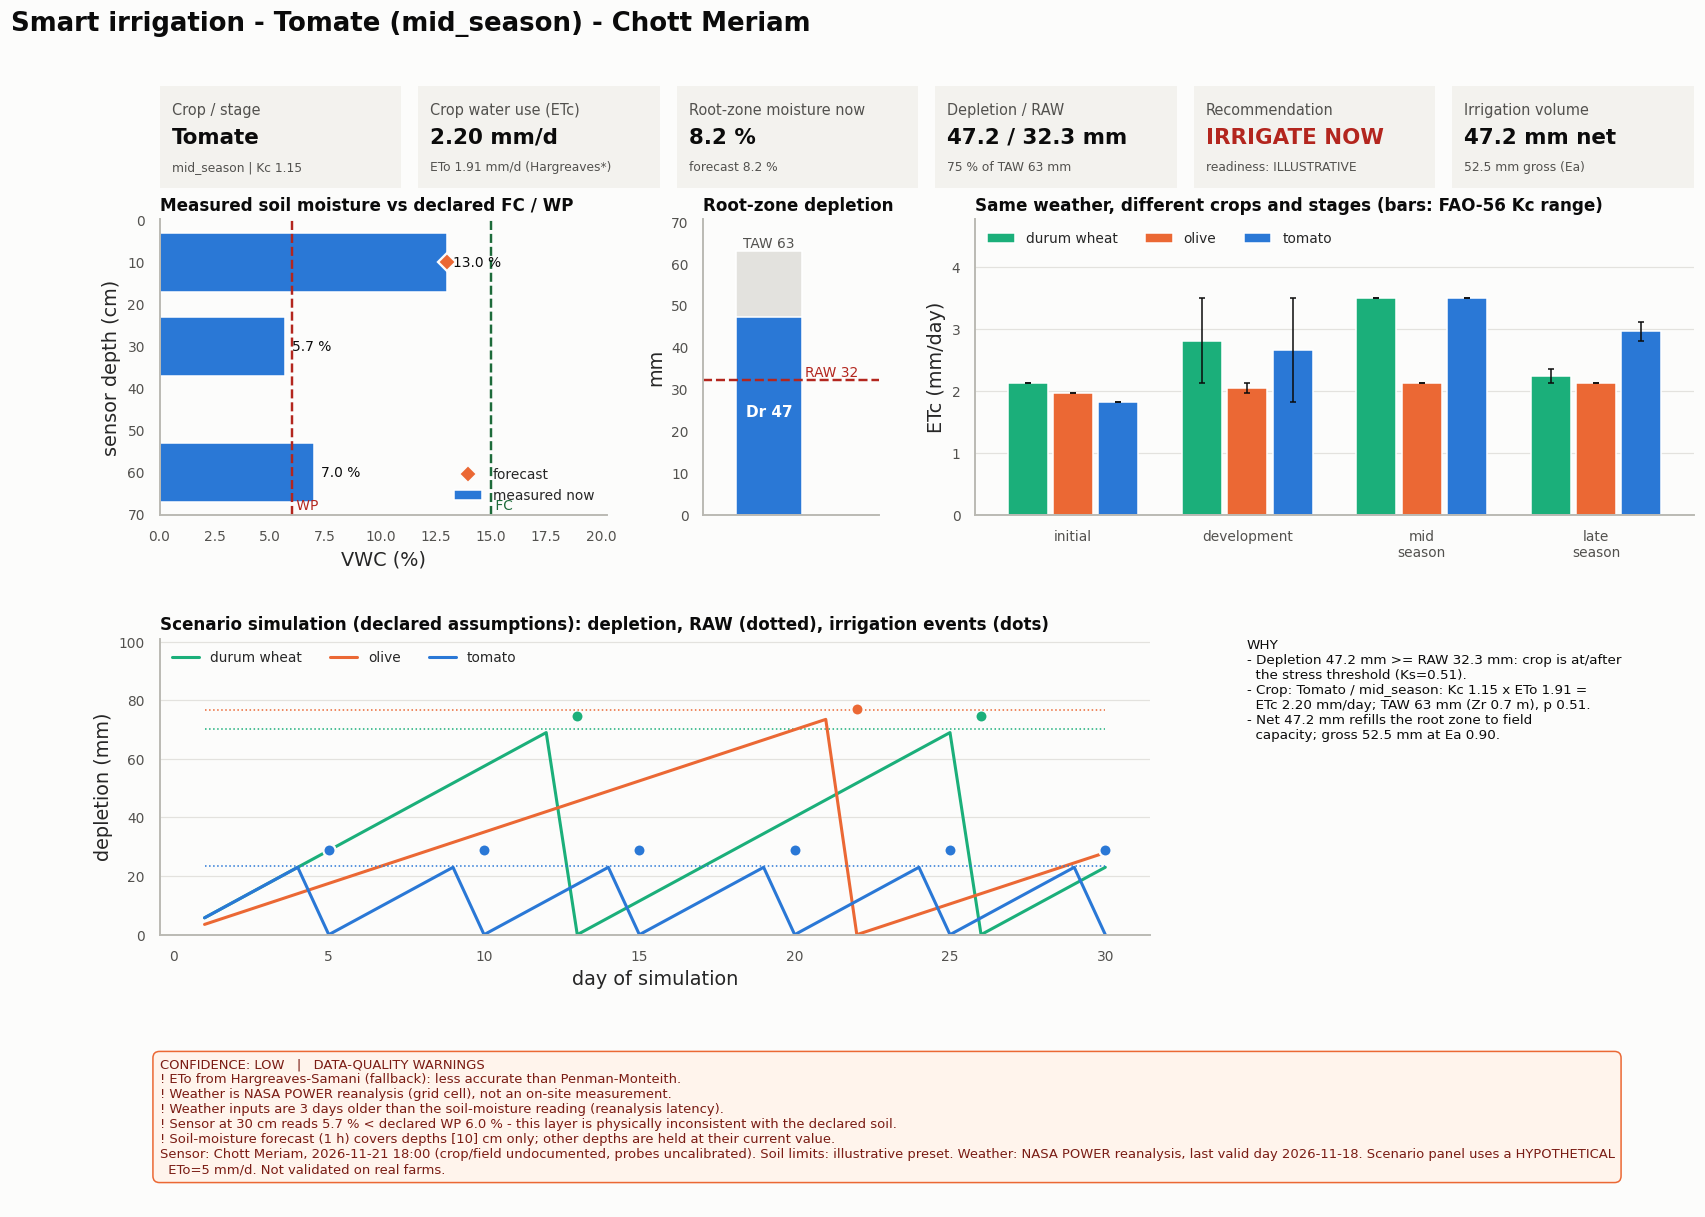

In [32]:
DASH_CROP, DASH_STAGE = 'tomato', 'mid_season'
if WEATHER_OK and len(cmp_sim):
    dec = run_irrigation_demo(crop=DASH_CROP, stage=DASH_STAGE, verbose=False)
    soil_d = get_illustrative_soil('loamy_sand')
    prof = root_zone_theta(SENSOR_DEPTHS, dec['zr_m'], 'percent')
    note = (f"Sensor: Chott Meriam, {latest_ts:%Y-%m-%d %H:%M} (crop/field undocumented, probes uncalibrated). Soil limits: illustrative preset. "
            f"Weather: NASA POWER reanalysis, last valid day {last_valid_date.date()}. Scenario panel uses a HYPOTHETICAL ETo=5 mm/d. Not validated on real farms.")
    fig = plot_dashboard(dec, soil=soil_d, profile_now=prof, theta_fc_by_depth={10: 100 * 0 + fc_10cm_1h} if fc_10cm_1h is not None else None,
                         stage_etc_df=stage_etc_df, sim_df=cmp_sim[cmp_sim['scenario'] == 'B_hypothetical_ETo5_no_rain'],
                         path=FIGURES_DIR / 'crop_irrigation_dashboard.png', title=f'Smart irrigation - {dec["crop_fr"]} ({DASH_STAGE}) - Chott Meriam', data_note=note)
    plt.show()
else:
    print('Skipped: needs weather and comparison results.')

## 12G. ✅ What this section does and does not prove
- ✅ Crop-aware FAO-56 demand (Kc × ETo), source-tagged parameters, transparent root-zone balance that closes to numerical precision, net→gross conversion, refusal to issue volumes when inputs are missing or inconsistent, ETo verified against FAO-56 worked examples, unit tests executed in this run.
- ❌ **Not validated** against measured crop water use, lysimeters, yield or farmer practice in Tunisia. No claim of accuracy is made.
- ❌ Chott Meriam probes are not calibrated and the crop/field is undocumented; FC/WP are unknown. All quantitative outputs for this station are **illustrative**.
- ❌ NASA POWER is reanalysis, not a local station; effective rainfall (P − 2 mm), runoff = 0 and no capillary rise are simplifications.
- ℹ️ ML is **not** claimed superior: persistence won the 1 h benchmark, and the irrigation engine is a knowledge-based FAO-56 model, not a crop classifier.
- ➡️ Next steps: measure FC/WP and calibrate probes on a documented plot, install an on-site weather station, compare recommendations with farmer irrigation logs, calibrate Kc locally (Tunisian studies exist for durum wheat and olive).

## 12H. 📚 Crop knowledge base (searchable, source-tagged, honest about gaps)
`crop_knowledge/crop_database.json` holds **39 crops** transcribed from FAO-56 Tables 11, 12, 22 (37 with complete irrigation parameters; fig and pomegranate are listed but explicitly *unavailable*).
Each parameter carries a source and a confidence label; nothing is marked "locally validated" because **no local validation exists**. Durum wheat uses generic winter-wheat parameters (flagged). ECOCROP/CROPWAT/WaPOR tables could not be retrieved at build time, so environmental requirements are `null` and listed under `missing`.

In [33]:
from engine.crop_retrieval import CropIndex
IX = CropIndex()
print("Autocomplete 'ol'        :", IX.autocomplete('ol'))
print("Search 'blé' / 'قمح'      :", [r['id'] for r in IX.search('blé')], [r['id'] for r in IX.search('قمح')])
print("Search 'agrume' (FR)     :", [r['id'] for r in IX.search('agrume')])
rows = []
for cid in ['tomato', 'olive', 'durum_wheat', 'sweet_pepper', 'potato', 'citrus']:
    c = IX.by_id[cid]; sl = c['stage_lengths_days']
    rows.append({'crop': cid, 'Kc ini/mid/end': f"{c['kc']['ini']:.2f}/{c['kc']['mid']:.2f}/{c['kc']['end']:.2f}", 'Zr range m': f"{c['root_depth']['zr_min_m']}-{c['root_depth']['zr_max_m']}",
                 'p': c['depletion_fraction_p']['value'], 'stages d (ini/dev/mid/late)': f"{sl['ini']}/{sl['dev']}/{sl['mid']}/{sl['late']}" if sl else 'missing',
                 'Kc confidence': c['confidence']['kc'], 'missing fields': len(c['missing'])})
print(pd.DataFrame(rows).to_string(index=False))
print("\nCrops without usable irrigation parameters:", [c['id'] for c in IX.db['crops'] if not c['irrigation_ready']])
print("Durum wheat notes:", *IX.by_id['durum_wheat']['irrigation_notes'], sep='\n  - ')
print("\nCompleteness (tomato):", IX.completeness('tomato'))

Autocomplete 'ol'        : ['Olive']
Search 'blé' / 'قمح'      : ['durum_wheat'] ['durum_wheat']
Search 'agrume' (FR)     : ['citrus']
        crop Kc ini/mid/end Zr range m    p stages d (ini/dev/mid/late)                    Kc confidence  missing fields
      tomato 0.60/1.15/0.80    0.7-1.5 0.40                 30/40/45/30 derived_from_published_reference               5
       olive 0.65/0.70/0.70    1.2-1.7 0.65                 30/90/60/90              directly_documented               5
 durum_wheat 0.70/1.15/0.33    1.5-1.8 0.55                30/140/40/30       generic_crop_approximation               5
sweet_pepper 0.60/1.05/0.90    0.5-1.0 0.30                 30/35/40/20 derived_from_published_reference               5
      potato 0.50/1.15/0.75    0.4-0.6 0.35                 25/30/45/30 derived_from_published_reference               5
      citrus 0.65/0.60/0.65    1.1-1.5 0.50                60/90/120/95              directly_documented               5

Crops without usa

## 12I. 🧭 Farm registry → zone recommendations (what, when, how much)
Minimal farmer input per zone: crop, area, planting date (stage is **estimated** from it and can be corrected with `stage_override`), plus soil FC/WP and irrigation method **if known**. Missing soil/system data is never invented: the zone is reported as `NEEDS_DATA` and its volume is withheld.
The zones below are **DEMO inputs** (declared soils and depletions are illustrative, not measurements). Volumes: m³ = gross mm × ha × 10.

In [34]:
from engine.farm_runner import run_farm
_ok = WEATHER_FARM.copy()
TODAY = str(pd.to_datetime(_ok['date']).max().date())
_d = pd.Timestamp(TODAY)
DEMO_FARM = {
  "farm_id": "demo_farm_notebook",
  "location": {"lat": chott_info['lat'], "lon": chott_info['lon'], "elevation_m": ELEVATION_M},
  "zones": [
    {"zone_id": "Z1", "name": "Durum wheat (sown 20 d ago)", "crop": "blé dur", "area_ha": 2.0, "planting_date": str((_d - pd.Timedelta(days=20)).date()),
     "soil": {"fc": 0.30, "wp": 0.15, "texture": "clay loam (declared, DEMO)", "source": "user_declared"}, "irrigation": {"method": "sprinkler"}, "current_depletion_mm": 40},
    {"zone_id": "Z2", "name": "Olive grove (stage set manually)", "crop": "olive", "area_ha": 1.0, "stage_override": "mid_season",
     "soil": {"fc": 0.22, "wp": 0.10, "texture": "sandy loam (declared, DEMO)", "source": "user_declared"}, "irrigation": {"method": "drip"}, "current_depletion_mm": 118},
    {"zone_id": "Z3", "name": "Citrus (cycle starts 1 Jan)", "crop": "agrumes", "area_ha": 0.8, "planting_date": f"{_d.year}-01-01",
     "soil": {"fc": 0.25, "wp": 0.11, "texture": "loam (declared, DEMO)", "source": "user_declared"}, "irrigation": {"method": "drip"}, "current_depletion_mm": 70},
    {"zone_id": "Z4", "name": "Potato (soil not characterised)", "crop": "potato", "area_ha": 0.3, "planting_date": str((_d - pd.Timedelta(days=35)).date())}
  ]}
_fc = FORECAST_FARM
FARM_RESP = run_farm(DEMO_FARM, WEATHER_FARM, TODAY, _fc, weather_source=f"{WEATHER_SOURCE} | sensors: {DATA_PROVENANCE}", available_water_m3=20.0)
print(f"Date {TODAY} | weather source: {WEATHER_SOURCE} | sensor data provenance: {DATA_PROVENANCE} | ETo methods: {FARM_RESP['eto_methods_in_window']}\n")
tab = []
for z in FARM_RESP['zones']:
    v = z.get('volumes') or {}
    tab.append({'zone': z['zone_id'], 'crop': z.get('crop'), 'status': z['status'], 'stage': z.get('stage'), 'Kc': round(z['kc'], 2) if 'kc' in z else None,
                'ETc mm/d': round(z['etc_mm'], 2) if 'etc_mm' in z else None, 'Zr m': round(z['zr_m'], 2) if 'zr_m' in z else None,
                'TAW': round(z['taw_mm'], 0) if 'taw_mm' in z else None, 'RAW': round(z['raw_mm'], 0) if 'raw_mm' in z else None, 'Dr': round(z['dr_mm'], 0) if 'dr_mm' in z else None,
                'timing': z.get('timing'), 'net mm': round(v['net_mm'], 1) if v.get('net_mm') is not None else None, 'gross mm': round(v['gross_mm'], 1) if v.get('gross_mm') is not None else None,
                'm3': round(v['m3'], 1) if v.get('m3') is not None else None, 'litres': round(v['litres']) if v.get('litres') is not None else None})
print(pd.DataFrame(tab).to_string(index=False))
print("\nWarnings per zone:")
for z in FARM_RESP['zones']:
    print(f"  {z['zone_id']}:", *(z.get('warnings') or ['-']), sep='\n     • ')

Date 2026-11-21 | weather source: open_meteo | sensor data provenance: REAL_DGACTA | ETo methods: ['FAO56_Penman_Monteith']

zone        crop              status       stage   Kc  ETc mm/d  Zr m   TAW   RAW    Dr                              timing  net mm  gross mm     m3    litres
  Z1 durum_wheat                  OK     initial 0.70      1.85  0.44  66.0  45.0  40.0              irrigate_within_4_days    47.7      63.6 1271.1 1271119.0
  Z2       olive                  OK  mid_season 0.70      1.85  1.20 144.0 112.0 118.0                        irrigate_now   118.0     131.1 1311.1 1311111.0
  Z3      citrus                  OK late_season 0.63      1.66  1.10 154.0  98.0  70.0 no_irrigation_needed_within_horizon     0.0       0.0    0.0       0.0
  Z4      potato MISSING_SOIL_PARAMS development 0.72      1.90  0.36   NaN   NaN   NaN                                None     NaN       NaN    NaN       NaN

Warnings per zone:
  Z1:
     • Stage estimated from FAO-56 example stage lengt

## 12J. 🚦 Farm-wide prioritisation (HIGH / MEDIUM / LOW) with explanation
The rank is **not** Dr/RAW alone: it combines stress proximity, days until RAW is reached (with forecast rain), stage sensitivity, buffer (TAW) and a data-quality penalty. The weights are **design choices, not calibrated** (documented in `engine/prioritization.py`). Zones that cannot be computed are listed separately as `NEEDS_DATA`, never silently ranked last.

In [35]:
rk = pd.DataFrame(FARM_RESP['ranking'])
print(rk.to_string(index=False) if len(rk) else "no rankable zone")
print("\nNEEDS_DATA:", *[f"{n['zone_id']} ({n['status']}; missing {n['missing_inputs']})" for n in FARM_RESP['needs_data']], sep='\n  - ')
print("\nWeights (design choices):", FARM_RESP['ranking_weights'])

 rank zone_id  level  score                                                                                                                                              explanation
    1      Z2   HIGH 0.7020                                                                                           Dr/RAW = 1.06; days to RAW: now; stage: mid_season; TAW 144 mm
    2      Z1 MEDIUM 0.3974 Dr/RAW = 0.89; days to RAW: 4; stage: initial; TAW 66 mm; forecast rain 0 mm lowers urgency; depletion/stage rests on assumptions (data-quality penalty)
    3      Z3 MEDIUM 0.2892                        Dr/RAW = 0.72; days to RAW: >horizon; stage: late_season; TAW 154 mm; depletion/stage rests on assumptions (data-quality penalty)

NEEDS_DATA:
  - Z4 (MISSING_SOIL_PARAMS; missing ['soil.fc/wp'])

Weights (design choices): {'stress': 0.5, 'urgency': 0.2, 'stage': 0.15, 'buffer': 0.1, 'rain_relief': -0.15, 'data_quality': -0.1}


## 12K. 💧 Limited-water example: 20 m³ for the zones that have complete inputs
Strategy (documented, deterministic, **not claimed optimal** and not a yield model): *phase 1 – protect*: in rank order, give each zone the gross volume that brings Dr back to RAW; *phase 2 – refill*: spend what remains in rank order toward field capacity. Shortfalls and the residual depletion are reported.

In [36]:
A = FARM_RESP['allocation']
print(f"Available {A['available_m3']} m3 | allocated {A['allocated_m3']} m3 | unallocated {A['unallocated_m3']} m3 | strategy: {A['strategy']}\n")
al = pd.DataFrame(A['plan'])[['zone_id', 'rank', 'level', 'area_ha', 'full_need_gross_m3', 'allocated_m3', 'gross_mm_applied', 'net_mm_applied', 'dr_mm', 'raw_mm', 'residual_dr_mm', 'still_beyond_raw', 'fully_satisfied']]
print(al.round(2).to_string(index=False))
print("Zones without volume inputs:", A['zones_without_volume_inputs'])

Available 20.0 m3 | allocated 20.0 m3 | unallocated 0.0 m3 | strategy: two-phase protect-then-refill in priority order (heuristic; not optimised, no yield response)

zone_id  rank  level  area_ha  full_need_gross_m3  allocated_m3  gross_mm_applied  net_mm_applied  dr_mm  raw_mm  residual_dr_mm  still_beyond_raw  fully_satisfied
     Z2     1   HIGH      1.0             1311.11          20.0               2.0             1.8  118.0  111.74           116.2              True            False
     Z1     2 MEDIUM      2.0             1271.12           0.0               0.0             0.0   40.0   44.73            40.0             False            False
     Z3     3 MEDIUM      0.8                0.00           0.0               0.0             0.0   70.0   97.56            70.0             False             True
Zones without volume inputs: []


## 12L. 🔮 Soil-moisture forecasting vs persistence (new, dependency-light predictor)
`engine/soil_moisture_predictor.py`: chronological split, gap-aware lagged features, per-horizon ridge (numpy) **kept only if** it beats persistence by ≥ 5 % MAE on the held-out block. With fewer than 200 gap-free rows per horizon it reports `INSUFFICIENT_DATA` and persistence stays the answer. This complements (does not replace) the original benchmark in section 8–10.

In [37]:
from engine import soil_moisture_predictor as SMP
PRED_RESULTS = {}
for col in [c for c in cm_piv.columns if c.startswith('VWC_')]:
    h = SMP.to_hourly(cm_piv.reset_index().rename(columns={'index': 'timestamp'}) if 'timestamp' not in cm_piv.reset_index().columns else cm_piv.reset_index(), 'timestamp', col)
    PRED_RESULTS[col] = SMP.evaluate(h)
rows = []
for col, r in PRED_RESULTS.items():
    for hk, v in r['horizons'].items():
        rows.append({'channel': col, 'horizon': hk, 'status': v['status'], 'gap-free rows': v['rows'], 'MAE persistence': round(v.get('mae_persistence', float('nan')), 4), 'MAE ridge': round(v.get('mae_ridge', float('nan')), 4), 'winner': v['winner']})
print(f"Data provenance of the series: {DATA_PROVENANCE}\n")
print(pd.DataFrame(rows).to_string(index=False))
print("\nRule:", next(iter(PRED_RESULTS.values()))['selection_rule'])

Data provenance of the series: REAL_DGACTA

 channel horizon            status  gap-free rows  MAE persistence  MAE ridge      winner
VWC_10cm      1h INSUFFICIENT_DATA             93              NaN        NaN persistence
VWC_10cm      6h INSUFFICIENT_DATA             85              NaN        NaN persistence
VWC_10cm     24h INSUFFICIENT_DATA             78              NaN        NaN persistence
VWC_30cm      1h INSUFFICIENT_DATA             93              NaN        NaN persistence
VWC_30cm      6h INSUFFICIENT_DATA             85              NaN        NaN persistence
VWC_30cm     24h INSUFFICIENT_DATA             78              NaN        NaN persistence
VWC_60cm      1h INSUFFICIENT_DATA             76              NaN        NaN persistence
VWC_60cm      6h INSUFFICIENT_DATA             68              NaN        NaN persistence
VWC_60cm     24h INSUFFICIENT_DATA             65              NaN        NaN persistence

Rule: ridge kept only if test MAE improves on persisten

## 12M. 📊 Farm-wide dashboard (overview · priority board · zone details · projections · allocation)

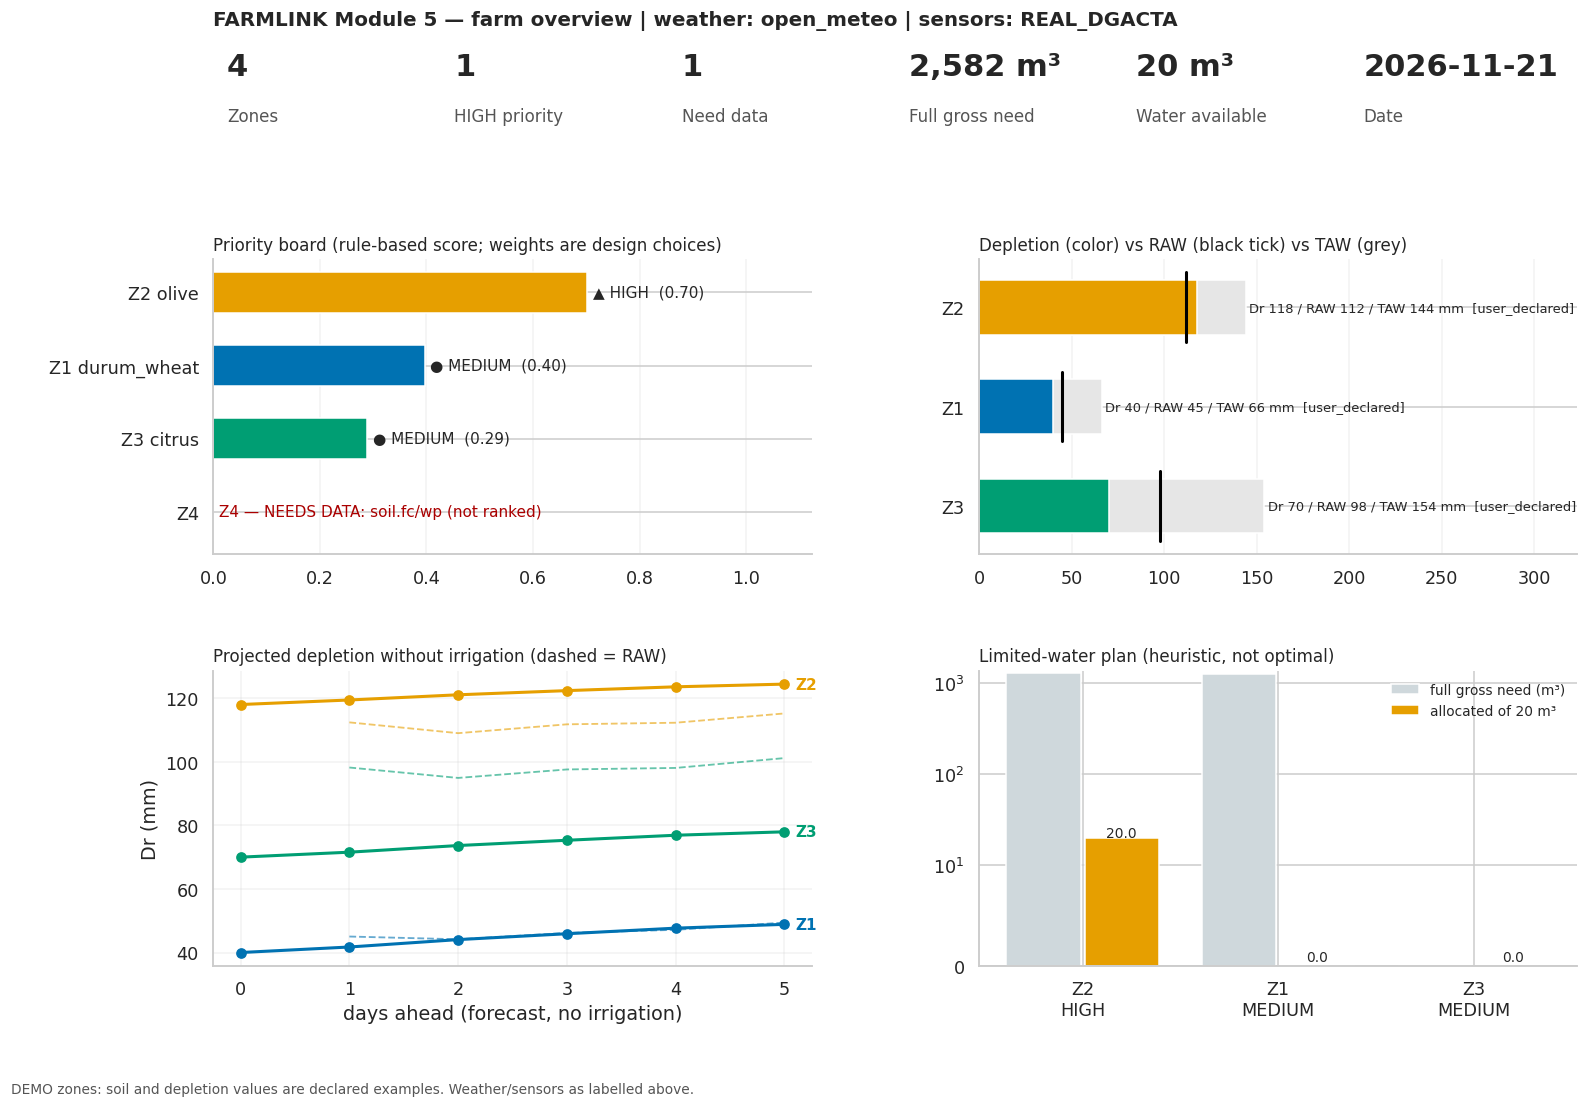

saved /kaggle/working/results/figures/farm_dashboard.png


In [38]:
import matplotlib.pyplot as plt
OKABE = {'Z1': '#0072B2', 'Z2': '#E69F00', 'Z3': '#009E73', 'Z4': '#CC79A7'}
LEVEL_TXT = {'HIGH': '▲ HIGH', 'MEDIUM': '● MEDIUM', 'LOW': '▼ LOW'}
zs = {z['zone_id']: z for z in FARM_RESP['zones']}
ranked = [zs[r['zone_id']] for r in FARM_RESP['ranking']]
fig = plt.figure(figsize=(16, 11)); fig.patch.set_facecolor('white')
gs = fig.add_gridspec(3, 2, height_ratios=[0.55, 1.5, 1.5], hspace=0.5, wspace=0.28)
# overview tiles
axk = fig.add_subplot(gs[0, :]); axk.axis('off')
n_hi = sum(r['level'] == 'HIGH' for r in FARM_RESP['ranking']); tot_m3 = sum((z.get('volumes') or {}).get('m3') or 0 for z in FARM_RESP['zones'])
tiles = [("Zones", f"{len(FARM_RESP['zones'])}"), ("HIGH priority", f"{n_hi}"), ("Need data", f"{len(FARM_RESP['needs_data'])}"),
         ("Full gross need", f"{tot_m3:,.0f} m³"), ("Water available", f"{FARM_RESP['allocation']['available_m3']:.0f} m³"), ("Date", TODAY)]
for i, (k, v) in enumerate(tiles):
    x = i / len(tiles)
    axk.text(x + 0.01, 0.62, v, fontsize=20, weight='bold', transform=axk.transAxes); axk.text(x + 0.01, 0.2, k, fontsize=11, color='#555', transform=axk.transAxes)
axk.set_title(f"FARMLINK Module 5 — farm overview | weather: {WEATHER_SOURCE} | sensors: {DATA_PROVENANCE}", loc='left', fontsize=13, weight='bold')
# priority board
ax = fig.add_subplot(gs[1, 0])
names = [f"{z['zone_id']} {z['crop']}" for z in ranked][::-1]; sc = [r['score'] for r in FARM_RESP['ranking']][::-1]
cols = [OKABE[z['zone_id']] for z in ranked][::-1]
ax.barh(names, sc, color=cols, height=0.55)
for i, r in enumerate(FARM_RESP['ranking'][::-1]):
    ax.text(r['score'] + 0.01, i, f"{LEVEL_TXT[r['level']]}  ({r['score']:.2f})", va='center', fontsize=10)
for j, nd in enumerate(FARM_RESP['needs_data']):
    ax.barh(-1 - j, 0.0001, color='none'); ax.text(0.01, -1 - j, f"{nd['zone_id']} — NEEDS DATA: {', '.join(nd['missing_inputs'] or [])} (not ranked)", va='center', fontsize=10, color='#a00')
ax.set_yticks(list(range(len(names))) + [-1 - j for j in range(len(FARM_RESP['needs_data']))]); ax.set_yticklabels(names + [nd['zone_id'] for nd in FARM_RESP['needs_data']])
ax.set_xlim(0, max(sc + [0.1]) * 1.6); ax.set_title('Priority board (rule-based score; weights are design choices)', loc='left', fontsize=11)
ax.grid(axis='x', alpha=.25); ax.spines[['top', 'right']].set_visible(False)
# zone details: Dr vs RAW vs TAW
ax = fig.add_subplot(gs[1, 1])
for i, z in enumerate(ranked):
    ax.barh(i, z['taw_mm'], color='#e6e6e6', height=0.55); ax.barh(i, z['dr_mm'], color=OKABE[z['zone_id']], height=0.55)
    ax.plot([z['raw_mm']] * 2, [i - 0.35, i + 0.35], color='black', lw=2)
    ax.text(z['taw_mm'] + 2, i, f"Dr {z['dr_mm']:.0f} / RAW {z['raw_mm']:.0f} / TAW {z['taw_mm']:.0f} mm  [{z['depletion_source']}]", va='center', fontsize=8.5)
ax.set_yticks(range(len(ranked))); ax.set_yticklabels([z['zone_id'] for z in ranked]); ax.invert_yaxis(); ax.set_xlim(0, max(z['taw_mm'] for z in ranked) * 2.1)
ax.set_title('Depletion (color) vs RAW (black tick) vs TAW (grey)', loc='left', fontsize=11); ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', alpha=.25)
# projections
ax = fig.add_subplot(gs[2, 0])
for z in ranked:
    pr = z.get('projection') or []
    if pr:
        x = list(range(0, len(pr) + 1)); y = [z['dr_mm']] + [p['dr_end_mm'] for p in pr]
        ax.plot(x, y, marker='o', color=OKABE[z['zone_id']], lw=2); ax.plot(x[1:], [p['raw_mm'] for p in pr], ls='--', color=OKABE[z['zone_id']], alpha=.6, lw=1.2)
        ax.text(x[-1] + 0.1, y[-1], z['zone_id'], color=OKABE[z['zone_id']], fontsize=10, weight='bold', va='center')
ax.set_xlabel('days ahead (forecast, no irrigation)'); ax.set_ylabel('Dr (mm)'); ax.set_title('Projected depletion without irrigation (dashed = RAW)', loc='left', fontsize=11)
ax.grid(alpha=.25); ax.spines[['top', 'right']].set_visible(False)
if not any((z.get('projection') for z in ranked)): ax.text(0.5, 0.5, 'no forecast available', ha='center', transform=ax.transAxes)
# allocation
ax = fig.add_subplot(gs[2, 1]); pl = FARM_RESP['allocation']['plan']
xs = range(len(pl)); ax.bar([i - 0.2 for i in xs], [p['full_need_gross_m3'] for p in pl], 0.38, color='#cfd8dc', label='full gross need (m³)')
ax.bar([i + 0.2 for i in xs], [p['allocated_m3'] for p in pl], 0.38, color=[OKABE[p['zone_id']] for p in pl], label=f"allocated of {FARM_RESP['allocation']['available_m3']:.0f} m³")
ax.set_xticks(list(xs)); ax.set_xticklabels([f"{p['zone_id']}\n{p['level']}" for p in pl]); ax.set_yscale('symlog', linthresh=10)
for i, p in enumerate(pl): ax.text(i + 0.2, p['allocated_m3'] + 0.5, f"{p['allocated_m3']:.1f}", ha='center', fontsize=9)
ax.set_title('Limited-water plan (heuristic, not optimal)', loc='left', fontsize=11); ax.legend(frameon=False, fontsize=9); ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, 0.005, "DEMO zones: soil and depletion values are declared examples. " + ("SYNTHETIC FIXTURE DATA — code-path demonstration only." if 'SYNTHETIC' in f"{WEATHER_SOURCE}{DATA_PROVENANCE}" else "Weather/sensors as labelled above."), fontsize=9, color='#a00' if 'SYNTHETIC' in f"{WEATHER_SOURCE}{DATA_PROVENANCE}" else '#555')
FARM_DASH_PATH = RESULTS_DIR / 'figures' / 'farm_dashboard.png'
fig.savefig(FARM_DASH_PATH, dpi=130, bbox_inches='tight'); plt.show()
print("saved", FARM_DASH_PATH)

## 12N. 📦 Export, fresh-process verification and ZIP
Writes this run's artifacts into the package, runs the **whole test-suite in a fresh interpreter**, runs an end-to-end farm example in a fresh process (JSON out), zips the package, then unzips the ZIP into an empty directory and re-runs the tests there.

In [39]:
import subprocess, tempfile, zipfile, json, hashlib, shutil
(PKG_DIR / 'reports').mkdir(exist_ok=True)
shutil.copyfile(FARM_DASH_PATH, PKG_DIR / 'reports' / 'farm_dashboard.png')
json.dump({"_label": f"Notebook run output. weather={WEATHER_SOURCE}; sensors={DATA_PROVENANCE}. DEMO zones.", "response": FARM_RESP}, open(PKG_DIR / 'api' / 'notebook_run_response.json', 'w'), indent=1, default=str)
SMP.save_metadata(next(iter(PRED_RESULTS.values())), str(PKG_DIR / 'models' / 'predictor_evaluation_latest.json'), {"data_provenance": DATA_PROVENANCE, "channels_evaluated": list(PRED_RESULTS)})
ACQ_DF.to_csv(PKG_DIR / 'reports' / 'acquisition_report.csv', index=False)

def run(cmd, cwd):
    p = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True, timeout=600); return p.returncode, (p.stdout + p.stderr)
rc, out = run([sys.executable, '-I', '-W', 'ignore', '-m', 'unittest', 'discover', '-s', 'tests'], PKG_DIR)
print("FRESH-PROCESS TESTS (package dir):", "PASS" if rc == 0 else "FAIL"); print("   ", out.strip().splitlines()[-3:])

e2e = r"""
import sys, json
sys.path.insert(0, '.'); sys.path.insert(0, 'tests')
from engine.farm_runner import run_farm
from engine.crop_retrieval import CropIndex
from fixtures.synthetic import synthetic_weather
ix = CropIndex(); assert len(ix.db['crops']) >= 30 and ix.get('tomate')['id'] == 'tomato'
w = synthetic_weather('2026-04-01', 60); f = synthetic_weather('2026-05-31', 7, seed=1, rain_days=(3,))
r = run_farm('api/sample_farm.json', w[w.date <= '2026-05-30'], '2026-05-30', f, 'SYNTHETIC_FIXTURE', 20)
json.dump(r, open('e2e_out.json', 'w'))
print('E2E_OK', len(r['zones']), 'zones;', [z['rank'] for z in r['ranking']], 'needs_data:', [n['zone_id'] for n in r['needs_data']])
"""
rc2, out2 = run([sys.executable, '-I', '-c', e2e], PKG_DIR); print("FRESH-PROCESS END-TO-END:", out2.strip().splitlines()[-1]); (PKG_DIR / 'e2e_out.json').unlink(missing_ok=True)

ZIP_PATH = BASE_DIR / 'FARMLINK_Module5_Deliverables.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(PKG_DIR.rglob('*')):
        if p.is_file() and '__pycache__' not in p.parts and p.suffix != '.pyc':
            z.write(p, 'FARMLINK_Module5_Deliverables/' + p.relative_to(PKG_DIR).as_posix())
names = zipfile.ZipFile(ZIP_PATH).namelist()
REQUIRED = ['crop_knowledge/crop_database.json', 'crop_knowledge/crop_parameters.csv', 'crop_knowledge/crop_sources.json', 'models/model_metadata.json',
            'engine/crop_retrieval.py', 'engine/crop_water_requirements.py', 'engine/eto.py', 'engine/water_balance.py', 'engine/irrigation_engine.py', 'engine/prioritization.py',
            'engine/soil_moisture_predictor.py', 'api/api_schema.json', 'api/sample_farm.json', 'api/sample_crop_profile.json', 'api/sample_irrigation_response.json',
            'tests/test_crop_retrieval.py', 'tests/test_crop_completeness.py', 'tests/test_growth_stage.py', 'tests/test_kc.py', 'tests/test_eto.py', 'tests/test_balance_and_irrigation.py',
            'tests/test_ranking_allocation.py', 'tests/test_predictor.py', 'tests/test_data_sources.py', 'README.md', 'requirements.txt']
missing = [r for r in REQUIRED if 'FARMLINK_Module5_Deliverables/' + r not in names]
print(f"ZIP: {ZIP_PATH.name} | {len(names)} files | {ZIP_PATH.stat().st_size/1024:.0f} KB | sha256 {hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()[:16]} | missing required: {missing or 'none'}")
with tempfile.TemporaryDirectory() as td:
    zipfile.ZipFile(ZIP_PATH).extractall(td)
    rc3, out3 = run([sys.executable, '-I', '-W', 'ignore', '-m', 'unittest', 'discover', '-s', 'tests'], Path(td) / 'FARMLINK_Module5_Deliverables')
    print("TESTS INSIDE UNZIPPED ZIP (empty dir, fresh process):", "PASS" if rc3 == 0 else "FAIL", "|", out3.strip().splitlines()[-3:])
EXPORT_OK = (rc == 0 and rc2 == 0 and rc3 == 0 and not missing)
print("\nEXPORT VERIFIED" if EXPORT_OK else "\n❌ EXPORT CHECK FAILED - see lines above")

FRESH-PROCESS TESTS (package dir): PASS
    ['Ran 82 tests in 1.095s', '', 'OK']
FRESH-PROCESS END-TO-END: E2E_OK 4 zones; [1, 2, 3] needs_data: ['Z4']
ZIP: FARMLINK_Module5_Deliverables.zip | 40 files | 242 KB | sha256 7d7f56210b2e7a7c | missing required: none
TESTS INSIDE UNZIPPED ZIP (empty dir, fresh process): PASS | ['Ran 82 tests in 0.635s', '', 'OK']

EXPORT VERIFIED


## 13. 📝 Scientific Conclusions & Technical Roadmap

### Summary of Rigorous Findings
1. **Sensor Resolution & Clean Separation**:
   Our parser successfully decoupled 2,302 physical observations across the 5 DGACTA stations, correctly differentiating Volumetric Water Content ($\text{VWC }\%$), probe electrical potential ($\text{mV}$), and soil temperature ($^\circ\text{C}$), while extracting true depths ($10, 20, 30, 60\text{ cm}$).
2. **Persistence Baseline as the True Winner**:
   On the continuous 170-hour series at Chott Meriam, **Persistence Baseline is the clear winner** ($\text{MAE} = 0.0191\%$, $R^2 = 0.9902$). In the absence of rain or irrigation pulses, soil moisture dries slowly, making persistence an exceptionally strong benchmark that machine learning models cannot surpass on small sample sizes.
3. **Scientific Irrigation Decision Engine**:
   A single surface probe cannot determine volumetric irrigation without field capacity, wilting point, root depth, and application efficiency. The engine accurately returns a diagnostics report when parameters are missing, while demonstrating complete root-zone scheduling under a documented simulation scenario.


### 13B. Addendum – crop-specific irrigation module
Sections 12A–12G add a source-tagged FAO-56 crop database (tomato, olive, durum wheat), a closed root-zone water balance, a decision engine fed by the soil-moisture forecast, a three-crop comparison and a crop dashboard. Limitations are listed in 12G; in particular, the Chott Meriam crop, soil hydraulics and probe calibration are unknown, so quantitative irrigation volumes are illustrative until a documented, calibrated field is available.

### 13C. Addendum – FARMLINK v3 (what the outputs above do and do not establish)
- ✅ Implemented and executed: package install, connectivity probe, hardened acquisition with provenance, engine weather client (source recorded), crop KB search, multi-zone recommendations, ranking, limited-water allocation, predictor-vs-persistence check, farm dashboard, export + fresh-process tests + ZIP.
- ❌ Not established by any run in this notebook unless the printed provenance says `REAL_DGACTA` / a real weather source: real Tunisian sensor data, real weather, calibrated soil moisture, local validation of any Kc/Zr/p value, the Open-Meteo/NASA/CKAN HTTP contracts against the live services (they are unit-tested only against a local mock server).
- Crop parameters are FAO-56 table values (Kc ini often a group default, durum wheat = generic winter wheat). Irrigation depths are **candidates requiring field validation**, not agronomic prescriptions.

## 14. 📚 References & Dataset Licences

1. **Ministère de l'Agriculture, des Ressources Hydrauliques et de la Pêche (Tunisie)**
   - Portal: [catalog.data.gov.tn](https://catalog.data.gov.tn/)
   - Authority: DGACTA (*Direction Générale de l'Aménagement et de la Conservation des Terres Agricoles*)
   - Open Data Licence Tunisie.

2. **NASA POWER Agroclimatology Archive**
   - Service: [power.larc.nasa.gov](https://power.larc.nasa.gov/)
   - MERRA-2 Global Gridded Agroclimatology Reanalysis.

3. **FAO-56 Irrigation and Drainage Paper**
   - Allen, R. G., Pereira, L. S., Raes, D., & Smith, M. (1998). *Crop evapotranspiration: Guidelines for computing crop water requirements*. FAO Irrigation and Drainage Paper 56, Food and Agriculture Organization of the United Nations, Rome.


In [40]:
# ============================================================================
# Final Pipeline Verification
# ============================================================================
print("=" * 75)
print("FINAL PIPELINE AUDIT: GENERATED ARTIFACTS")
print("=" * 75)

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    if folder.exists():
        for item in sorted(folder.iterdir()):
            if item.is_file():
                print(f"  • {item.relative_to(BASE_DIR)}: {item.stat().st_size:,} bytes")

print("\n✅ Kaggle Notebook Generation & Execution Complete!")
print("🇹🇳 🇯🇵 Japan–Tunisia Agricultural Innovation Project.")

FINAL PIPELINE AUDIT: GENERATED ARTIFACTS
  • data/tunisia/Kairouan_ElAlaa_696cd196.csv: 212 bytes
  • data/tunisia/Kairouan_ElAlaa_99862b97.csv: 212 bytes
  • data/tunisia/Kairouan_ElAlaa_Capteur_d_environnement_de_la_station_climatique.csv: 592 bytes
  • data/tunisia/Kairouan_ElAlaa_Capteur_d_humidité_du_sol_à_10_cm_de_la_station_cl.csv: 212 bytes
  • data/tunisia/Kairouan_ElAlaa_Capteur_d_humidité_du_sol_à_20_cm_de_la_station_cl.csv: 212 bytes
  • data/tunisia/Kairouan_ElAlaa_Capteur_d_humidité_du_sol_à_30_cm_de_la_station_cl.csv: 212 bytes
  • data/tunisia/Kairouan_ElAlaa_Capteur_de_pluviométrie_dans_la_station_climatique.csv: 195 bytes
  • data/tunisia/Kairouan_ElAlaa_a921ad82.csv: 212 bytes
  • data/tunisia/Kairouan_ElAlaa_c5eaf60b.csv: 592 bytes
  • data/tunisia/Kairouan_ElAlaa_d264b680.csv: 195 bytes
  • data/tunisia/Kairouan_Sbikha_2b7a78fd.csv: 647 bytes
  • data/tunisia/Kairouan_Sbikha_84c5e601.csv: 1,946 bytes
  • data/tunisia/Kairouan_Sbikha_8d05cb98.csv: 647 bytes
  • dat